# Long-running skills with explicit state

### Chapter 4, notebook 1 of 3

In Chapter 3, we ran a skill once. We selected it, compiled its instructions, generated the output, verified it, and repaired parts that failed. Here we keep a skill running across multiple steps, interruptions, and changes to the task.

The example follows a buyer comparing homes in Seattle, Bellevue, and Kent. A coordinating skill dispatches five specialised agents and collects their results. We stop and resume the investigation, recover from a process failure, and branch from a checkpoint when the buyer changes an assumption.

All model responses come from `openai/gpt-5.6-luna` through OpenRouter, either from live calls or from a recording of a live run. We use King County house sales and Zillow’s Seattle metro series where noted. The hazard scores and insurance scenarios are illustrative. The home comparison gives us a concrete workflow for testing the harness.

| § | What we build or inspect | Chapter section |
|---|---|---|
| 1 | The investigation, the five agents, and the five concepts we’ll use throughout the chapter | 4.1 |
| 2 | Tools for querying the data, the SKILL.state loop, and the same investigation run with a growing transcript | 4.2.1 |
| 3 | `HarnessKernel` as a LangGraph graph, with control points, middleware, `SemanticInterrupt`, execution states, pins, and a recovery policy based on the action’s effect | 4.2.2 |
| 4 | SQLite checkpoints, recovery after a process failure, and audits of the recorded history | 4.2.3 |
| 5 | Three city branches from a shared checkpoint, a suspended branch, and a sub-branch that reuses results that are still valid | 4.2.3 |
| 6 | An approval boundary, an action journal, and an idempotency check for a consequential action | 4.2.3 |
| 7 | The records, audits, and token usage from the run | 4.2.3 |
| 8 | Replay of the recorded run and LangGraph time travel to inspect a step and see where a change takes effect | 4.2.3 |

**The state loop and the harness.** We use the per-step loop from *SKILL.state: Scalable Long-Horizon Agent Skills* (Badhe, Tiwari & Chung, 2026). At each step, the model receives the procedure $P$, the current state $\Sigma_t$, and the latest observation $O_t$. It returns a state patch and an action. The runtime validates and merges the patch and discards the model’s reasoning for that step. We install [`skill_state`](https://github.com/Nicolepcx/skill_state), an independent reference implementation written for the book.

From Section 3 onward, we build the notebook’s harness around that loop. The notebook implements the kernel, middleware, recovery policy, branching logic, artifact store, and action journal. LangGraph provides the graph, SQLite checkpointing, interrupts, and time travel. Section 3 shows how we use those primitives in the harness.

**Replay and live runs.** The notebook starts in replay mode, which uses responses recorded during a live run. You can run it without an API key or model charges. The full live example takes a few hundred model calls across the three city branches, the transcript comparison, the resume, and the sub-branch. Section 7 reports token usage. To make live calls, set `RUN_MODE = "live"` as shown in Sections 0 and 8.

In [ ]:
%pip install -q gdown openai pyyaml pandas numpy matplotlib python-dotenv langgraph langgraph-checkpoint-sqlite

import importlib, os, subprocess, sys

SKILL_STATE_REPO = "https://github.com/Nicolepcx/skill_state"
try:
    import skill_state
except ModuleNotFoundError:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{SKILL_STATE_REPO}"],
                       capture_output=True, text=True)
    if r.returncode != 0:                      # repository without pyproject.toml: use a clone
        if not os.path.isdir("/tmp/skill_state_src"):
            subprocess.run(["git", "clone", "-q", "--depth", "1", SKILL_STATE_REPO,
                            "/tmp/skill_state_src"], check=True)
        sys.path.insert(0, "/tmp/skill_state_src")
    importlib.invalidate_caches()
    import skill_state
print("skill_state from", skill_state.__file__)

skill_state from /usr/local/lib/python3.13/dist-packages/skill_state/__init__.py


## 0. Setup

We load the data and skill files from a shared Google Drive folder, as in Chapter 3. `ch04_data` contains the data the agents query. `ch04_skills` contains the identity, project facts, six skills, and the state schema for the investigation.

The model client implements `complete`, which is required by `skill_state`’s `LLM` protocol. It also provides `start`, which starts a generation that the kernel in Section 3 can read as it streams and stop early. We log usage separately for each model call.

1. **Start with replay mode (`RUN_MODE = "replay"`).** This is the default. The notebook loads model responses from a reference run in `ch04_replay`, so you can run it without an API key or model charges. The tools, kernel, and store still run, and the notebook still injects faults. You’ll see the checkpoints, interrupts, branches, and recoveries as they happen.
2. **Switch to live mode (`RUN_MODE = "live"`) to try your own investigation.** The full notebook makes about 150–200 calls to `openai/gpt-5.6-luna` through OpenRouter. It records your run in `ch04_recordings/nb1_latest.jsonl` so you can replay it later.

The setup cell checks that the recording matches the notebook version and the data and skill files before the run starts. During replay, the client also checks each model prompt against the recording. If you change a constraint, a skill, or the harness and that change reaches a model prompt, replay stops at the first mismatch. Use live mode to see how the model responds to the changed prompt.

In [ ]:
import getpass, hashlib, inspect, json, re, shutil, sqlite3, textwrap, time, uuid
from dataclasses import dataclass, field
from enum import Enum
from pathlib import Path
from typing import Any, Callable, Dict, Iterator, List, Optional, Tuple

import gdown
import numpy as np
import openai
import pandas as pd
import yaml

from skill_state import (LLMResult, ParseError, Skill, SkillStateRuntime, build_prompt,
                         merge, parse_response, validate)

RUN_MODE = "replay"   # "replay": re-run the reference recording, no API key, no model cost.
                      # "live": real model calls through OpenRouter, each one recorded.
REPLAY_FILE = None    # for replay; default: this session's latest recording, else the reference on Drive
NOTEBOOK_VERSION = "ch04-nb1/2026-10-31"   # a recording replays only with the version that made it

DRIVE_FOLDER_URL = ("https://drive.google.com/drive/folders/"
                    "1_zFkQWD8Mjyv_K5cCjMT2w7QTH2ttu1I?usp=sharing")
WORK = Path("ch04_work").resolve()
shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir(parents=True)

kwargs = {"url": DRIVE_FOLDER_URL, "output": str(WORK), "quiet": True, "use_cookies": False}
if "remaining_ok" in inspect.signature(gdown.download_folder).parameters:
    kwargs["remaining_ok"] = True
if not gdown.download_folder(**kwargs):
    raise RuntimeError("Nothing downloaded; is the Drive folder shared with 'Anyone with the link'?")

DATA = next(p for p in WORK.rglob("ch04_data") if p.is_dir())
SKILLS = next(p for p in WORK.rglob("ch04_skills") if p.is_dir())
for folder in (DATA, SKILLS):
    print(folder.name)
    for p in sorted(folder.iterdir()):
        print(f"   {p.name:46}{p.stat().st_size:>10,} bytes")

# --- model access -------------------------------------------------------------------
try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(), override=False)
except Exception:
    pass
if RUN_MODE == "live" and not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass.getpass("OpenRouter API key: ")

MODEL = "openai/gpt-5.6-luna"
BASE_URL = "https://openrouter.ai/api/v1"
USAGE: List[Dict[str, Any]] = []          # one row per model call, including calls stopped early
RECORDER = None                           # set below in live mode
_CALL_IDS = iter(range(1, 10**9))


class Generation:
    """One streamed model call. Iterate it for text pieces. `record` is this call's usage row;
    it is completed and logged once, when the stream ends or is closed early.

    Usage comes from the provider when the stream runs to the end. A stream closed early ends
    before the provider's usage chunk arrives, so its tokens are estimated from characters
    and marked as estimated; the provider may still bill for tokens generated after the close.
    `generation_id` lets section 7 ask the provider for the billed figures."""

    def __init__(self, client, model: str, label: str, prompt: str):
        self.record = {"call": next(_CALL_IDS), "label": label, "model": model, "execution_id": None,
                       "generation_id": None, "prompt_chars": len(prompt), "replayed": False}
        self._prompt, self._parts, self._usage, self._t0 = prompt, [], None, time.perf_counter()
        self._finished, self._complete = False, False
        self._resp = client.chat.completions.create(
            model=model, stream=True, stream_options={"include_usage": True},
            messages=[{"role": "user", "content": prompt}])
        self._gen = self._pieces()

    def _pieces(self) -> Iterator[str]:
        try:
            for chunk in self._resp:
                self.record["generation_id"] = self.record["generation_id"] or getattr(chunk, "id", None)
                if getattr(chunk, "usage", None):
                    self._usage = chunk.usage
                if chunk.choices and chunk.choices[0].delta and chunk.choices[0].delta.content:
                    self._parts.append(chunk.choices[0].delta.content)
                    yield self._parts[-1]
            self._complete = True
        finally:
            self._finish()

    def __iter__(self) -> Iterator[str]:
        return self._gen

    def close(self) -> None:
        self._gen.close()
        self._finish()                      # also covers a stream closed before its first piece

    def _finish(self) -> None:
        if self._finished:
            return
        self._finished = True
        self._resp.close()                  # closing the HTTP response stops the generation
        text, u = "".join(self._parts), self._usage
        self.record.update({
            "prompt_tokens": getattr(u, "prompt_tokens", None) or len(self._prompt) // 4,
            "completion_tokens": getattr(u, "completion_tokens", None) or len(text) // 4,
            "usage_source": "provider" if u else "estimated", "aborted": not self._complete,
            "completion_chars": len(text), "seconds": round(time.perf_counter() - self._t0, 2)})
        USAGE.append(self.record)
        if RECORDER:
            RECORDER.write(self.record, self._prompt, text)


class OpenRouterLLM:
    """skill_state's LLM protocol (`complete`) plus `start`, which the kernel uses to read
    the output while it is generated and to stop it early."""

    def __init__(self, model: str = MODEL, label: str = "unlabelled"):
        self.model, self.label = model, label
        self.client = openai.OpenAI(api_key=os.environ["OPENROUTER_API_KEY"], base_url=BASE_URL)

    def with_label(self, label: str) -> "OpenRouterLLM":
        other = OpenRouterLLM.__new__(OpenRouterLLM)
        other.model, other.label, other.client = self.model, label, self.client
        return other

    def start(self, prompt: str) -> Generation:
        return Generation(self.client, self.model, self.label, prompt)

    def complete(self, prompt: str) -> LLMResult:
        g = self.start(prompt)
        text = "".join(g)
        return LLMResult(text, g.record["prompt_tokens"], g.record["completion_tokens"])


def provider_usage(generation_id: str, attempts: int = 3) -> Optional[Dict[str, Any]]:
    """The provider's own record of a generation (OpenRouter `GET /generation?id=`)."""
    import requests
    for i in range(attempts):
        try:
            r = requests.get(f"{BASE_URL}/generation", params={"id": generation_id}, timeout=20,
                             headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"})
            if r.ok:
                return r.json().get("data")
        except requests.RequestException:
            pass
        time.sleep(2 * (i + 1))             # the record can take a moment to appear
    return None

ch04_data
   SOURCES.md                                         1,760 bytes
   hazard_profiles_illustrative.csv                   1,073 bytes
   insurance_scenarios_illustrative.csv                 808 bytes
   king_county_sales_2014_2015.csv                2,326,367 bytes
   zillow_forecast_seattle_metro.csv                    148 bytes
   zillow_market_heat_seattle_metro.csv               1,569 bytes
   zillow_zhvi_seattle_metro.csv                      9,434 bytes
   zipcode_city.csv                                   1,028 bytes
ch04_skills
   AGENTS.md                                          1,403 bytes
   PROJECT.md                                         1,146 bytes
   home-purchase-research-state-schema.json           2,407 bytes
   skill-environmental-risk.md                          930 bytes
   skill-home-purchase-research.md                    2,492 bytes
   skill-insurance-finance.md                         1,225 bytes
   skill-market-research.md                           

The recorder starts with a header that contains the notebook version and a digest of each data and skill file. As each model call finishes, it writes one JSON line with the usage row, the exact prompt, and the response text as returned by the API. If the run fails halfway through, we still have a record of the calls that finished.

During replay, the client checks each prompt’s label and text digest against the next call in the recording. If both match, it returns the recorded response. If either differs, replay stops with `ReplayDivergence` and shows how the prompt differs from the one it expected.

In [ ]:
import difflib
from collections import defaultdict, deque
from contextlib import contextmanager

RECORDINGS = Path("ch04_recordings").resolve()
RECORDINGS.mkdir(exist_ok=True)
REPLAY_FILE = Path("ch04_work/ch04_replay/nb1_latest.jsonl").resolve()


def prompt_digest(prompt: str) -> str:
    return hashlib.sha256(prompt.encode()).hexdigest()[:16]


def input_fingerprint() -> Dict[str, Any]:
    """What a recording depends on besides the harness code: the notebook version, the model,
    and every data and skill file, by digest."""
    files = {f"{d.name}/{p.name}": hashlib.sha256(p.read_bytes()).hexdigest()[:16]
             for d in (DATA, SKILLS) for p in sorted(d.iterdir()) if p.is_file()}
    return {"notebook": NOTEBOOK_VERSION, "model": MODEL, "files": files}


class Recorder:
    """A header line with the input fingerprint, then one JSON line per model call: its usage
    row, the exact prompt, and the response text exactly as the API returned it."""

    def __init__(self, path: Path):
        self.path, self.count = path, 0
        self.file = path.open("w")
        self.file.write(json.dumps({"kind": "header", **input_fingerprint()}) + "\n")
        self.file.flush()

    def write(self, record: Dict, prompt: str, text: str):
        row = {**record, "prompt_digest": prompt_digest(prompt), "prompt": prompt, "text": text}
        self.file.write(json.dumps(row) + "\n")
        self.file.flush()
        self.count += 1


def read_recording(path: Path) -> Tuple[Dict, List[Dict]]:
    rows = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
    header = rows[0] if rows and rows[0].get("kind") == "header" else {}
    return header, [r for r in rows if r.get("kind") != "header"]


def load_recording(path: Path) -> List[Dict]:
    return read_recording(path)[1]


def incompatibilities(header: Dict) -> List[str]:
    """Why a recording cannot be replayed with this notebook and these files, if it cannot."""
    now = input_fingerprint()
    if not header:
        return ["the recording has no header"]
    out = []
    if header.get("notebook") != now["notebook"]:
        out.append(f"made by notebook version {header.get('notebook')}, this is {now['notebook']}")
    for name in sorted(set(header.get("files", {})) | set(now["files"])):
        if header.get("files", {}).get(name) != now["files"].get(name):
            out.append(f"{name} differs from the file the recording was made with")
    return out


class ReplayDivergence(Exception):
    """The harness produced a prompt that the recorded run never sent."""

    def __init__(self, label: str, prompt: str, expected: Optional[Dict], reason: Optional[str] = None):
        self.label, self.prompt, self.expected = label, prompt, expected
        if reason:
            self.diff = [reason]
        elif expected is None:
            self.diff = ["(the recording has no further call with this label)"]
        else:
            self.diff = [l.rstrip("\n") for l in difflib.unified_diff(
                expected["prompt"].splitlines(), prompt.splitlines(),
                f"recorded call {expected['call']}", "this run", n=1, lineterm="")]
        super().__init__(f"replay diverged at '{label}': " + (reason or "the prompt was never recorded"))


class ReplayGeneration:
    """Plays one recorded response back in pieces, through the same interface as Generation.
    A recorded call the harness stopped early must be stopped early again, and vice versa;
    otherwise the replay is not reproducing the run."""

    def __init__(self, rec: Dict, label: str, prompt: str, piece: int = 40):
        self.rec, self.text = rec, rec["text"]
        self.record = {"call": next(_CALL_IDS), "label": label, "model": rec["model"], "execution_id": None,
                       "generation_id": rec.get("generation_id"), "prompt_chars": len(prompt),
                       "replayed": True, "recorded_call": rec["call"]}
        self._finished, self._exhausted = False, False
        self._gen = self._pieces(piece)

    def _pieces(self, n: int) -> Iterator[str]:
        for i in range(0, len(self.text), n):
            yield self.text[i:i + n]
        self._exhausted = True

    def __iter__(self):
        return self._gen

    def close(self):
        if self._finished:
            return
        self._finished = True
        stopped_early = not self._exhausted
        self.record.update({"prompt_tokens": self.rec["prompt_tokens"],
                            "completion_tokens": self.rec["completion_tokens"], "usage_source": "recorded",
                            "aborted": stopped_early, "completion_chars": len(self.text), "seconds": 0.0})
        USAGE.append(self.record)
        if stopped_early != self.rec["aborted"]:
            raise ReplayDivergence(self.record["label"], "", self.rec, reason=(
                f"recorded call {self.rec['call']} was {'stopped early' if self.rec['aborted'] else 'completed'}; "
                f"in this replay it was {'stopped early' if stopped_early else 'completed'}"))


class ReplayLLM:
    """Serves recorded responses to identical prompts. Each instance consumes its own copy."""

    def __init__(self, calls: List[Dict], labels: Optional[set] = None, label: str = "unlabelled", _q=None):
        self.label, self.calls = label, calls
        self.model = calls[0]["model"] if calls else MODEL
        if _q is None:
            _q = {"exact": defaultdict(deque), "by_label": defaultdict(deque), "served": [0]}
            for c in calls:
                if labels is None or c["label"] in labels:
                    _q["exact"][(c["label"], c["prompt_digest"])].append(c)
                    _q["by_label"][c["label"]].append(c)
        self._q = _q

    def with_label(self, label: str) -> "ReplayLLM":
        return ReplayLLM(self.calls, label=label, _q=self._q)

    def start(self, prompt: str) -> ReplayGeneration:
        hits = self._q["exact"].get((self.label, prompt_digest(prompt)))
        if not hits:                    # report the closest unserved recorded prompt with this label
            pending = list(self._q["by_label"].get(self.label) or [])
            closest = max(pending, key=lambda c: difflib.SequenceMatcher(None, c["prompt"], prompt).quick_ratio(),
                          default=None)
            raise ReplayDivergence(self.label, prompt, closest)
        rec = hits.popleft()
        self._q["by_label"][self.label].remove(rec)
        self._q["served"][0] += 1
        return ReplayGeneration(rec, self.label, prompt)

    def complete(self, prompt: str) -> LLMResult:
        g = self.start(prompt)
        text = "".join(g)
        g.close()
        return LLMResult(text, g.record["prompt_tokens"], g.record["completion_tokens"])

    def unserved(self) -> int:
        return sum(len(q) for q in self._q["by_label"].values())


@contextmanager
def using_llm(other):
    """Temporarily route every kernel built inside the block to another model client."""
    global llm
    previous, llm = llm, other
    try:
        yield other
    finally:
        llm = previous


if RUN_MODE == "live":
    RECORDING_PATH = RECORDINGS / "nb1_latest.jsonl"
    RECORDER = Recorder(RECORDING_PATH)
    llm = OpenRouterLLM()
elif RUN_MODE == "replay":
    candidates = [Path(REPLAY_FILE)] if REPLAY_FILE and Path(REPLAY_FILE).is_file() else \
        [Path("ch04_work/ch04_replay/nb1_latest.jsonl"), *sorted(WORK.rglob("nb1_recording.jsonl"))]
    RECORDING_PATH = next((p for p in candidates if p.exists() and p.is_file()), None)
    if RECORDING_PATH is None:
        raise FileNotFoundError(
            "Replay needs a recording made by this notebook, and none was found: not in ch04_recordings/ "
            "and not in the Drive folder's ch04_replay/. Set RUN_MODE = 'live' to make one.")
    header, calls = read_recording(RECORDING_PATH)
    problems = incompatibilities(header)
    if problems:
        raise RuntimeError("This recording cannot be replayed here. A replay re-runs one recorded "
                           "investigation; it cannot stand in for a different one.\n  - " + "\n  - ".join(problems)
                           + "\nUse a recording made with this notebook and these files, or set RUN_MODE = 'live'.")
    llm = ReplayLLM(calls)
    MODEL = llm.model
else:
    raise ValueError(f"RUN_MODE must be 'live' or 'replay', not {RUN_MODE!r}")
print(f"mode: {RUN_MODE}   model: {MODEL}   recording: {RECORDING_PATH}")

mode: replay   model: openai/gpt-5.6-luna   recording: /content/ch04_work/ch04_replay/nb1_latest.jsonl


In [ ]:
# --- Chapter 3's artifact parser and surface compiler, unchanged in behaviour --------
_FRONTMATTER = re.compile(r"\A---\n(.*?)\n---\n?", re.S)
_SECTION = re.compile(r"^<!--\s*section:\s*([\w.\-]+)\s*-->\s*$", re.M)
KIND_PRECEDENCE = ("identity", "project", "skill", "persona")


@dataclass(frozen=True)
class Artifact:
    kind: str
    name: str
    version: str
    path: Path
    meta: Dict
    sections: Dict[str, str]
    digest: str

    @property
    def always_loaded(self) -> bool:
        return bool(self.meta.get("always_loaded"))

    @property
    def owns(self) -> List[str]:
        return list(self.meta.get("owns") or [])

    @property
    def requires(self) -> Dict[str, List[str]]:
        """Capability requests (Chapter 3b). A request is never a grant."""
        return {k: list(v or []) for k, v in (self.meta.get("requires") or {}).items()}


def parse(path: Path) -> Artifact:
    raw = path.read_text(encoding="utf-8")
    m = _FRONTMATTER.match(raw)
    if not m:
        raise ValueError(f"{path.name}: no frontmatter")
    meta, body = yaml.safe_load(m.group(1)) or {}, raw[m.end():]
    marks = list(_SECTION.finditer(body))
    if not marks or body[:marks[0].start()].strip():
        raise ValueError(f"{path.name}: text outside a section")
    sections = {}
    for i, mark in enumerate(marks):
        end = marks[i + 1].start() if i + 1 < len(marks) else len(body)
        sections[mark.group(1)] = body[mark.end():end].strip()
    for missing in set(meta.get("owns") or []) - set(sections):
        raise ValueError(f"{path.name}: owns '{missing}' but has no such section")
    return Artifact(meta["artifact"], meta["name"], str(meta["version"]), path, meta, sections,
                    hashlib.sha256(raw.encode()).hexdigest()[:12])


def overlap(artifacts) -> Dict[str, List[str]]:
    claims: Dict[str, List[str]] = {}
    for a in artifacts:
        for s in a.owns:
            claims.setdefault(s, []).append(a.name)
    return {s: n for s, n in claims.items() if len(n) > 1}


@dataclass
class Surface:
    text: str
    manifest: Dict[str, Any]


def compile_surface(artifacts, facts: Optional[Dict[str, Any]] = None) -> Surface:
    """Identity, then project, then skill; repeated paragraphs kept once; a manifest of
    every section that went in, with its artifact version and digest."""
    clash = overlap(artifacts)
    if clash:
        raise ValueError(f"ambiguous surface: {clash}")
    blocks, seen, used = [], set(), []
    for a in sorted(artifacts, key=lambda a: KIND_PRECEDENCE.index(a.kind)):
        for sid, body in a.sections.items():
            kept = [p.strip() for p in re.split(r"\n\s*\n", body)
                    if p.strip() and re.sub(r"\s+", " ", p.lower()) not in seen]
            seen.update(re.sub(r"\s+", " ", p.lower()) for p in kept)
            if kept:
                blocks.append("\n\n".join(kept))
                used.append({"artifact": a.name, "version": a.version, "digest": a.digest,
                             "section": sid})
    if facts:
        blocks.append("## Facts supplied by the harness\n\n" +
                      "\n".join(f"- {k}: {v}" for k, v in facts.items()) +
                      "\n\nThese are given. Do not infer facts that are not listed.")
    text = "\n\n".join(blocks)
    return Surface(text, {"sections": used,
                          "surface_digest": hashlib.sha256(text.encode()).hexdigest()[:12]})


ARTIFACTS = {a.name: a for a in (parse(p) for p in sorted(SKILLS.glob("*.md")))}
ALWAYS = [a for a in ARTIFACTS.values() if a.always_loaded]

print(f"{'artifact':30}{'kind':10}{'version':9}{'digest':14}requests")
for a in ARTIFACTS.values():
    print(f"{a.name:30}{a.kind:10}{a.version:9}{a.digest:14}{', '.join(a.requires.get('tools', []))}")

artifact                      kind      version  digest        requests
home-research-agent           identity  1.0.0    4029c8ea0750  
seattle-home-investigation    project   1.0.0    c50e285baedc  
environmental-risk            skill     1.0.0    f5f4fe5d3bca  hazard_profile
home-purchase-research        skill     1.0.0    7b6ed39e6af3  dispatch_agent, create_branch, request_approval, submit_inquiry
insurance-finance             skill     1.0.0    965c6df4219f  insurance_scenarios, affordability
market-research               skill     1.0.0    98b66cff194a  query_sales, metro_value_series, market_heat, value_forecast
quantitative-analysis         skill     1.0.0    b813e9b72b4b  query_sales, metro_value_series, run_regression
synthesis                     skill     1.0.0    d7fe67bd3927  read_artifacts


## 1. Beyond a single execution

The buyer wants to compare homes in Seattle, Bellevue, and Kent. They have a budget, a down payment, an ownership horizon, and a tolerance for risk. For each city, they want to understand the market, what they can buy, which hazards matter, what insurance might cost, and what they’d pay each month.

The `home-purchase-research` skill coordinates the investigation and dispatches five agents. Each agent has its own skill and returns a result the coordinator can use.

| Agent | Skill | Returns |
|---|---|---|
| Market research | `market-research` | Metro trends, market activity, and comparable sales within budget |
| Quantitative analysis | `quantitative-analysis` | A price model based on comparable sales, a trend fitted to the metro series, and scenarios |
| Environmental risk | `environmental-risk` | Hazard scores, the hazards that matter for the purchase, and what they imply for coverage |
| Insurance and finance | `insurance-finance` | Estimated insurance cost, monthly payment, and an affordability assessment |
| Synthesis | `synthesis` | A comparison report that lists gaps in the evidence separately |

We track the work at three levels.

- The **objective** is the buyer’s decision about where to buy.
- A **branch** investigates one city under a particular set of assumptions. If the buyer changes an assumption, we can branch from the work we’ve already done.
- A **step** is one model call within a branch. The coordinator might choose what to do next, or a specialist might select a tool to call.

To resume a branch after an interruption, we need its current state. To audit the run, we also need to know how it reached that state and what happened along the way. The notebook keeps five kinds of records separate. Section 7 shows where to find them after a run.

| Record | What it contains | When it changes | Where we keep it |
|---|---|---|---|
| **Skill definition** | The procedure $P$, with a version and a hash | With each skill release | The skill files from Drive |
| **Execution state** | $\Sigma$, the current state of a branch | As steps update the state | The latest LangGraph checkpoint for the execution’s thread |
| **Observations and artifacts** | Tool results and agent outputs | As steps produce them | The artifact store, with IDs referenced from $\Sigma$ |
| **Committed transitions** | Each validated state and the action it led to | A record is added at each commit | LangGraph checkpoints and the harness action log |
| **Operational evidence** | Interrupts, recoveries, actions, and failures | Records are appended across executions | The event table and action journal |

At each step, the model reads the procedure, the current state, and the latest observation. It proposes a state patch, which the harness validates before applying it. The harness uses checkpoints to resume execution and keeps the history so we can audit the run and see where the skill needs improvement.

In [ ]:
CITIES = ("Seattle", "Bellevue", "Kent")


def _wide_series(file: str) -> pd.Series:
    row = pd.read_csv(DATA / file).iloc[0]
    months = [c for c in row.index if c[:2] in ("19", "20")]
    s = pd.to_numeric(row[months])
    s.index = pd.to_datetime(months)
    return s.dropna()


SALES = (pd.read_csv(DATA / "king_county_sales_2014_2015.csv", dtype={"zipcode": str, "id": str},
                     parse_dates=["date"])
         .merge(pd.read_csv(DATA / "zipcode_city.csv", dtype={"zipcode": str}), on="zipcode"))
ZHVI = _wide_series("zillow_zhvi_seattle_metro.csv")
HEAT = _wide_series("zillow_market_heat_seattle_metro.csv")
_fc = pd.read_csv(DATA / "zillow_forecast_seattle_metro.csv").iloc[0]
FORECAST = {"base_date": _fc["BaseDate"],
            "growth_pct": {c: float(_fc[c]) for c in _fc.index if c[:2] == "20" and c != _fc["BaseDate"]}}
HAZARDS = pd.read_csv(DATA / "hazard_profiles_illustrative.csv")
INSURANCE = pd.read_csv(DATA / "insurance_scenarios_illustrative.csv")


def _evidence(file: str, as_of: str, illustrative: bool = False) -> Dict[str, Any]:
    return {"file": file, "as_of": as_of, "illustrative": illustrative,
            "sha256": hashlib.sha256((DATA / file).read_bytes()).hexdigest()[:16]}


# One provenance record per source. Artifacts record which of these they used, so a
# changed file can invalidate exactly the artifacts built on it.
EVIDENCE = {
    "king_county_sales": _evidence("king_county_sales_2014_2015.csv", str(SALES.date.max().date())),
    "zillow_zhvi": _evidence("zillow_zhvi_seattle_metro.csv", str(ZHVI.index.max().date())),
    "zillow_market_heat": _evidence("zillow_market_heat_seattle_metro.csv", str(HEAT.index.max().date())),
    "zillow_forecast": _evidence("zillow_forecast_seattle_metro.csv", FORECAST["base_date"]),
    "hazard_profiles": _evidence("hazard_profiles_illustrative.csv", "n/a", True),
    "insurance_scenarios": _evidence("insurance_scenarios_illustrative.csv", "n/a", True),
}

print(f"{'source':22}{'as of':13}{'illustrative':14}sha256")
for name, e in EVIDENCE.items():
    print(f"{name:22}{e['as_of']:13}{str(e['illustrative']):14}{e['sha256']}")
print("\nsales per city:", SALES[SALES.city.isin(CITIES)].city.value_counts().to_dict())
print(f"metro value {ZHVI.index[0].date()} .. {ZHVI.index[-1].date()}: "
      f"{ZHVI.iloc[0]:,.0f} -> {ZHVI.iloc[-1]:,.0f} USD")
print("forecast:", FORECAST)

source                as of        illustrative  sha256
king_county_sales     2015-05-27   False         41f29fcc3d0e9696
zillow_zhvi           2026-09-30   False         22a7e430bbba0dbf
zillow_market_heat    2026-09-30   False         786d8de4a0298d7d
zillow_forecast       2026-09-30   False         7cb3f9b1cf073df7
hazard_profiles       n/a          True          2620338a43eab80c
insurance_scenarios   n/a          True          ded6fbd62fce3d94

sales per city: {'Seattle': 8977, 'Bellevue': 1407, 'Kent': 1203}
metro value 2000-01-31 .. 2026-09-30: 220,218 -> 720,147 USD
forecast: {'base_date': '2026-09-30', 'growth_pct': {'2026-10-31': -0.1, '2026-12-31': -0.6, '2027-09-30': 0.0}}


## 2. Explicit execution state

### 2.1 Running calculations in Python

The agents choose which tools to call, and the tools run the calculations in Python with pandas and NumPy. We fit a hedonic regression of log sale price on home size, grade, condition, age, and city. We also fit a linear trend to the metro home value series and calculate monthly mortgage payments. Each tool returns a short summary so the observation the model receives stays small.

Each tool declares which data sources it uses. When the harness stores an agent’s output as an artifact, it records those sources and their digests. In Section 5, we use that record to check which artifacts we can reuse when we branch.

The insurance tool gets its data from a service with regional feeds. `SERVICE_DOWN` tracks which regions aren’t responding. The King County average uses all of those feeds, so it’s unavailable whenever any region is down.

In [ ]:
class ToolUnavailable(Exception):
    """An external data source did not respond."""


SERVICE_DOWN: set = set()          # regions whose insurance feed is not responding
RATE_LIMITED: set = set()          # tools whose service answers every request with HTTP 429


class RateLimited(Exception):
    """A service refused the request for now. Not an outage: the harness does not suspend for it."""


def _check_rate_limit(tool: str) -> None:
    if tool in RATE_LIMITED:
        raise RateLimited(f"{tool}: HTTP 429 Too Many Requests. Retry the request.")
ILLUSTRATIVE_RATE_PCT = 6.5        # mortgage rate assumption for the payment tool


def _records(df: pd.DataFrame) -> List[Dict[str, Any]]:
    return json.loads(df.to_json(orient="records"))


def _check_city(city: str) -> None:
    if city not in CITIES:
        raise ValueError(f"unknown city '{city}'; use one of {list(CITIES)}")


def _est_value_today(d: pd.DataFrame) -> np.ndarray:
    """2014-15 sale price scaled by the metro value index from the sale month to now."""
    at_sale = ZHVI.reindex(d["date"] + pd.offsets.MonthEnd(0)).to_numpy()
    return d["price"].to_numpy() * float(ZHVI.iloc[-1]) / at_sale


def query_sales(city: str, budget_usd: Optional[float] = None) -> Dict[str, Any]:
    _check_city(city)
    d = SALES[SALES.city == city].copy()
    d["est_value_today"] = _est_value_today(d)
    within = d[d.est_value_today <= budget_usd] if budget_usd else d.iloc[0:0]
    examples = within.nlargest(5, "est_value_today")[
        ["id", "bedrooms", "bathrooms", "sqft_living", "grade", "yr_built", "est_value_today"]].round(0)
    return {"city": city, "sales_2014_2015": int(len(d)),
            "median_price_2014_2015_usd": int(d.price.median()),
            "median_est_value_today_usd": int(d.est_value_today.median()),
            "est_value_method": "2014-15 price scaled by the Seattle-metro value index; metro-level estimate",
            "budget_usd": budget_usd,
            "comparables_within_budget": int(len(within)) if budget_usd else None,
            "median_est_value_within_budget_usd": int(within.est_value_today.median()) if len(within) else None,
            "examples_closest_to_budget": _records(examples)}


def metro_value_series() -> Dict[str, Any]:
    s = ZHVI
    five_years_ago = s[s.index <= s.index[-1] - pd.DateOffset(years=5)].iloc[-1]
    return {"region": "Seattle metro", "as_of": str(s.index[-1].date()),
            "latest_usd": int(s.iloc[-1]), "value_2014_05_usd": int(s.loc["2014-05-31"]),
            "peak": {"date": str(s.idxmax().date()), "value_usd": int(s.max())},
            "change_since_peak_pct": round(100 * (s.iloc[-1] / s.max() - 1), 1),
            "change_5y_pct": round(100 * (s.iloc[-1] / five_years_ago - 1), 1)}


def market_heat(months: int = 24) -> Dict[str, Any]:
    _check_rate_limit("market_heat")
    s = HEAT.iloc[-int(months):]
    return {"region": "Seattle metro", "as_of": str(s.index[-1].date()), "latest": float(s.iloc[-1]),
            "mean_last_12": round(float(HEAT.iloc[-12:].mean()), 1),
            "change_12m": float(HEAT.iloc[-1] - HEAT.iloc[-13]),
            "trend_per_month": round(float(np.polyfit(np.arange(len(s)), s.to_numpy(), 1)[0]), 2),
            "window_min": float(s.min()), "window_max": float(s.max())}


def value_forecast() -> Dict[str, Any]:
    return {"region": "Seattle metro", "publisher": "Zillow", **FORECAST}


def run_regression(model: str, horizon_years: int = 10, window_start: str = "2012-01-31",
                   window_end: Optional[str] = None) -> Dict[str, Any]:
    if model == "hedonic":
        d = SALES[SALES.city.isin(CITIES)]
        X = np.column_stack([np.ones(len(d)), np.log(d.sqft_living), d.grade, d.condition,
                             2015 - d.yr_built, (d.city == "Bellevue").astype(float),
                             (d.city == "Kent").astype(float)])
        y = np.log(d.price.to_numpy())
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        resid = y - X @ beta
        names = ["intercept", "log_sqft_living", "grade", "condition", "age_years",
                 "city_Bellevue", "city_Kent"]
        return {"model": "hedonic", "target": "log(price), 2014-15 sales", "n": int(len(d)),
                "coefficients": {n: round(float(b), 4) for n, b in zip(names, beta)},
                "city_effect_vs_Seattle_pct": {c: round(100 * (np.exp(beta[i]) - 1), 1)
                                               for c, i in (("Bellevue", 5), ("Kent", 6))},
                "r2": round(float(1 - resid.var() / y.var()), 3),
                "residual_sd_log": round(float(resid.std()), 3)}
    if model == "trend":
        s = ZHVI[window_start:window_end]
        t = ((s.index - s.index[0]).days / 365.25).to_numpy()
        slope, intercept = np.polyfit(t, s.to_numpy(), 1)
        fitted = intercept + slope * t
        r2 = 1 - ((s.to_numpy() - fitted) ** 2).sum() / ((s.to_numpy() - s.mean()) ** 2).sum()
        latest, t_latest = float(ZHVI.iloc[-1]), (ZHVI.index[-1] - s.index[0]).days / 365.25
        g12 = list(FORECAST["growth_pct"].values())[-1]
        h = int(horizon_years)
        return {"model": "linear_trend", "series": "Seattle-metro typical home value",
                "window": [str(s.index[0].date()), str(s.index[-1].date())],
                "slope_usd_per_year": int(slope), "r2": round(float(r2), 3), "horizon_years": h,
                "scenarios_usd_at_horizon": {
                    "trend_continues": int(intercept + slope * (t_latest + h)),
                    "flat": int(latest),
                    "published_12m_forecast_carried_forward": int(latest * (1 + g12 / 100) ** h)},
                "label": "scenarios under stated assumptions, not predictions"}
    raise ValueError("model must be 'hedonic' or 'trend'")


def hazard_profile(city: str) -> Dict[str, Any]:
    _check_city(city)
    return {"city": city, "source": "illustrative table",
            "hazards": _records(HAZARDS[HAZARDS.city == city][["hazard", "score_0_100", "notes"]])}


def insurance_scenarios(region: str) -> Dict[str, Any]:
    if region in SERVICE_DOWN or (region == "King County" and SERVICE_DOWN):
        raise ToolUnavailable(f"insurance data service: request for '{region}' timed out "
                              "(HTTP 503 Service Unavailable). The request may succeed if retried.")
    rows = INSURANCE[INSURANCE.region == region]
    if rows.empty:
        raise ValueError(f"unknown region '{region}'; use one of {sorted(INSURANCE.region.unique())}")
    return {"region": region, "source": "illustrative table",
            "scenarios": _records(rows.drop(columns="region"))}


def affordability(price_usd: float, down_payment_pct: float, annual_insurance_usd: float,
                  budget_usd: Optional[float] = None, rate_pct: float = ILLUSTRATIVE_RATE_PCT,
                  years: int = 30, property_tax_pct: float = 1.0) -> Dict[str, Any]:
    loan = price_usd * (1 - down_payment_pct / 100)
    r, n = rate_pct / 1200, years * 12
    pi = loan * r / (1 - (1 + r) ** -n)
    tax, ins = price_usd * property_tax_pct / 1200, annual_insurance_usd / 12
    return {"price_usd": round(price_usd), "down_payment_usd": round(price_usd - loan),
            "loan_usd": round(loan), "rate_pct": rate_pct, "rate_note": "illustrative rate",
            "monthly_principal_interest_usd": round(pi), "monthly_property_tax_usd": round(tax),
            "monthly_insurance_usd": round(ins), "monthly_total_usd": round(pi + tax + ins),
            "price_to_budget_pct": round(100 * price_usd / budget_usd, 1) if budget_usd else None}


@dataclass(frozen=True)
class Tool:
    fn: Optional[Callable]
    reads: Tuple[str, ...]          # evidence names, recorded as artifact inputs
    doc: str                        # what the agent is told the tool does


TOOLS: Dict[str, Tool] = {
    "query_sales": Tool(query_sales, ("king_county_sales", "zillow_zhvi"),
                        "2014-15 sales in a city, their estimated value today, and comparables within budget"),
    "metro_value_series": Tool(metro_value_series, ("zillow_zhvi",),
                               "Seattle-metro typical home value: latest, 2014, peak, 5-year change"),
    "market_heat": Tool(market_heat, ("zillow_market_heat",),
                        "Seattle-metro market heat index over the last `months` months"),
    "value_forecast": Tool(value_forecast, ("zillow_forecast",),
                           "Zillow's published 1, 3 and 12-month value forecast for the Seattle metro"),
    "run_regression": Tool(run_regression, ("king_county_sales", "zillow_zhvi", "zillow_forecast"),
                           "model='hedonic': log price on size, grade, condition, age and city; "
                           "model='trend': linear trend on the metro series with scenarios at the horizon"),
    "hazard_profile": Tool(hazard_profile, ("hazard_profiles",), "hazard scores 0-100 for a city"),
    "insurance_scenarios": Tool(insurance_scenarios, ("insurance_scenarios",),
                                "insurance premiums and coverage for a region: a city, or 'King County'"),
    "affordability": Tool(affordability, (), "monthly cost of a purchase: principal and interest, tax, insurance"),
    "read_artifacts": Tool(None, (), "the content of artifacts in this branch, by id"),
}


def tool_usage(name: str) -> str:
    """How the agent is told to call a tool: its signature and one line on what it returns."""
    sig = "ids: list of artifact ids" if name == "read_artifacts" else ", ".join(
        p.name if p.default is inspect.Parameter.empty else f"{p.name}={p.default!r}"
        for p in inspect.signature(TOOLS[name].fn).parameters.values())
    return f"{name}({sig}): {TOOLS[name].doc}"


def run_tool(name: str, args: Dict[str, Any], read_artifacts: Optional[Callable] = None) -> Dict[str, Any]:
    if name not in TOOLS:
        raise ValueError(f"unknown tool '{name}'")
    if name == "read_artifacts":
        return read_artifacts(list(args.get("ids", [])))
    try:
        inspect.signature(TOOLS[name].fn).bind(**args)
    except TypeError as e:
        raise ValueError(f"bad arguments ({e}). Usage: {tool_usage(name)}") from None
    return TOOLS[name].fn(**args)


def compact(result: Any, limit: int = 1800) -> str:
    text = json.dumps(result, separators=(",", ":"), default=str)
    return text if len(text) <= limit else text[:limit] + "...(truncated)"

In [ ]:
# The tools on their own, before any model is involved.
for name, args in [("metro_value_series", {}),
                   ("query_sales", {"city": "Kent", "budget_usd": 850000}),
                   ("run_regression", {"model": "trend", "horizon_years": 10}),
                   ("run_regression", {"model": "hedonic"}),
                   ("hazard_profile", {"city": "Kent"})]:
    print(f"{name}({args})\n   {compact(run_tool(name, args), 600)}\n")

metro_value_series({})
   {"region":"Seattle metro","as_of":"2026-09-30","latest_usd":720147,"value_2014_05_usd":315667,"peak":{"date":"2022-06-30","value_usd":762709},"change_since_peak_pct":-5.6,"change_5y_pct":9.8}

query_sales({'city': 'Kent', 'budget_usd': 850000})
   {"city":"Kent","sales_2014_2015":1203,"median_price_2014_2015_usd":283200,"median_est_value_today_usd":626671,"est_value_method":"2014-15 price scaled by the Seattle-metro value index; metro-level estimate","budget_usd":850000,"comparables_within_budget":1052,"median_est_value_within_budget_usd":604557,"examples_closest_to_budget":[{"id":"8856500220","bedrooms":3,"bathrooms":3.0,"sqft_living":2760,"grade":9,"yr_built":1991,"est_value_today":849932.0},{"id":"2380000190","bedrooms":3,"bathrooms":2.0,"sqft_living":2530,"grade":7,"yr_built":1977,"est_value_today":849932.0},{"id":"8562890370","bedr...(truncated)

run_regression({'model': 'trend', 'horizon_years': 10})
   {"model":"linear_trend","series":"Seattle-metro typ

### 2.2 Investigation state and agent working state

The coordinator keeps the **investigation state** for the branch. Its schema comes from Drive with the parent skill. It tracks the current phase, the buyer’s constraints, the branch, each task and artifact, evidence gaps, and findings. The state stores each artifact’s ID, kind, and a one-line summary. The full content lives in the artifact store.

Each agent keeps its own **working state** for the duration of one task. It records what it’s learned in `notes`, what it couldn’t find in `gaps`, and the artifact it’s building in `draft`. The agent sees the latest tool result, so it needs to save anything it’ll need from that result in a later step.

Each level has its own schema and checks. The harness merges the proposed patch, checks the resulting state, and commits it if the checks pass. A finished task must reference an artifact, and every referenced artifact must exist. Synthesis can start once no tasks are running. A purchase action can be pending only during the approval phase.

We compile each agent’s instructions as we did in Chapter 3, using the identity, project facts, and the agent’s own skill. The harness adds the city, the buyer constraints relevant to that task, and the upstream artifacts the agent depends on.

In [ ]:
COORD_SKILL = "home-purchase-research"
COORD_SCHEMA = json.loads((SKILLS / "home-purchase-research-state-schema.json").read_text())

AGENT_SKILL = {"market_research": "market-research", "quantitative_analysis": "quantitative-analysis",
               "environmental_risk": "environmental-risk", "insurance_finance": "insurance-finance",
               "synthesis": "synthesis"}
OUTPUT_KIND = {"market_research": "market_summary", "quantitative_analysis": "model_report",
               "environmental_risk": "risk_assessment", "insurance_finance": "affordability",
               "synthesis": "report"}
# Which constraints each agent is given. Recorded on its artifact, so a changed
# constraint invalidates exactly the artifacts that used it.
CONSUMES = {"market_research": ["budget_usd"], "quantitative_analysis": ["horizon_years"],
            "environmental_risk": [], "insurance_finance": ["budget_usd", "down_payment_pct"],
            "synthesis": ["budget_usd", "down_payment_pct", "horizon_years", "risk_tolerance"]}
UPSTREAM_KINDS = {"insurance_finance": ["risk_assessment", "market_summary"]}


def initial_coord_state() -> Dict[str, Any]:
    return {"phase": "constraints", "constraints": {}, "branch": {"city": None, "scenario": None},
            "tasks": {}, "artifacts": {}, "evidence_gaps": {}, "findings": {}, "pending_action": None}


# --- investigation invariants (checked on every merged state, before commit) ---------
# Each message says how to fix the state: on a rejected patch, this message is all the
# model is shown of what went wrong.
def done_tasks_cite_artifacts(s):
    return [f"task '{t}' has status 'done' but its `artifacts` list is empty: set tasks.{t}.artifacts to "
            f"the id(s) of the artifact it produced, e.g. [\"a_...\"], or set its status to 'failed'"
            for t, v in s.get("tasks", {}).items() if v.get("status") == "done" and not v.get("artifacts")]


def artifact_refs_resolve(s):
    known = set(s.get("artifacts", {}))
    return [f"task '{t}' cites artifact '{a}', which is not in `artifacts`: add it there with its kind "
            f"and summary, or remove it from the task" for t, v in s.get("tasks", {}).items()
            for a in v.get("artifacts", []) if a not in known]


def no_synthesis_while_running(s):
    running = [t for t, v in s.get("tasks", {}).items()
               if v.get("status") == "running" and v.get("agent") != "synthesis"]
    if s.get("phase") in ("synthesis", "approval", "done") and running:
        return [f"phase '{s['phase']}' while tasks {running} are running: record their results first, "
                f"or keep phase 'research'"]
    return []


def action_only_in_approval(s):
    if s.get("pending_action") and s.get("phase") != "approval":
        return ["pending_action may only be set in phase 'approval': set phase to 'approval', "
                "or set pending_action to null"]
    return []


COORD_CHECKS = [done_tasks_cite_artifacts, artifact_refs_resolve, no_synthesis_while_running,
                action_only_in_approval]

# --- an agent's working state -----------------------------------------------------
AGENT_SCHEMA = {
    "type": "object", "additionalProperties": False, "required": ["notes", "gaps"],
    "properties": {
        "notes": {"type": "object", "additionalProperties": {"type": "string"}},
        "gaps": {"type": "object", "additionalProperties": {"type": "string"}},
        "draft": {"type": "object", "additionalProperties": False,
                  "properties": {"kind": {"type": "string"}, "summary": {"type": "string"},
                                 "content": {}}},
    },
}


def initial_agent_state() -> Dict[str, Any]:
    return {"notes": {}, "gaps": {}}


def agent_checks(agent: str):
    def check(s):
        kind = (s.get("draft") or {}).get("kind")
        return [f"draft kind must be '{OUTPUT_KIND[agent]}', not '{kind}'"] \
            if kind and kind != OUTPUT_KIND[agent] else []
    check.__name__ = f"draft_kind_{agent}"
    return [check]


AGENT_PROTOCOL = """## How you act

One action per turn, written exactly as one of:
- `call <tool> <JSON arguments>`, for example `call hazard_profile {"city": "Kent"}`
- `finish`, once `draft` in your state holds the artifact

Tools you may call, with their arguments:
TOOLS

## Your state

- `notes`: {"<key>": "<what you learned>"}. Earlier tool results are not shown again,
  so record what you need from each result here.
- `gaps`: {"<key>": "<what is missing and what it prevents>"}.
- `draft`: {"kind": "KIND", "summary": "<one line>", "content": {...}}, the artifact
  you return."""

COORD_PROTOCOL = """## How you act

One action per turn, written exactly as one of:
- `dispatch_agent <agent> <task_id>`, where agent is one of market_research,
  quantitative_analysis, environmental_risk, insurance_finance, synthesis
- `request_approval <kind>` or `submit_inquiry <kind>`, kind mortgage_inquiry
- `wait`, when you need the buyer
- `done`, when the branch has its report or cannot proceed

A dispatch returns the agent's artifact id, kind and summary, or why it failed. Before
dispatching, add the task to `tasks` with status `running`. When the result arrives,
record it in the same patch in both places:

    "artifacts": {"a_123": {"kind": "market_summary", "summary": "..."}},
    "tasks": {"t1": {"agent": "market_research", "status": "done", "artifacts": ["a_123"]}}

A task the agent could not complete gets status `failed` and a `note`. Dispatching a
task id again returns that task's existing result; use a new task id to redo work.

An approval covers one exact inquiry: the city, scenario, constraints and
`pending_action.summary` at the time you request it. Changing any of them before
`submit_inquiry` voids the approval."""


def agent_instructions(agent: str, city: str, constraints: Dict, upstream: Dict[str, Dict],
                       granted: List[str], extra_facts: Optional[Dict] = None) -> Surface:
    facts = {"agent": agent, "city": city,
             **{k: constraints[k] for k in CONSUMES[agent] if k in constraints}}
    if upstream:
        facts["upstream artifacts"] = compact(upstream, 3000)
    facts.update(extra_facts or {})
    s = compile_surface(ALWAYS + [ARTIFACTS[AGENT_SKILL[agent]]], facts)
    tools = "\n".join(f"- {tool_usage(t)}" for t in sorted(granted))
    protocol = AGENT_PROTOCOL.replace("TOOLS", tools).replace("KIND", OUTPUT_KIND[agent])
    return Surface(s.text + "\n\n" + protocol, s.manifest)


def coordinator_instructions() -> Surface:
    s = compile_surface(ALWAYS + [ARTIFACTS[COORD_SKILL]])
    return Surface(s.text + "\n\n" + COORD_PROTOCOL, s.manifest)


def granted_tools(skill_name: str, implemented: set) -> List[str]:
    """requested by the skill, intersected with what this harness implements"""
    return sorted(set(ARTIFACTS[skill_name].requires.get("tools", [])) & implemented)


def artifact_id(kind: str, content: Any, inputs: Dict) -> str:
    raw = json.dumps([kind, content, inputs], sort_keys=True, default=str)
    return "a_" + hashlib.sha256(raw.encode()).hexdigest()[:10]


def parse_call(action: str) -> Optional[Tuple[str, Dict]]:
    m = re.match(r"^call\s+(\w+)\s*(\{.*\})?\s*$", action.strip(), re.S)
    if not m:
        return None
    try:
        return m.group(1), (json.loads(m.group(2)) if m.group(2) else {})
    except json.JSONDecodeError:
        return None


def describe_result(agent: str, task_id: str, r: Dict) -> str:
    gaps = "; ".join(f"{k}: {v}" for k, v in (r.get("gaps") or {}).items())
    if r["status"] == "done":
        text = (f"Task {task_id} ({agent}) is done. Artifact {r['artifact_id']} "
                f"({r['kind']}): {r['summary']}")
    else:
        text = f"Task {task_id} ({agent}) {r['status']}: {r.get('reason', 'no artifact produced')}"
    return text + (f" Evidence gaps reported: {gaps}" if gaps else "")


print(coordinator_instructions().text[:900], "...\n")
print(f"coordinator surface: {coordinator_instructions().manifest['surface_digest']}, "
      f"{len(coordinator_instructions().manifest['sections'])} sections")

## Who you are

You are part of a research team that helps one prospective home buyer decide where
and what to buy. You produce decision support: evidence, analysis, comparisons and
stated uncertainty. The buyer makes the decision.

## What you never do

- Never present a regression extrapolation or a published forecast as a guarantee of
  future prices. A projection is a scenario with stated assumptions.
- Never treat missing, stale or unavailable evidence as a finding. Record it as an
  evidence gap and say what it prevents you from concluding.
- Never submit an external request, such as a mortgage inquiry or a purchase offer,
  without the buyer's recorded approval.
- Never state a number that is not in the evidence or computed by a tool.
- Never use evidence from another investigation branch unless the harness supplies it
  as a shared artifact.

These hold in every task and every sk ...

coordinator surface: 365521bcd93f, 12 sections


### 2.3 Running one city with `SkillStateRuntime`

We start with one city and use `SkillStateRuntime` as installed. It runs the paper’s Algorithm 1 for both the coordinator and the agents. The coordinator’s runtime passes its actions to its environment. When the coordinator issues `dispatch_agent`, the environment starts a separate runtime for that agent. The agent’s environment executes its tool calls.

When the agent finishes, we store its `draft` as an artifact. The coordinator receives the artifact’s ID, kind, and summary as its next observation.

Each artifact records the constraints the agent received, the evidence it read through tools, and the upstream artifacts it used. We hash the artifact’s kind, content, and inputs to produce its ID. If those three are identical, the ID is the same.

In [ ]:
IMPLEMENTED_TOOLS = set(TOOLS)


class MemoryArtifacts:
    """A minimal in-memory artifact store for this section; section 3 replaces it with SQLite."""

    def __init__(self):
        self.items: Dict[str, Dict] = {}

    def put(self, kind, summary, content, inputs, produced_by) -> str:
        aid = artifact_id(kind, content, inputs)
        self.items.setdefault(aid, {"kind": kind, "summary": summary, "content": content,
                                    "inputs": inputs, "produced_by": produced_by})
        return aid

    def read(self, ids) -> Dict[str, Any]:
        return {i: {k: self.items[i][k] for k in ("kind", "summary", "content")}
                for i in ids if i in self.items}

    def latest_of_kinds(self, refs: Dict[str, Dict], kinds) -> Dict[str, Dict]:
        """The newest referenced artifact of each kind (refs come from the coordinator's state)."""
        out = {}
        for aid in refs:
            if aid in self.items and self.items[aid]["kind"] in kinds:
                out[self.items[aid]["kind"]] = {"id": aid, **self.read([aid])[aid]}
        return out


class AgentEnv:
    """The skill_state Environment one agent acts in: its actions are tool calls."""

    def __init__(self, agent, task_id, city, granted, read_artifacts):
        self.agent, self.task_id, self.city = agent, task_id, city
        self.granted, self.read_artifacts = set(granted), read_artifacts
        self.state, self.finished, self.tools_used, self.ids_read = None, False, set(), set()

    def capture(self, step):                      # on_step hook: the committed state
        self.state = step["state"]

    def reset(self) -> str:
        return f"Task {self.task_id}: {self.agent} for {self.city}. Begin."

    def step(self, action: str) -> Tuple[str, bool]:
        if action.strip() == "finish":
            self.finished = True
            return "Finished.", True
        call = parse_call(action)
        if call is None:
            return f"ERROR: unrecognised action '{action}'. Use `call <tool> <JSON>` or `finish`.", False
        name, args = call
        if name not in self.granted:
            return f"ERROR: tool '{name}' is not available to you.", False
        try:
            result = run_tool(name, args, self.read_artifacts)
        except ToolUnavailable as e:
            return f"ERROR (source unavailable): {e}", False
        except Exception as e:
            return f"ERROR: {type(e).__name__}: {e}", False
        self.tools_used.add(name)
        if name == "read_artifacts":
            self.ids_read.update(args.get("ids", []))
        return compact(result), False


def artifact_inputs(agent, city, constraints, tools_used, upstream_ids) -> Dict[str, Any]:
    evidence = sorted({e for t in tools_used for e in TOOLS[t].reads})
    return {"city": city,
            "constraints": {k: constraints[k] for k in CONSUMES[agent] if k in constraints},
            "evidence": {e: EVIDENCE[e]["sha256"] for e in evidence},
            "upstream": sorted(upstream_ids)}


def run_agent_paper(agent, task_id, city, constraints, store: MemoryArtifacts, refs) -> Dict:
    upstream = store.latest_of_kinds(refs, UPSTREAM_KINDS.get(agent, []))
    extra = {}
    if agent == "synthesis":
        extra["artifacts in this branch"] = compact({i: store.items[i]["kind"] for i in refs
                                                    if i in store.items})
    granted = granted_tools(AGENT_SKILL[agent], IMPLEMENTED_TOOLS)
    surface = agent_instructions(agent, city, constraints, upstream, granted, extra)
    env = AgentEnv(agent, task_id, city, granted, store.read)
    skill = Skill(name=agent, instructions=surface.text, schema=AGENT_SCHEMA,
                  initial_state=initial_agent_state(), checks=agent_checks(agent))
    SkillStateRuntime(skill, llm.with_label(f"paper:{agent}:{city}"), max_retries=2,
                      on_step=env.capture).run(env, max_steps=12)
    state = env.state or initial_agent_state()
    draft = state.get("draft") or {}
    if not (env.finished and draft.get("kind") == OUTPUT_KIND[agent]):
        return {"status": "failed", "reason": "no artifact within 12 steps", "gaps": state.get("gaps")}
    ids = {u["id"] for u in upstream.values()} | env.ids_read
    aid = store.put(draft["kind"], draft.get("summary", ""), draft.get("content"),
                    artifact_inputs(agent, city, constraints, env.tools_used, ids),
                    {"agent": agent, "skill": AGENT_SKILL[agent],
                     "version": ARTIFACTS[AGENT_SKILL[agent]].version})
    return {"status": "done", "artifact_id": aid, "kind": draft["kind"],
            "summary": draft.get("summary", ""), "gaps": state.get("gaps")}


class CoordinatorEnv:
    """The skill_state Environment for the coordinator: its actions run agents."""

    def __init__(self, city, constraints, store, agent_runner):
        self.city, self.constraints, self.store, self.run_agent = city, constraints, store, agent_runner
        self.refs: Dict[str, Dict] = {}          # artifacts this branch has produced (harness record)

    def reset(self) -> str:
        return (f"Buyer constraints: {json.dumps(self.constraints)}. This branch researches "
                f"{self.city}. Record the constraints and the branch, then run the research.")

    def step(self, action: str) -> Tuple[str, bool]:
        parts = action.split()
        verb = parts[0] if parts else ""
        if verb == "done":
            return "Branch finished.", True
        if verb == "wait":
            return "Nothing new has arrived. Use `done` if the branch cannot proceed.", False
        if verb == "dispatch_agent" and len(parts) == 3 and parts[1] in AGENT_SKILL:
            r = self.run_agent(parts[1], parts[2], self.city, self.constraints, self.store, self.refs)
            if r["status"] == "done":
                self.refs[r["artifact_id"]] = {"kind": r["kind"]}
            return describe_result(parts[1], parts[2], r), False
        return f"ERROR: action '{action}' is not available in this run.", False


AGENT_CACHE: Dict[Tuple, Dict] = {}


def cached_agent_runner(agent, task_id, city, constraints, store, refs) -> Dict:
    """Reuse an agent's result when agent, city, constraints and upstream refs are unchanged.
    Used by the transcript comparison, so both runs see the same agent results."""
    upstream = store.latest_of_kinds(refs, UPSTREAM_KINDS.get(agent, []))
    key = (agent, city, json.dumps({k: constraints.get(k) for k in CONSUMES[agent]}, sort_keys=True),
           tuple(sorted(u["id"] for u in upstream.values())))
    if key not in AGENT_CACHE:
        AGENT_CACHE[key] = run_agent_paper(agent, task_id, city, constraints, store, refs)
    return AGENT_CACHE[key]

In [ ]:
CONSTRAINTS = {"budget_usd": 850000, "down_payment_pct": 20, "horizon_years": 10,
               "risk_tolerance": "medium", "financing": "30-year fixed"}

paper_store = MemoryArtifacts()
coord_env = CoordinatorEnv("Seattle", CONSTRAINTS, paper_store, cached_agent_runner)
coord_skill = Skill(name=COORD_SKILL, instructions=coordinator_instructions().text,
                    schema=COORD_SCHEMA, initial_state=initial_coord_state(), checks=COORD_CHECKS)
paper_run = SkillStateRuntime(coord_skill, llm.with_label("paper:coordinator:Seattle"),
                              max_retries=2).run(coord_env, max_steps=30)

print(f"coordinator steps: {len(paper_run.steps)}   llm calls: {paper_run.llm_calls}   "
      f"rejected patches: {paper_run.rejected_patches}   aborted: {paper_run.aborted}\n")
for s in paper_run.steps:
    print(f"  t={s.t:<3}{s.action[:70]}")
final = paper_run.final_state
print(f"\nphase: {final['phase']}")
for t, v in final["tasks"].items():
    print(f"  task {t:28}{v['status']:9}{', '.join(v.get('artifacts', []))}")
for aid, a in final["artifacts"].items():
    print(f"  artifact {aid}  {a['kind']:16}{a['summary'][:70]}")
print("evidence gaps:", final["evidence_gaps"] or "none")

coordinator steps: 7   llm calls: 8   rejected patches: 1   aborted: False

  t=0  dispatch_agent market_research t1
  t=1  dispatch_agent quantitative_analysis t2
  t=2  dispatch_agent environmental_risk t3
  t=3  dispatch_agent insurance_finance t4
  t=4  dispatch_agent synthesis t5
  t=5  dispatch_agent synthesis t6
  t=6  done

phase: done
  task t1                          done     a_803a0a5230
  task t2                          done     a_cd6a3df139
  task t3                          done     a_f90163c966
  task t4                          done     a_e03734014e
  task t5                          failed   
  task t6                          failed   
  artifact a_803a0a5230  market_summary  Seattle metro values are above their level five years ago but below th
  artifact a_cd6a3df139  model_report    A 2014-15 King County hedonic model explains 70.4% of price variation,
  artifact a_f90163c966  risk_assessment Seattle's only material listed hazard is earthquake exposure, which im


### 2.4 Comparing explicit state with a growing transcript

We run the coordinator again using a ReAct-style transcript. At each step, the prompt includes all earlier observations and model responses. We reuse the agent results from Section 2.3, looking them up by agent, city, buyer constraints, and upstream artifacts. This keeps the comparison focused on how the coordinator carries information between steps.

The plot shows the coordinator’s prompt size at each step and the cumulative total. With explicit state, each prompt contains the current state $\Sigma_t$ and the latest observation. Its size depends on what we keep in state. With a transcript, each step adds another response and observation to the history the model sees.

                              steps  first prompt  last prompt  cumulative
explicit state (paper loop)       8         1,362        1,789      12,587
growing transcript                7         1,238        2,008      11,703

transcript actions: ['dispatch_agent market_research seattle_market_research', 'dispatch_agent quantitative_analysis seattle_quantitative_analysis', 'dispatch_agent environmental_risk seattle_environmental_risk', 'dispatch_agent insurance_finance seattle_insurance_finance', 'create_branch Bellevue', 'wait', 'done']


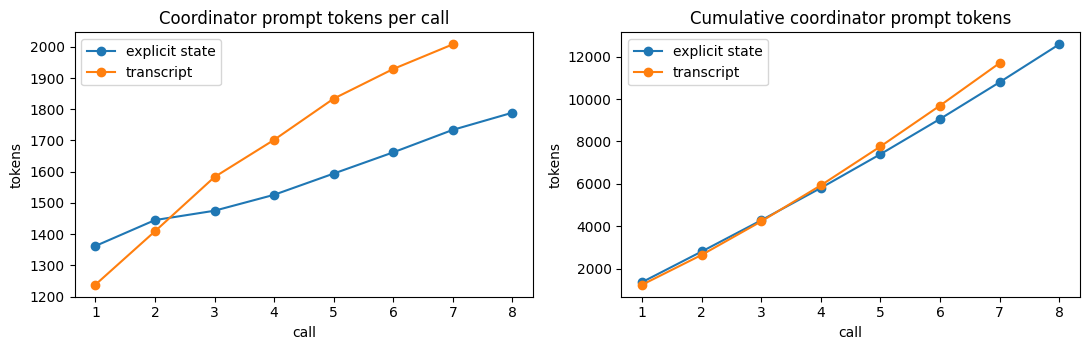

In [ ]:
import matplotlib.pyplot as plt

TRANSCRIPT_TEMPLATE = """Instructions:
{instructions}

You have no structured state. The history below is your only memory.

History:
{history}

Latest Observation: {observation}

Give your reasoning, then end with one line of the form `Action: <action>`."""


def run_transcript_coordinator(city: str, constraints: Dict, max_steps: int = 30) -> List[str]:
    env = CoordinatorEnv(city, constraints, paper_store, cached_agent_runner)
    model = llm.with_label(f"transcript:coordinator:{city}")
    obs, history, actions = env.reset(), [], []
    for _ in range(max_steps):
        hist = "\n\n".join(f"Observation: {o}\nResponse: {r}" for o, r in history) or "(none yet)"
        reply = model.complete(TRANSCRIPT_TEMPLATE.format(
            instructions=coordinator_instructions().text, history=hist, observation=obs)).text
        found = re.findall(r"Action:\s*`?([^`\n]+)`?", reply)
        action = found[-1].strip() if found else "wait"
        actions.append(action)
        history.append((obs, reply.strip()))
        obs, done = env.step(action)
        if done:
            break
    return actions


transcript_actions = run_transcript_coordinator("Seattle", CONSTRAINTS)


def coordinator_prompts(label: str) -> List[int]:
    return [u["prompt_tokens"] for u in USAGE if u["label"] == label]


state_tokens = coordinator_prompts("paper:coordinator:Seattle")
transcript_tokens = coordinator_prompts("transcript:coordinator:Seattle")
print(f"{'':28}{'steps':>7}{'first prompt':>14}{'last prompt':>13}{'cumulative':>12}")
for name, toks in (("explicit state (paper loop)", state_tokens), ("growing transcript", transcript_tokens)):
    print(f"{name:28}{len(toks):>7}{toks[0]:>14,}{toks[-1]:>13,}{sum(toks):>12,}")
print("\ntranscript actions:", transcript_actions)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for name, toks in (("explicit state", state_tokens), ("transcript", transcript_tokens)):
    a1.plot(range(1, len(toks) + 1), toks, marker="o", label=name)
    a2.plot(range(1, len(toks) + 1), np.cumsum(toks), marker="o", label=name)
a1.set(title="Coordinator prompt tokens per call", xlabel="call", ylabel="tokens")
a2.set(title="Cumulative coordinator prompt tokens", xlabel="call", ylabel="tokens")
a1.legend(); a2.legend(); plt.tight_layout(); plt.show()

## 3. Running `HarnessKernel` on LangGraph

In Section 2, we used the paper’s loop to validate a state patch, merge it, and execute the proposed action. Now we need the harness to intervene when the patch itself is valid. An agent can keep calling a failing tool, run out of budget, or propose an action it lacks permission to take. A loan inquiry can be ready to submit while the buyer’s approval is still pending. We also need to recover the run if the process stops.

Each execution now runs as a thread in a [LangGraph](https://langchain-ai.github.io/langgraph/) `StateGraph`. On the normal path, `begin` leads to `decide`, LangGraph checkpoints the new state and pending action, and `act` executes the action. Both `decide` and `act` can route to `recover`. Recovery can return to `decide` or send the execution to `hold` to wait for input.

| What we do | Where it happens |
|---|---|
| Run inference, parse the response, validate the merged state, and check the proposed action | `decide` |
| Persist $\Sigma_{t+1}$ and the pending action before executing it | `SqliteSaver` checkpoints the graph after `decide` with `durability="sync"` |
| Execute the action and record its completion | `act` |
| Resume after a process failure | `invoke(None, config)` resumes the thread and reruns the unfinished node from its start |
| Suspend or escalate and wait for input | `hold` calls `interrupt()`. `Command(resume=...)` continues the execution. |
| Branch from a checkpoint | Start a new thread from that checkpoint’s $\Sigma$ |
| Return to an earlier step | Invoke the graph with the earlier checkpoint’s config, as shown in Section 8 |

LangGraph runs the graph and manages its checkpoints. The harness defines the prompt contract, middleware, recovery policy, allowed status transitions, pins, action effects, artifacts, approvals, and journal. We still use `skill_state` to validate and merge patches.

### What we keep in state and in the logs

The model receives the procedure $P$, the current state $\Sigma_t$, and the latest observation $O_t$. Of the graph state fields, it sees only `sigma`. LangGraph checkpoints the harness fields alongside it, including the pending action, status, budgets, loop detection history, and per-role memory such as which tools an agent has used. The harness also keeps operational records in its own tables.

| Record | What it contains | What we use it for |
|---|---|---|
| **Agent state** | $\Sigma$, updated through validated patches | The current facts of the investigation |
| **Workflow state** | $\Sigma$ and the harness fields, including the pending action and its commit ID | Where to resume and what should run next |
| **Operational record** | Execution records, action log, events, artifacts, approvals, and journal | What happened during the execution and what reached an external system |

To resume, we read the checkpoint. To see whether a committed action started or completed, we read the action log. A node can stop before it finishes even though its action already reached the receiving system. For the loan inquiry, we use the journal and reconcile with the lender’s own record. We look up the buyer’s approval in the approvals table.

The checkpoint also holds the execution’s current status. `executions.status` is a copy for queries, and `events` records the status history. Section 4.1 shows what happens when the copy falls behind.

### Where the harness can intervene

| Control point | Hook | What we check |
|---|---|---|
| Before inference | `on_pre_inference` | Step and token budgets |
| During generation | `on_stream_chunk` | Runaway or repetitive output |
| Before committing state | `on_pre_commit` | Domain rules on the merged state, after schema and invariant checks |
| Before allowing an action | `on_pre_action` | Permissions, repeated actions, and approvals |

`on_post_inference` receives the full response before parsing. In `decide`, we parse the response, merge and validate the patch, check the invariants, and run the pre-action gate. LangGraph then checkpoints the validated state and pending action. `act` runs the action and records its completion. We discard the model’s reasoning after the step.

`decide` derives a commit ID from the transition it commits. The action log uses that ID to record when the action starts and when it completes. If `act` runs again, it can look up what happened on the previous attempt.

The harness can also propose an action directly through `commit_transition`. It goes through the same validation and pre-action gates and uses the same commit ID and action log. When the action completes, control returns to the harness. We use this path for the loan inquiry in Section 6.

The checkpoint and the harness records use separate transactions, even though they share a SQLite file. An external action happens outside both transactions. If the process stops between writes, the checkpoint and action log can reflect different stages of the same action. Section 6 walks through those failure points and shows how write ordering, the journal, and reconciliation let us recover.

### Handling interrupts and invalid patches

Middleware can raise a typed `SemanticInterrupt`. The recovery policy maps each kind to a decision. It can retry, redirect the model with the refusal, suspend, escalate to a person, or fail the execution. `TRANSITIONS` defines the allowed moves between `RUNNING`, `INTERRUPTED`, `RECOVERING`, `SUSPENDED`, `COMPLETED`, and `FAILED`. `FAILED` is terminal. We reopen a suspended or completed execution through `RECOVERING`.

The streaming hook receives each chunk once. The guard keeps running counts so it can inspect the new chunk without scanning the full response again. We write a usage row for every model call, including calls we stop early. If we close the stream before the provider reports usage, we estimate usage from the character count and label the estimate.

For malformed responses and invalid patches, we use the paper’s rollback and retry. `diagnose_response` parses the response, merges the patch, and checks the schema and invariants. Each diagnostic gives the model a code, a location, a message, and a suggested fix. We retry within the same step with the committed state unchanged. If the retries run out, we escalate to a person who can inspect the recording and resume from that state.

If the harness refuses an action and asks the model to choose again, we keep the original observation and add the refusal to it. For example, the model still needs the artifact ID returned by the previous dispatch. An interrupt before the checkpoint leaves $\Sigma$ unchanged. If the action itself raises an interrupt, the new state has already been committed and the action log shows that the action hasn’t completed.

### Recovering an unfinished action

On resume, LangGraph reruns the unfinished node from the start. When `act` finds that the action already started under the same commit ID, the harness checks what kind of effect the action has before deciding how to proceed.

| Effect | Examples | What `act` does on restart |
|---|---|---|
| `read` | Data tools and `read_artifacts` | Run the read again. |
| `idempotent` | `dispatch_agent`, keyed by execution and task ID, and `request_approval` | Repeat the call with the same key to recover the original result. |
| `control` | `finish`, `wait`, and `done` | Run the control action again. |
| `external` | `submit_inquiry` | Check with the receiving system before sending anything. Escalate if we can’t check. |
| `unknown` | An action without an effect classification | Escalate with `OUTCOME_UNKNOWN` for a person to decide. |

### Checking the execution’s pins

Each execution records the model, skill version and digest, always-loaded artifacts, state schema, and a digest of the exact instructions it received. Before running the execution, the kernel compares those pins with the current configuration. If any differ, it suspends with `PIN_MISMATCH`.

Here we verify the pins against the skill files on disk. In Notebook 2, the registry keeps each version, so the harness can resolve the exact configuration an execution was pinned to.

In [ ]:
from collections import Counter


class Status(str, Enum):
    CREATED = "CREATED"
    RUNNING = "RUNNING"
    INTERRUPTED = "INTERRUPTED"
    RECOVERING = "RECOVERING"
    SUSPENDED = "SUSPENDED"
    COMPLETED = "COMPLETED"
    FAILED = "FAILED"


# The only status changes the kernel may make. FAILED is terminal; a SUSPENDED or COMPLETED
# execution is reopened through RECOVERING; RUNNING -> RECOVERING is a restart after a failure.
TRANSITIONS = {
    Status.CREATED: {Status.RUNNING},
    Status.RUNNING: {Status.INTERRUPTED, Status.SUSPENDED, Status.COMPLETED, Status.RECOVERING},
    Status.INTERRUPTED: {Status.RECOVERING, Status.SUSPENDED, Status.FAILED},
    Status.RECOVERING: {Status.RUNNING},
    Status.SUSPENDED: {Status.RECOVERING},
    Status.COMPLETED: {Status.RECOVERING},
    Status.FAILED: set(),
}


class Kind(str, Enum):
    LOOP_DETECTED = "LOOP_DETECTED"
    SCHEMA_VIOLATION = "SCHEMA_VIOLATION"
    POLICY_DENIED = "POLICY_DENIED"
    BUDGET_EXCEEDED = "BUDGET_EXCEEDED"
    STATE_CONFLICT = "STATE_CONFLICT"
    APPROVAL_REQUIRED = "APPROVAL_REQUIRED"
    STREAM_ABORTED = "STREAM_ABORTED"
    SOURCE_UNAVAILABLE = "SOURCE_UNAVAILABLE"
    OUTCOME_UNKNOWN = "OUTCOME_UNKNOWN"
    PIN_MISMATCH = "PIN_MISMATCH"


class SemanticInterrupt(Exception):
    """Raised by middleware, by an action, or by the kernel when execution must stop or change course."""

    def __init__(self, kind: Kind, message: str, hook: str, **detail):
        super().__init__(f"{kind.value}: {message}")
        self.kind, self.message, self.hook, self.detail = kind, message, hook, detail


class ProcessKilled(BaseException):
    """A simulated process failure. Not an interrupt: nothing in the kernel handles it."""


# --- what an action does, and what recovery may therefore do with it ------------------
class Effect(str, Enum):
    READ = "read"               # no side effects
    IDEMPOTENT = "idempotent"   # side effects the harness keys and deduplicates
    EXTERNAL = "external"       # reaches a system outside the harness
    CONTROL = "control"         # changes only this execution's own status
    UNKNOWN = "unknown"         # not classified: its outcome cannot be established


RECOVERY = {Effect.READ: "replay", Effect.IDEMPOTENT: "replay", Effect.CONTROL: "replay",
            Effect.EXTERNAL: "reconcile", Effect.UNKNOWN: "escalate"}


def _canonical(value):
    if isinstance(value, float) and value.is_integer():
        return int(value)
    if isinstance(value, str):
        return value.strip()
    if isinstance(value, dict):
        return {k.strip(): _canonical(v) for k, v in value.items()}
    if isinstance(value, list):
        return [_canonical(v) for v in value]
    return value


def action_name(action: str) -> str:
    call = parse_call(action)
    return call[0] if call else (action.split() or [""])[0]


def normalise_action(action: str) -> str:
    """One spelling per call: key order, whitespace and 850000 vs 850000.0 do not matter;
    any difference in a value does."""
    call = parse_call(action)
    if call:
        return f"call {call[0]} {json.dumps(_canonical(call[1]), sort_keys=True)}"
    return " ".join(action.split())


def digest_text(text: str) -> str:
    return hashlib.sha256((text or "").encode()).hexdigest()[:12]


class Middleware:
    """Synchronous hooks. Each receives the kernel, which exposes the current state, the
    step number, the harness's record of completed actions, and the store."""

    def on_pre_inference(self, k): ...
    def on_stream_start(self, k): ...
    def on_stream_chunk(self, k, piece: str): ...
    def on_post_inference(self, k, text: str): ...
    def on_pre_commit(self, k, candidate: Dict, patch: Dict): ...
    def on_pre_action(self, k, action: str): ...


class BudgetMiddleware(Middleware):
    def __init__(self, max_steps: int, max_prompt_tokens: Optional[int] = None):
        self.max_steps, self.max_prompt_tokens = max_steps, max_prompt_tokens

    def on_pre_inference(self, k):
        if k.step_no >= self.max_steps:
            raise SemanticInterrupt(Kind.BUDGET_EXCEEDED, f"{k.step_no} of {self.max_steps} steps used",
                                    "pre_inference")
        if self.max_prompt_tokens and k.prompt_tokens_used >= self.max_prompt_tokens:
            raise SemanticInterrupt(Kind.BUDGET_EXCEEDED,
                                    f"{k.prompt_tokens_used} of {self.max_prompt_tokens} prompt tokens used",
                                    "pre_inference")


class StreamGuardMiddleware(Middleware):
    """Stops a generation that runs away or repeats itself, while it is being produced.

    Each piece is scanned once, from left to right, with str.find; nothing is re-read or
    re-concatenated. Memory is bounded whatever the output: the current line keeps at most
    `max_line` characters, and complete lines are counted by a short digest, not stored.
    Pieces arrive as decoded text (the client parses each stream event as JSON), so a piece
    never ends inside a character; line endings can still be \\n, \\r\\n or \\r, and a
    \\r\\n can be split across two pieces."""

    def __init__(self, max_chars: int = 8000, max_repeats: int = 8, min_line: int = 40, max_line: int = 2000):
        self.max_chars, self.max_repeats, self.min_line, self.max_line = max_chars, max_repeats, min_line, max_line

    def on_stream_start(self, k):
        self.chars, self.line, self.line_len, self.after_cr, self.lines = 0, [], 0, False, Counter()

    def on_stream_chunk(self, k, piece: str):
        self.chars += len(piece)
        if self.chars > self.max_chars:
            raise SemanticInterrupt(Kind.STREAM_ABORTED, f"output exceeded {self.max_chars} characters", "stream")
        i, n = 0, len(piece)
        if self.after_cr and n and piece[0] == "\n":       # the second half of a \r\n split across pieces
            i = 1
        self.after_cr = False
        while i < n:
            j = min((x for x in (piece.find("\n", i), piece.find("\r", i)) if x >= 0), default=-1)
            if j < 0:
                self._extend(piece, i, n)
                break
            self._extend(piece, i, j)
            self._end_line(k)
            if piece[j] == "\r":
                if j + 1 < n and piece[j + 1] == "\n":
                    j += 1
                elif j + 1 == n:
                    self.after_cr = True
            i = j + 1

    def _extend(self, piece: str, i: int, j: int):
        room = self.max_line - self.line_len
        if room > 0:
            self.line.append(piece[i:min(j, i + room)])
        self.line_len += j - i

    def _end_line(self, k):
        text = "".join(self.line).strip()
        self.line, self.line_len = [], 0
        if len(text) > self.min_line:
            key = hashlib.blake2b(text.encode(), digest_size=8).digest()
            self.lines[key] += 1
            if self.lines[key] >= self.max_repeats:
                raise SemanticInterrupt(Kind.STREAM_ABORTED,
                                        f"a line repeated {self.max_repeats} times in the output", "stream")


class PermissionMiddleware(Middleware):
    def __init__(self, granted: set):
        self.granted = set(granted)

    def on_pre_action(self, k, action: str):
        name = action_name(action)
        if name not in self.granted:
            raise SemanticInterrupt(Kind.POLICY_DENIED, f"'{name}' is not granted to {k.role}",
                                    "pre_action", action=action)


class LoopDetectorMiddleware(Middleware):
    """Repetition of one call (after normalisation), judged by what the earlier attempts returned:

    - it failed every time before: refused at the `fail_limit`-th attempt (a retry loop);
    - it returned the same result every time before: refused at the `stall_limit`-th attempt
      (no new information);
    - it returned different results: allowed, as polling a changing status is, up to `poll_limit`.

    The history is the completed actions in the store. An action left unfinished by a process
    failure has no completion, so its replay on resume is counted once, when it completes."""

    def __init__(self, fail_limit: int = 3, stall_limit: int = 3, poll_limit: int = 10):
        self.fail_limit, self.stall_limit, self.poll_limit = fail_limit, stall_limit, poll_limit

    def on_pre_action(self, k, action: str):
        norm = normalise_action(action)
        prior = [h for h in k.history if h["norm"] == norm]
        if not prior:
            return
        n = len(prior) + 1
        failed = [h for h in prior if h["observation"].startswith("ERROR")]
        if len(failed) == len(prior) and n >= self.fail_limit:
            raise SemanticInterrupt(
                Kind.LOOP_DETECTED, f"'{action[:80]}' failed {len(prior)} times before", "pre_action",
                action=action, pattern="repeated_failure",
                source_unavailable=prior[-1]["observation"].startswith("ERROR (source unavailable)"))
        if not failed and len({h["digest"] for h in prior}) == 1 and n >= self.stall_limit:
            raise SemanticInterrupt(Kind.LOOP_DETECTED,
                                    f"'{action[:80]}' returned the same result {len(prior)} times",
                                    "pre_action", action=action, pattern="no_new_information")
        if n > self.poll_limit:
            raise SemanticInterrupt(Kind.LOOP_DETECTED, f"'{action[:80]}' attempted {n} times",
                                    "pre_action", action=action, pattern="poll_limit")


class FinishCheckMiddleware(Middleware):
    """An agent may only finish with a complete draft of the artifact kind its skill promises."""

    def __init__(self, agent: str):
        self.agent = agent

    def on_pre_action(self, k, action: str):
        if action.strip() != "finish":
            return
        d = k.candidate.get("draft") or {}
        if d.get("kind") != OUTPUT_KIND[self.agent] or not d.get("summary") or d.get("content") in (None, {}, []):
            raise SemanticInterrupt(Kind.STATE_CONFLICT,
                                    f"finish needs a draft with kind '{OUTPUT_KIND[self.agent]}', a summary "
                                    "and content", "pre_action")


class ApprovalGateMiddleware(Middleware):
    """External submissions need a person's approval of exactly the payload that would be
    sent, recorded in the store. The state's own fields are not evidence: the model writes
    the state. `payload_for(state, kind)` says what would be sent."""

    GATED = {"submit_inquiry"}

    def __init__(self, payload_for: Callable[[Dict, str], Dict]):
        self.payload_for = payload_for

    def on_pre_action(self, k, action: str):
        parts = action.split()
        if parts and parts[0] in self.GATED:
            kind = parts[1] if len(parts) > 1 else ""
            payload = self.payload_for(k.candidate, kind)
            ok, reason = k.store.check_approval(k.execution_id, f"{parts[0]} {kind}", payload,
                                                now=getattr(k, "now", time.time)())
            if not ok:
                raise SemanticInterrupt(Kind.POLICY_DENIED, reason, "pre_action", action=action)


# What the kernel does with each kind of interrupt.
DEFAULT_POLICY = {
    Kind.SCHEMA_VIOLATION: "escalate",              # only raised once the in-step retries are spent
    Kind.STATE_CONFLICT: "redirect_or_escalate",    # escalate when the in-step retries are spent
    Kind.POLICY_DENIED: "redirect",
    Kind.LOOP_DETECTED: "suspend_or_redirect",   # suspend if the source is down, else redirect
    Kind.BUDGET_EXCEEDED: "suspend",
    Kind.APPROVAL_REQUIRED: "escalate",
    Kind.STREAM_ABORTED: "retry",
    Kind.SOURCE_UNAVAILABLE: "suspend",
    Kind.OUTCOME_UNKNOWN: "escalate",
    Kind.PIN_MISMATCH: "escalate",
}
MAX_REDIRECTS, MAX_RETRIES = 2, 1


class Faults:
    """Simulated process failures for the demonstrations. ProcessKilled is not handled by
    the kernel: the Python objects are lost, and only what reached SQLite survives."""

    def __init__(self, kill_after_commits: Optional[int] = None, kill_after_send: bool = False):
        self.kill_after_commits, self.kill_after_send, self.commits = kill_after_commits, kill_after_send, 0

    def after_commit(self, k):
        self.commits += 1
        if self.kill_after_commits and self.commits == self.kill_after_commits:
            raise ProcessKilled(f"process killed after commit {self.commits} ({k.role}, step {k.step_no})")

    def after_send(self):
        if self.kill_after_send:
            self.kill_after_send = False
            raise ProcessKilled("process killed after the request was sent, before its result was recorded")

In [ ]:
class Store:
    """The harness's own records, in the same SQLite file as LangGraph's checkpoints: branches,
    executions, the action log, artifacts, events, the journal and approvals. LangGraph's
    SqliteSaver keeps the checkpoints (its tables `checkpoints` and `writes`)."""

    DDL = """
    CREATE TABLE IF NOT EXISTS branches (name TEXT PRIMARY KEY, parent TEXT, from_checkpoint TEXT,
        assumptions TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS executions (id TEXT PRIMARY KEY, branch TEXT, role TEXT,
        parent_execution TEXT, task_id TEXT, status TEXT, config TEXT, initial_state TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS actions (commit_id TEXT PRIMARY KEY, execution_id TEXT, step INTEGER,
        action TEXT, status TEXT, observation TEXT, outcome TEXT, started REAL, finished REAL);
    CREATE TABLE IF NOT EXISTS artifacts (id TEXT PRIMARY KEY, kind TEXT, branch TEXT, summary TEXT,
        content TEXT, inputs TEXT, produced_by TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS events (seq INTEGER PRIMARY KEY AUTOINCREMENT, execution_id TEXT,
        branch TEXT, role TEXT, kind TEXT, detail TEXT, created REAL);
    CREATE TABLE IF NOT EXISTS journal (key TEXT PRIMARY KEY, execution_id TEXT, action TEXT,
        payload TEXT, status TEXT, result TEXT, created REAL, updated REAL);
    CREATE TABLE IF NOT EXISTS approvals (id TEXT PRIMARY KEY, execution_id TEXT, branch TEXT,
        action TEXT, payload TEXT, payload_digest TEXT, status TEXT, decided_by TEXT, created REAL,
        decided REAL, expires REAL);
    """

    def __init__(self, path: Path):
        self.path = Path(path)
        self.db = sqlite3.connect(self.path, check_same_thread=False, timeout=30)
        self.db.row_factory = sqlite3.Row
        self.db.execute("PRAGMA journal_mode=WAL")
        self.db.executescript(self.DDL)
        self._seq: Counter = Counter()

    # -- helpers ------------------------------------------------------------------
    def _x(self, sql, *args):
        cur = self.db.execute(sql, args)
        self.db.commit()
        return cur

    def _one(self, sql, *args) -> Optional[Dict]:
        row = self.db.execute(sql, args).fetchone()
        return dict(row) if row else None

    def df(self, table: str) -> pd.DataFrame:
        return pd.read_sql_query(f"SELECT * FROM {table}", self.db)

    def _id(self, prefix: str) -> str:
        """Sequential ids. A run that repeats the same steps gets the same ids, which is
        what lets a recorded run be replayed: ids appear in what the model reads."""
        self._seq[prefix] += 1
        return f"{prefix}_{self._seq[prefix]:05d}"

    # -- branches and executions ----------------------------------------------------
    def add_branch(self, name, parent=None, from_checkpoint=None, assumptions=None):
        self._x("INSERT OR IGNORE INTO branches VALUES (?,?,?,?,?)", name, parent, from_checkpoint,
                json.dumps(assumptions or {}), time.time())

    def lineage(self, branch: str) -> List[str]:
        out = []
        while branch:
            out.append(branch)
            row = self._one("SELECT parent FROM branches WHERE name=?", branch)
            branch = row["parent"] if row else None
        return out

    def new_execution(self, branch, role, config, initial_state, parent_execution=None, task_id=None) -> str:
        eid = self._id("ex")
        self._x("INSERT INTO executions VALUES (?,?,?,?,?,?,?,?,?)", eid, branch, role, parent_execution,
                task_id, Status.CREATED.value, json.dumps(config), json.dumps(initial_state), time.time())
        return eid

    def execution(self, eid) -> Dict:
        row = self._one("SELECT * FROM executions WHERE id=?", eid)
        row["config"], row["initial_state"] = json.loads(row["config"]), json.loads(row["initial_state"])
        return row

    def executions(self, **where) -> List[Dict]:
        sql = "SELECT * FROM executions" + (" WHERE " + " AND ".join(f"{k}=?" for k in where) if where else "")
        rows = [dict(r) for r in self.db.execute(sql + " ORDER BY created", tuple(where.values()))]
        for r in rows:
            r["config"], r["initial_state"] = json.loads(r["config"]), json.loads(r["initial_state"])
        return rows

    def set_status(self, eid, status: Status):
        self._x("UPDATE executions SET status=? WHERE id=?", status.value, eid)

    # -- the action log: one row per committed action, keyed by the commit's checkpoint id ---
    def action_row(self, commit_id) -> Optional[Dict]:
        return self._one("SELECT * FROM actions WHERE commit_id=?", commit_id)

    def action_started(self, commit_id, eid, step, action):
        self._x("INSERT INTO actions VALUES (?,?,?,?,?,?,?,?,?)", commit_id, eid, step, action, "started",
                None, None, time.time(), None)

    def action_completed(self, commit_id, observation, outcome):
        self._x("UPDATE actions SET status='completed', observation=?, outcome=?, finished=? WHERE commit_id=?",
                observation, outcome, time.time(), commit_id)

    # -- artifacts --------------------------------------------------------------------
    def put_artifact(self, kind, branch, summary, content, inputs, produced_by) -> str:
        aid = artifact_id(kind, content, inputs)
        self._x("INSERT OR IGNORE INTO artifacts VALUES (?,?,?,?,?,?,?,?)", aid, kind, branch, summary,
                json.dumps(content, default=str), json.dumps(inputs), json.dumps(produced_by), time.time())
        return aid

    def artifact(self, aid) -> Optional[Dict]:
        row = self._one("SELECT * FROM artifacts WHERE id=?", aid)
        if row:
            for k in ("content", "inputs", "produced_by"):
                row[k] = json.loads(row[k])
        return row

    def artifact_of_execution(self, eid) -> Optional[Dict]:
        row = self._one("SELECT id FROM artifacts WHERE json_extract(produced_by, '$.execution')=?", eid)
        return self.artifact(row["id"]) if row else None

    def visible(self, branch, aid) -> bool:
        a = self._one("SELECT branch FROM artifacts WHERE id=?", aid)
        return bool(a) and a["branch"] in self.lineage(branch)

    def read_artifacts(self, branch, ids) -> Dict[str, Any]:
        return {i: {k: a[k] for k in ("kind", "summary", "content")}
                for i in ids if self.visible(branch, i) and (a := self.artifact(i))}

    def latest_of_kinds(self, branch, ids, kinds) -> Dict[str, Dict]:
        found = {}
        for aid in ids:
            a = self.artifact(aid) if self.visible(branch, aid) else None
            if a and a["kind"] in kinds and (a["kind"] not in found or a["created"] > found[a["kind"]]["created"]):
                found[a["kind"]] = a
        return {k: {"id": a["id"], "summary": a["summary"], "content": a["content"]} for k, a in found.items()}

    # -- events, journal, approvals --------------------------------------------------
    def event(self, eid, branch, role, event_kind, **detail):
        self._x("INSERT INTO events (execution_id, branch, role, kind, detail, created) VALUES (?,?,?,?,?,?)",
                eid, branch, role, event_kind, json.dumps(detail, default=str), time.time())

    def journal_get(self, key) -> Optional[Dict]:
        row = self._one("SELECT * FROM journal WHERE key=?", key)
        if row:
            row["payload"] = json.loads(row["payload"])
            row["result"] = json.loads(row["result"]) if row["result"] else None
        return row

    def journal_intent(self, key, eid, action, payload):
        self._x("INSERT INTO journal VALUES (?,?,?,?,?,?,?,?)", key, eid, action, json.dumps(payload),
                "intent", None, time.time(), time.time())

    def journal_done(self, key, result):
        self._x("UPDATE journal SET status='done', result=?, updated=? WHERE key=?", json.dumps(result),
                time.time(), key)

    def request_approval(self, eid, branch, action, payload) -> str:
        """A request for a person to approve one exact payload. A pending request for a
        different payload of the same action is superseded."""
        digest = payload_digest(payload)
        pending = self.db.execute("SELECT id, payload_digest FROM approvals WHERE execution_id=? AND action=? "
                                  "AND status='pending'", (eid, action)).fetchall()
        for r in pending:
            if r["payload_digest"] == digest:
                return r["id"]
            self._x("UPDATE approvals SET status='superseded' WHERE id=?", r["id"])
        aid = self._id("ap")
        self._x("INSERT INTO approvals VALUES (?,?,?,?,?,?,?,?,?,?,?)", aid, eid, branch, action,
                json.dumps(payload, sort_keys=True), digest, "pending", None, time.time(), None, None)
        return aid

    def approve(self, approval_id, decided_by: str, valid_for_s: float = 24 * 3600):
        now = time.time()
        self._x("UPDATE approvals SET status='approved', decided_by=?, decided=?, expires=? WHERE id=? "
                "AND status='pending'", decided_by, now, now + valid_for_s, approval_id)

    def approval(self, approval_id) -> Optional[Dict]:
        row = self._one("SELECT * FROM approvals WHERE id=?", approval_id)
        if row:
            row["payload"] = json.loads(row["payload"])
        return row

    def check_approval(self, eid, action, payload, now=None) -> Tuple[bool, str]:
        """Is there an approval by a person, for this execution, this action and exactly this
        payload, that has not expired? Returns (ok, reason)."""
        now = time.time() if now is None else now
        rows = [dict(r) for r in self.db.execute(
            "SELECT * FROM approvals WHERE execution_id=? AND action=? AND status='approved' "
            "ORDER BY decided DESC", (eid, action))]
        if not rows:
            return False, f"no recorded approval for '{action}' in this execution"
        digest = payload_digest(payload)
        match = [r for r in rows if r["payload_digest"] == digest]
        if not match:
            return False, (f"the approved payload ({rows[0]['payload_digest']}) differs from the one "
                           f"about to be sent ({digest})")
        live = [r for r in match if r["expires"] and r["expires"] > now]
        if not live:
            return False, f"the approval {match[0]['id']} expired"
        return True, f"approved by {live[0]['decided_by']} ({live[0]['id']}, payload {digest})"

    def valid_approval(self, eid, action, payload, now=None) -> Optional[Dict]:
        ok, _ = self.check_approval(eid, action, payload, now)
        if not ok:
            return None
        return self._one("SELECT * FROM approvals WHERE execution_id=? AND action=? AND status='approved' "
                         "AND payload_digest=? ORDER BY decided DESC LIMIT 1", eid, action, payload_digest(payload))

    def pending_approvals(self) -> List[Dict]:
        return [dict(r) for r in self.db.execute("SELECT * FROM approvals WHERE status='pending'")]


def payload_digest(payload: Dict) -> str:
    return hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()[:16]


def history_entry(action: str, observation: str) -> Dict[str, str]:
    return {"action": action, "norm": normalise_action(action), "observation": (observation or "")[:300],
            "digest": digest_text(observation)}

In [ ]:
import contextvars
from typing import TypedDict

from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt


def schema_digest(schema: Dict) -> str:
    return hashlib.sha256(json.dumps(schema, sort_keys=True).encode()).hexdigest()[:12]


def pin_config(skill_name: str, schema: Dict, instructions: str) -> Dict[str, Any]:
    """What an execution is pinned to: the model, the skill version and digest, the always-loaded
    artifacts, the state schema, and the exact instructions compiled from them."""
    a = ARTIFACTS[skill_name]
    return {"model": MODEL, "skill": {"name": a.name, "version": a.version, "digest": a.digest},
            "always": {x.name: x.digest for x in ALWAYS}, "schema_digest": schema_digest(schema),
            "instructions_digest": digest_text(instructions)}


def pin_mismatches(pinned: Dict, current: Dict) -> List[Dict[str, Any]]:
    """Every pinned field whose current value differs."""
    out = []
    for key in ("model", "schema_digest", "instructions_digest"):
        if pinned.get(key) != current.get(key):
            out.append({"pin": key, "pinned": pinned.get(key), "current": current.get(key)})
    if pinned["skill"] != current["skill"]:
        out.append({"pin": "skill", "pinned": pinned["skill"], "current": current["skill"]})
    for name in sorted(set(pinned["always"]) | set(current["always"])):
        if pinned["always"].get(name) != current["always"].get(name):
            out.append({"pin": f"always:{name}", "pinned": pinned["always"].get(name),
                        "current": current["always"].get(name)})
    return out


@dataclass
class Diagnostic:
    code: str          # E1xx response and JSON, E2xx schema, E3xx invariants
    where: str
    message: str
    hint: str = ""
    excerpt: List[str] = field(default_factory=list)

    def render(self) -> str:
        lines = [f"{self.code} {self.where}: {self.message}"] + [f"    {x}" for x in self.excerpt]
        return "\n".join(lines + ([f"    help: {self.hint}"] if self.hint else []))


_FENCED = re.compile(r"```(?:json)?\s*\n?(.*?)```", re.S | re.I)


def _schema_at(schema: Dict, parts: List[str]) -> Optional[Dict]:
    """The sub-schema at a state path such as ['tasks', 't2'], or None."""
    for part in parts:
        if schema is None:
            return None
        if part.startswith("["):
            schema = schema.get("items")
        elif part in schema.get("properties", {}):
            schema = schema["properties"][part]
        elif isinstance(schema.get("additionalProperties"), dict):
            schema = schema["additionalProperties"]
        else:
            return None
    return schema


def _schema_diagnostic(error: str, schema: Dict) -> Diagnostic:
    path, _, message = error.partition(": ")
    parts = re.findall(r"\[\d+\]|[^.\[\]$]+", path)
    where = "state." + ".".join(parts) if parts else "state"
    if message == "key not allowed by schema":
        parent = _schema_at(schema, parts[:-1]) or {}
        allowed = sorted(parent.get("properties", {}))
        return Diagnostic("E202", where, "key not allowed by the state schema",
                          f"remove '{parts[-1]}'; allowed here: {', '.join(allowed) or 'none'}")
    if message.startswith("missing required key"):
        return Diagnostic("E203", where, message, "add the key in the same patch")
    if " not in " in message:
        return Diagnostic("E204", where, message, "use one of the listed values")
    if message.startswith("expected "):
        return Diagnostic("E205", where, message, "change the value's type")
    if "minimum" in message or "maximum" in message:
        return Diagnostic("E206", where, message, "keep the value within the bounds")
    return Diagnostic("E201", where, message)


def diagnose_response(text: str, state: Dict, schema: Dict, checks: List[Callable]):
    """Parse, merge, validate and check one response. Returns (parsed, candidate, diagnostics, kind):
    either a valid candidate state, or diagnostics that say where the response is wrong and how
    to fix it. This is all the model is shown on a retry."""
    try:
        parsed = parse_response(text)
    except ParseError as e:
        blocks = _FENCED.findall(text)
        if not blocks:
            return None, None, [Diagnostic("E101", "response", "no ```json block found",
                                           'end the response with one ```json block holding "state_patch" and "action"')], \
                Kind.SCHEMA_VIOLATION
        raw = blocks[-1].strip()
        try:
            json.loads(raw)
        except json.JSONDecodeError as je:
            src = raw.splitlines() or [""]
            line = src[min(je.lineno, len(src)) - 1]
            return None, None, [Diagnostic(
                "E102", f"json line {je.lineno}, column {je.colno}", je.msg, "fix the JSON syntax; no comments, no trailing commas",
                [f"{je.lineno:>3} | {line[:160]}", f"    | {' ' * min(je.colno - 1, 160)}^"])], Kind.SCHEMA_VIOLATION
        return None, None, [Diagnostic("E103", "json block", str(e),
                                       'the block must be {"state_patch": {...}, "action": "..."} and nothing else')], \
            Kind.SCHEMA_VIOLATION
    try:
        candidate = merge(state, parsed.state_patch)
    except Exception as e:
        return parsed, None, [Diagnostic("E104", "state_patch", f"cannot be merged: {e}")], Kind.SCHEMA_VIOLATION
    errors = validate(candidate, schema)
    if errors:
        return parsed, candidate, [_schema_diagnostic(e, schema) for e in errors], Kind.SCHEMA_VIOLATION
    diags = [Diagnostic("E301", f"invariant {c.__name__}", e) for c in checks for e in c(candidate)]
    return parsed, candidate, diags, (Kind.STATE_CONFLICT if diags else None)


def render_diagnostics(diags: List[Diagnostic], limit: int = 4) -> str:
    more = f"\n(and {len(diags) - limit} more)" if len(diags) > limit else ""
    return "\n" + "\n".join(d.render() for d in diags[:limit]) + more


def start_execution(store: Store, branch: str, role: str, skill_name: str, initial_state: Dict,
                    schema: Dict, instructions: str, parent_execution=None, task_id=None) -> str:
    """Register an execution and what it is pinned to. Its LangGraph thread (thread_id = the
    execution id) starts from `initial_state` on the first run."""
    return store.new_execution(branch, role, pin_config(skill_name, schema, instructions), initial_state,
                               parent_execution, task_id)


class ExecState(TypedDict, total=False):
    """One execution's graph state. `sigma` is Σ, the only part the model ever sees. The other
    fields are the harness's: checkpointed with Σ, restored with Σ, never put in a prompt."""
    sigma: Dict[str, Any]
    observation: str
    action: Optional[str]           # committed by `decide`, executed by `act`
    commit: Optional[str]           # id of the commit that holds the pending action
    outcome: Optional[str]
    step: int
    status: str
    history: List[Dict[str, str]]   # completed actions on this path, read by the loop detector
    scratch: Dict[str, Any]         # per-role harness memory, e.g. the tools an agent used
    redirects: int
    retries: Dict[str, int]
    run_steps: int
    run_budget: int
    pending: Optional[Dict[str, Any]]     # an interrupt waiting for the recovery policy
    last_interrupt: Optional[Dict[str, Any]]
    decision: Optional[str]
    hold: Optional[Dict[str, Any]]        # why the execution is suspended
    after_action: Optional[str]           # "hold": return control to the harness once the action completes
    prompt_tokens: int


def si_to_dict(si: SemanticInterrupt) -> Dict[str, Any]:
    return {"kind": si.kind.value, "message": si.message, "hook": si.hook, "detail": si.detail}


def si_from_dict(d: Optional[Dict]) -> Optional[SemanticInterrupt]:
    return SemanticInterrupt(Kind(d["kind"]), d["message"], d["hook"], **d["detail"]) if d else None


SAVER = None       # LangGraph's SqliteSaver on the harness database, set with the store


class HarnessKernel:
    """One execution as a LangGraph thread. The SKILL.state step contract runs in two nodes:

      begin ──> decide ──(checkpoint: Σ_{t+1} and the action are durable)──> act ──> decide ...
                  │                                                           │
                  └──────────────> recover <──────────── interrupts ──────────┘
                                      │
                            redirect / retry ──> decide       suspend / escalate ──> hold (interrupt())

    `decide` makes the model call and validates; LangGraph checkpoints its result before `act`
    runs, which is the commit boundary. `act` executes the action, and recovers an action whose
    commit it finds already started in the action log, according to the action's effect. `hold` pauses the thread
    with LangGraph's interrupt(); resuming it continues where it stopped."""

    def __init__(self, store: Store, execution_id: str, *, role: str, skill_name: str, instructions: str,
                 schema: Dict, checks: List[Callable], llm, middleware: List[Middleware],
                 act: Callable, effect_of: Callable[[str], Effect],
                 reconcile: Optional[Callable] = None, policy: Optional[Dict] = None,
                 max_retries: int = 2, faults: Optional[Faults] = None):
        self.store, self.execution_id, self.role, self.skill_name = store, execution_id, role, skill_name
        self.instructions, self.schema, self.checks, self.llm = instructions, schema, checks, llm
        self.middleware, self.act, self.effect_of, self.reconcile = middleware, act, effect_of, reconcile
        self.policy, self.max_retries, self.faults = policy or DEFAULT_POLICY, max_retries, faults
        ex = store.execution(execution_id)
        self.branch, self.config = ex["branch"], ex["config"]
        self.cfg = {"configurable": {"thread_id": execution_id}, "recursion_limit": 1000}
        self.app = build_kernel_graph(self).compile(checkpointer=SAVER)
        self.calls: List[int] = []
        self.candidate: Dict = {}
        self._resume_reason: Optional[str] = None
        self._sync(self.app.get_state(self.cfg).values or {"status": ex["status"]})
        self.reconcile_status(ex["status"])

    def reconcile_status(self, stored: str) -> None:
        """The checkpoint's status is authoritative. `executions.status` is a copy for queries,
        written in its own transaction; a failure between the two writes can leave it behind."""
        if self.snapshot().values and stored != self.status.value:
            self.event("status_reconciled", stored=stored, checkpoint=self.status.value)
            self.store.set_status(self.execution_id, self.status)

    # -- the view middleware and actions read ------------------------------------------
    def _sync(self, s: Dict):
        self.state = s.get("sigma", {})
        self.step_no, self.history = s.get("step", 0), s.get("history", [])
        self.status = Status(s.get("status", Status.CREATED.value))
        self.scratch = json.loads(json.dumps(s.get("scratch", {})))
        self.prompt_tokens_used = s.get("prompt_tokens", 0)
        self.last_interrupt = si_from_dict(s.get("last_interrupt"))

    def snapshot(self, config: Optional[Dict] = None):
        return self.app.get_state(config or self.cfg)

    # -- records -------------------------------------------------------------------
    def event(self, name: str, **detail):
        self.store.event(self.execution_id, self.branch, self.role, name, skill=self.config["skill"], **detail)

    def set_status(self, status: Status, **detail) -> str:
        if status is not self.status:
            if status not in TRANSITIONS[self.status]:
                raise RuntimeError(f"illegal status change {self.status.value} -> {status.value}")
            self.event("status", frm=self.status.value, to=status.value, **detail)
            self.status = status
            self.store.set_status(self.execution_id, status)
        return status.value

    def current_pins(self) -> Dict[str, Any]:
        return {**pin_config(self.skill_name, self.schema, self.instructions), "model": self.llm.model}

    def pin_mismatches(self) -> List[Dict[str, Any]]:
        return pin_mismatches(self.config, self.current_pins())

    def _pin_interrupt(self) -> Optional[Dict]:
        diff = self.pin_mismatches()
        if not diff:
            return None
        return si_to_dict(SemanticInterrupt(Kind.PIN_MISMATCH, "configuration differs from the pinned one: "
                                            + ", ".join(d["pin"] for d in diff), "pre_inference", mismatches=diff))

    # -- running -------------------------------------------------------------------
    def run(self, observation: str = "", max_steps: int = 40) -> Status:
        """Start, resume or reopen this execution, whichever its thread needs."""
        snap = self.snapshot()
        if not snap.values:                                   # first run of a new thread
            inp = {"sigma": self.store.execution(self.execution_id)["initial_state"], "observation": observation,
                   "action": None, "commit": None, "outcome": None, "step": 0, "status": Status.CREATED.value,
                   "history": [], "scratch": {}, "redirects": 0, "retries": {}, "run_steps": 0,
                   "run_budget": max_steps, "pending": None, "last_interrupt": None, "decision": None,
                   "hold": None, "after_action": None, "prompt_tokens": 0}
        elif snap.interrupts:                                 # suspended at `hold`
            inp = Command(resume={"observation": observation, "budget": max_steps})
        elif snap.next == ("act",) and not self.store.action_row(snap.values.get("commit")):
            inp = None                                        # a commit the harness wrote; not yet run
        elif snap.next:                                       # stopped between nodes: a process failure
            self._resume_reason, inp = "restart", None
        else:                                                 # finished: reopen with a new observation
            inp = {"observation": observation, "run_budget": max_steps}
        return self._invoke(inp, self.cfg)

    def commit_transition(self, patch: Dict, action: str, reason: str) -> str:
        """A transition the harness makes, not the model: commit Σ ⊕ patch and `action` exactly as
        `decide` would, through the same validation and the same pre-action gates, then let `act`
        run it on the next run. When the action completes, control returns to the harness
        (the execution suspends) instead of to the model."""
        snap = self.snapshot()
        s = snap.values
        self._sync(s)
        if s.get("action") and snap.next == ("act",):
            raise RuntimeError(f"an action is already committed and pending: {s['action']}")
        candidate, diags = merge(self.state, patch), []
        diags = [_schema_diagnostic(e, self.schema) for e in validate(candidate, self.schema)] + \
                [Diagnostic("E301", f"invariant {c.__name__}", e) for c in self.checks for e in c(candidate)]
        if diags:
            raise ValueError("the transition would commit an invalid state:" + render_diagnostics(diags))
        self.candidate = candidate
        for m in self.middleware:                 # the same gates a model-chosen action passes
            m.on_pre_action(self, action)
        if self.status in (Status.COMPLETED, Status.SUSPENDED):
            self.set_status(Status.RECOVERING, reason="harness transition")
        status = self.set_status(Status.RUNNING)
        commit = f"{self.execution_id}/{s['step'] + 1}/{digest_text(json.dumps([candidate, action], sort_keys=True))}"
        self.app.update_state(snap.config, {
            "sigma": candidate, "action": action, "commit": commit, "step": s["step"] + 1, "status": status,
            "outcome": None, "pending": None, "hold": None, "after_action": "hold", "run_steps": 0,
            "run_budget": max(s.get("run_budget", 1), 1)}, as_node="decide")
        self.event("harness_transition", action=action, reason=reason, commit=commit)
        return commit

    def run_from(self, config: Dict) -> Status:
        """Time travel: execute again from an earlier checkpoint of this thread. LangGraph forks
        the thread there; the original path stays in its history."""
        self._resume_reason = "time_travel"
        self.event("time_travel", from_checkpoint=config["configurable"]["checkpoint_id"])
        return self._invoke(None, {**config, "recursion_limit": 1000})

    def _invoke(self, inp, config) -> Status:
        # A fresh context: an agent's graph run from inside the coordinator's `act` node is its
        # own thread, not a subgraph of the coordinator.
        contextvars.Context().run(self.app.invoke, inp, config, durability="sync")
        self._sync(self.snapshot().values)
        return self.status

    # -- nodes -----------------------------------------------------------------------
    def _begin(self, s: Dict) -> Dict:
        self._sync(s)
        if self.status is Status.COMPLETED:
            self.event("reopened", observation=s.get("observation", "")[:200])
            self.set_status(Status.RECOVERING)
        out = {"status": self.set_status(Status.RUNNING), "run_steps": 0, "outcome": None, "redirects": 0,
               "pending": self._pin_interrupt()}
        return out

    def _decide(self, s: Dict) -> Dict:
        self._sync(s)
        try:
            if s["run_steps"] >= s["run_budget"]:
                raise SemanticInterrupt(Kind.BUDGET_EXCEEDED, f"{s['run_budget']} steps in one run", "pre_inference")
            for m in self.middleware:
                m.on_pre_inference(self)
            retry_error, retry_kind = None, Kind.SCHEMA_VIOLATION
            for _ in range(self.max_retries + 1):
                prompt = build_prompt(self.instructions, self.state, s["observation"], retry_error)
                text = self._generate(prompt)
                for m in self.middleware:
                    m.on_post_inference(self, text)
                parsed, candidate, diags, kind = diagnose_response(text, self.state, self.schema, self.checks)
                if not diags:
                    try:
                        for m in self.middleware:
                            m.on_pre_commit(self, candidate, parsed.state_patch)
                    except SemanticInterrupt as si:
                        if si.kind not in (Kind.SCHEMA_VIOLATION, Kind.STATE_CONFLICT):
                            raise
                        diags, kind = [Diagnostic("E302", f"pre-commit {si.hook}", si.message)], si.kind
                if diags:                        # the paper's rollback-retry: Σ unchanged, diagnostics shown
                    retry_error, retry_kind = render_diagnostics(diags), kind
                    self.event("rejected_patch", kind=kind.value, codes=[d.code for d in diags], error=retry_error)
                    continue
                break
            else:
                raise SemanticInterrupt(retry_kind, f"no valid state patch in {self.max_retries + 1} attempts:"
                                        f"{retry_error}", "pre_commit", exhausted=True)
            self.candidate = candidate
            for m in self.middleware:
                m.on_pre_action(self, parsed.action)
        except SemanticInterrupt as si:
            return {"pending": si_to_dict(si), "prompt_tokens": self.prompt_tokens_used}
        # Returning commits: LangGraph checkpoints Σ_{t+1} and the action before `act` runs.
        # The commit id is derived from what is committed, so a replay produces the same ids.
        commit = (f"{self.execution_id}/{s['step'] + 1}/"
                  f"{digest_text(json.dumps([candidate, parsed.action], sort_keys=True))}")
        return {"sigma": candidate, "action": parsed.action, "commit": commit, "step": s["step"] + 1,
                "run_steps": s["run_steps"] + 1, "pending": None, "prompt_tokens": self.prompt_tokens_used}

    def _act(self, s: Dict) -> Dict:
        self._sync(s)
        action, commit = s["action"], s["commit"]
        row, handler = self.store.action_row(commit), self.act
        if row is None:
            self.store.action_started(commit, self.execution_id, s["step"], action)
            if self.faults:
                self.faults.after_commit(self)        # a failure between the commit and the action
        else:
            # This commit's action has run before: cut off by a failure, stopped by an interrupt,
            # or executed again by time travel. What happens now depends on what it does.
            reason = "re-executed" if row["status"] == "completed" else "unfinished"
            if self._resume_reason:
                self.event("resumed", previous_status=self.status.value, cause=self._resume_reason,
                           unfinished_action=action)
                self.set_status(Status.RECOVERING)
                self.set_status(Status.RUNNING)
                self._resume_reason = None
            effect = self.effect_of(action)
            plan = RECOVERY[effect] if effect is not Effect.EXTERNAL or self.reconcile else "escalate"
            self.event("recovery_plan", action=action, checkpoint=commit, effect=effect.value, plan=plan,
                       reason=reason)
            pins = self._pin_interrupt()
            if pins:
                return {"pending": pins, "commit": commit, "status": self.status.value}
            if plan == "escalate":
                return {"pending": si_to_dict(SemanticInterrupt(
                    Kind.OUTCOME_UNKNOWN, f"'{action[:80]}' ({effect.value}) may or may not have taken effect",
                    "recovery", action=action, checkpoint=commit)), "commit": commit, "status": self.status.value}
            if plan == "reconcile":
                handler = self.reconcile
        try:
            obs, outcome = handler(action, self)
        except SemanticInterrupt as si:            # the action stays committed and not completed
            return {"pending": si_to_dict(si), "commit": commit, "scratch": self.scratch,
                    "status": self.status.value}
        self.store.action_completed(commit, obs, outcome)
        out = {"observation": obs, "outcome": outcome, "action": None, "commit": None, "pending": None,
               "history": s["history"] + [{**history_entry(action, obs), "commit": commit}],
               "scratch": self.scratch, "status": self.status.value}
        if outcome == "wait":
            out.update(status=self.set_status(Status.SUSPENDED, reason="waiting for input"),
                       hold={"reason": "waiting for input", "needs_human": True})
        elif s.get("after_action") == "hold":       # a transition the harness made: control returns to it
            out.update(status=self.set_status(Status.SUSPENDED, reason="harness transition complete"),
                       hold={"reason": "waiting for the harness", "needs_human": False}, after_action=None)
        return out

    def _recover(self, s: Dict) -> Dict:
        self._sync(s)
        si = si_from_dict(s["pending"])
        self.event("interrupt", kind=si.kind.value, hook=si.hook, message=si.message,
                   **{k: v for k, v in si.detail.items() if k != "kind"})
        self.set_status(Status.INTERRUPTED, kind=si.kind.value)
        rule = self.policy.get(si.kind, "fail")
        if rule == "suspend_or_redirect":
            rule = "suspend" if si.detail.get("source_unavailable") else "redirect"
        if rule == "redirect_or_escalate":
            rule = "escalate" if si.detail.get("exhausted") else "redirect"
        if rule == "redirect" and s["redirects"] >= MAX_REDIRECTS:
            rule = "escalate"                       # redirects spent: a person looks at it
        retries = dict(s.get("retries", {}))
        if rule == "retry" and retries.get(si.kind.value, 0) >= MAX_RETRIES:
            rule = "fail"
        self.event("recovery", kind=si.kind.value, decision=rule)
        out = {"pending": None, "last_interrupt": si_to_dict(si), "decision": rule}
        if rule in ("redirect", "retry"):
            self.set_status(Status.RECOVERING)
            out["status"] = self.set_status(Status.RUNNING)
            if rule == "retry":
                retries[si.kind.value] = retries.get(si.kind.value, 0) + 1
                out["retries"] = retries
            else:                                   # keep what the model was shown, add the refusal
                out["redirects"] = s["redirects"] + 1
                out["observation"] = (f"{s['observation']}\n\nYour last response was refused ({si.kind.value}): "
                                      f"{si.message}. The state is unchanged. Respond again to the observation above.")
                if s.get("action") and s.get("commit"):     # an action refused while it ran
                    self.store.action_completed(s["commit"], f"refused: {si.message}", None)
                    out.update(action=None, commit=None)
            return out
        if rule in ("suspend", "escalate"):
            out["status"] = self.set_status(Status.SUSPENDED, reason=si.kind.value, needs_human=rule == "escalate")
            out["hold"] = {"reason": si.kind.value, "message": si.message, "needs_human": rule == "escalate"}
        else:
            out["status"] = self.set_status(Status.FAILED, reason=si.kind.value)
        return out

    def _hold(self, s: Dict) -> Dict:
        reply = interrupt(s["hold"])               # the run stops here; Command(resume=...) continues it
        self._sync(s)
        self.event("resumed", previous_status=Status.SUSPENDED.value, cause=s["hold"]["reason"],
                   unfinished_action=s.get("action"))
        self.set_status(Status.RECOVERING)
        status = self.set_status(Status.RUNNING)
        return {"observation": reply.get("observation") or s["observation"], "hold": None, "status": status,
                "scratch": {**s.get("scratch", {}), "unavailable": 0}, "run_steps": 0,
                "run_budget": reply.get("budget", s["run_budget"]), "redirects": 0, "pending": self._pin_interrupt()}

    def _finish(self, s: Dict) -> Dict:
        self._sync(s)
        return {"status": self.set_status(Status.COMPLETED)}

    # -- the model call ---------------------------------------------------------------
    def _generate(self, prompt: str) -> str:
        gen, pieces = self.llm.start(prompt), []
        gen.record["execution_id"] = self.execution_id
        for m in self.middleware:
            m.on_stream_start(self)
        try:
            for piece in gen:
                pieces.append(piece)
                for m in self.middleware:
                    m.on_stream_chunk(self, piece)
        finally:
            gen.close()                             # stops the generation if it is still running
            self.calls.append(gen.record["call"])
            self.prompt_tokens_used += gen.record["prompt_tokens"]
        return "".join(pieces)


def build_kernel_graph(k: Optional[HarnessKernel]) -> StateGraph:
    """The same graph for every execution; the kernel supplies what each node does. With
    k=None the nodes are inert, which is enough to read any thread's checkpoints."""
    g = StateGraph(ExecState)
    nodes = {"begin": "_begin", "decide": "_decide", "act": "_act", "recover": "_recover", "hold": "_hold",
             "finish": "_finish"}
    for name, method in nodes.items():
        g.add_node(name, getattr(k, method) if k else (lambda s: {}))
    g.add_edge(START, "begin")
    g.add_conditional_edges("begin", lambda s: "recover" if s.get("pending") else "decide", ["recover", "decide"])
    g.add_conditional_edges("decide", lambda s: "recover" if s.get("pending") else "act", ["recover", "act"])
    g.add_conditional_edges(
        "act", lambda s: "recover" if s.get("pending") else "hold" if s.get("hold") else
        "finish" if s.get("outcome") == "done" else "decide", ["recover", "finish", "hold", "decide"])
    g.add_conditional_edges(
        "recover", lambda s: {"redirect": "decide", "retry": "decide", "suspend": "hold", "escalate": "hold"}.get(s["decision"], END),
        ["decide", "hold", END])
    g.add_conditional_edges(
        "hold", lambda s: "recover" if s.get("pending") else ("act" if s.get("action") else "decide"),
        ["recover", "act", "decide"])
    g.add_edge("finish", END)
    return g


def thread(eid: str) -> Dict:
    return {"configurable": {"thread_id": eid}}


def head(eid: str):
    """The latest checkpoint of an execution's thread, read without building its kernel."""
    return READER.get_state(thread(eid))


def sigma_of(eid: str) -> Dict:
    return head(eid).values.get("sigma") or STORE.execution(eid)["initial_state"]

### 3.1 Running the coordinator and agents under the kernel

The coordinator and each agent run as kernel executions with their own LangGraph threads. The checkpoints and harness records share one SQLite file. When the coordinator reaches `dispatch_agent` in its `act` node, it runs the agent’s graph on a separate thread linked to the coordinator’s execution. This gives the agent its own status, interrupts, and history. If the coordinator needs to dispatch the same task again, it can find that thread by task ID.

When an agent finishes, we store its artifact with its inputs and the provenance of its instructions. That includes the skill version and digest, the surface digest, and the IDs of the sections compiled into the instructions. Notebook 3 uses those section IDs to trace a failure back to the relevant parts of the skill.

A skill requests tools and actions, and the harness grants the ones it implements for that execution. For example, the parent skill requests `create_branch`, but the buyer creates branches through the harness, so the coordinator doesn’t get that permission. If the coordinator tries to dispatch an agent before the branch has a city, the harness refuses the dispatch and returns an error the model can use to choose its next action.

Both levels use the stream guard, permission checks, and the loop detector. Each agent gets a 14-step budget and a finish check. The coordinator gets a 40-step budget and an approval gate.

When a data source is unavailable, the first failed call returns the error to the agent so it can try another route. On the second failure, the action raises `SOURCE_UNAVAILABLE`. The recovery policy suspends the agent and leaves that call marked incomplete. The coordinator’s dispatch raises the same interrupt, which suspends the branch as well.

`dispatch_agent` is idempotent for a given coordinator execution and task ID. When the dispatch runs again, `run_agent` looks up the previous agent execution for that task. If it finished, we return its artifact. If it was suspended or cut short by a process failure, we resume it from its own checkpoint. We start a new execution only if there’s no previous one or its status is `FAILED`. This lets the coordinator replay an unfinished dispatch and pick up the agent’s work from where it left off.

In Section 6, `MortgageInquiryEndpoint` simulates the lender’s API by recording requests locally. It accepts an idempotency key and supports looking up a request by that key. If the process stops during `submit_inquiry`, the harness can check whether the endpoint already received the request before deciding whether to send it again.

In [ ]:
IMPLEMENTED_VERBS = {"dispatch_agent", "request_approval", "submit_inquiry"}
CONTROL_VERBS = {"wait", "done"}


class MortgageInquiryEndpoint:
    """Stands in for a lender's API: records each request it receives, sends nothing anywhere."""

    def __init__(self):
        self.received: List[Dict] = []

    def submit(self, key: str, payload: Dict) -> Dict:
        receipt = {"confirmation": "MQ-" + key[:8].upper(), "received_at": time.strftime("%Y-%m-%dT%H:%M:%S")}
        self.received.append({"idempotency_key": key, "payload": payload, **receipt})
        return receipt

    def lookup(self, key: str) -> Optional[Dict]:
        hit = [r for r in self.received if r["idempotency_key"] == key]
        return {"confirmation": hit[0]["confirmation"], "received_at": hit[0]["received_at"]} if hit else None


# What each action does. Recovery reads this before it touches an unfinished action;
# anything not listed is UNKNOWN and goes to a person.
TOOL_EFFECTS = {"query_sales": Effect.READ, "metro_value_series": Effect.READ, "market_heat": Effect.READ,
                "value_forecast": Effect.READ, "run_regression": Effect.READ, "hazard_profile": Effect.READ,
                "insurance_scenarios": Effect.READ, "affordability": Effect.READ, "read_artifacts": Effect.READ}
COORD_EFFECTS = {"dispatch_agent": Effect.IDEMPOTENT,     # keyed by (coordinator execution, task id)
                 "request_approval": Effect.IDEMPOTENT,   # a pending request for one payload is reused
                 "submit_inquiry": Effect.EXTERNAL,
                 "wait": Effect.CONTROL, "done": Effect.CONTROL}


def agent_effect(action: str) -> Effect:
    if action.strip() == "finish":
        return Effect.CONTROL
    call = parse_call(action)
    return TOOL_EFFECTS.get(call[0], Effect.UNKNOWN) if call else Effect.UNKNOWN


def coordinator_effect(action: str) -> Effect:
    return COORD_EFFECTS.get(action_name(action), Effect.UNKNOWN)


def inquiry_payload(state: Dict, kind: str) -> Dict[str, Any]:
    """Exactly what `submit_inquiry <kind>` would send from this state. The approval binds to it."""
    return {"action": f"submit_inquiry {kind}", "city": state["branch"]["city"],
            "scenario": state["branch"].get("scenario"), "constraints": state["constraints"],
            "summary": (state.get("pending_action") or {}).get("summary", "")}


UNAVAILABLE_LIMIT = 2      # failed calls to unavailable sources before the harness suspends the agent


def agent_kernel(store: Store, eid: str, agent: str, instructions: str, granted: List[str]) -> HarnessKernel:
    branch = store.execution(eid)["branch"]

    def act(action: str, k: HarnessKernel):
        if action.strip() == "finish":
            return "Finished.", "done"
        call = parse_call(action)
        if call is None:
            return f"ERROR: unrecognised action '{action}'. Use `call <tool> <JSON>` or `finish`.", None
        name, args = call
        mem = k.scratch                   # checkpointed with Σ, so it survives suspensions and failures
        try:
            result = run_tool(name, args, lambda ids: store.read_artifacts(branch, ids))
        except ToolUnavailable as e:
            mem["unavailable"] = mem.get("unavailable", 0) + 1
            k.event("source_unavailable", tool=name, args=args, error=str(e), count=mem["unavailable"])
            if mem["unavailable"] >= UNAVAILABLE_LIMIT:
                raise SemanticInterrupt(Kind.SOURCE_UNAVAILABLE,
                                        f"{mem['unavailable']} calls to unavailable sources, last: {name}",
                                        "action", tool=name, args=args)
            return f"ERROR (source unavailable): {e}", None
        except Exception as e:
            return f"ERROR: {type(e).__name__}: {e}", None
        mem["tools_used"] = sorted(set(mem.get("tools_used", [])) | {name})
        if name == "read_artifacts":
            mem["ids_read"] = sorted(set(mem.get("ids_read", [])) | set(args.get("ids", [])))
        return compact(result), None

    return HarnessKernel(store, eid, role=agent, skill_name=AGENT_SKILL[agent], instructions=instructions,
                         schema=AGENT_SCHEMA, checks=agent_checks(agent),
                         llm=llm.with_label(f"kernel:{agent}:{branch}"),
                         middleware=[BudgetMiddleware(14), StreamGuardMiddleware(),
                                     PermissionMiddleware(set(granted) | {"finish"}),
                                     LoopDetectorMiddleware(), FinishCheckMiddleware(agent)],
                         act=act, effect_of=agent_effect)


def run_agent(store: Store, coord: HarnessKernel, agent: str, task_id: str) -> Dict:
    s, branch = coord.state, coord.branch
    city, constraints = s["branch"]["city"], s["constraints"]
    refs = list(s.get("artifacts", {}))
    upstream = store.latest_of_kinds(branch, refs, UPSTREAM_KINDS.get(agent, []))
    extra = {}
    if agent == "synthesis":
        extra["artifacts in this branch"] = compact({i: v.get("kind") for i, v in s.get("artifacts", {}).items()})
    granted = granted_tools(AGENT_SKILL[agent], IMPLEMENTED_TOOLS)
    surface = agent_instructions(agent, city, constraints, upstream, granted, extra)
    # Dispatch is idempotent per (coordinator execution, task id): a finished child is reused,
    # an unfinished one is resumed from its thread's latest checkpoint, a failed one is replaced.
    children = store.executions(parent_execution=coord.execution_id, task_id=task_id, role=agent)
    live = [e for e in children if e["status"] != Status.FAILED.value]
    if live and live[-1]["status"] == Status.COMPLETED.value:
        a = store.artifact_of_execution(live[-1]["id"])
        if a:
            coord.event("dispatch_reconciled", task=task_id, execution=live[-1]["id"], artifact=a["id"])
            return {"status": "done", "artifact_id": a["id"], "kind": a["kind"], "summary": a["summary"],
                    "gaps": {}, "execution": live[-1]["id"]}
    if live and live[-1]["status"] != Status.COMPLETED.value:
        eid = live[-1]["id"]
        observation = f"Task {task_id} resumes after an interruption. Continue."
    else:
        eid = start_execution(store, branch, agent, AGENT_SKILL[agent], initial_agent_state(), AGENT_SCHEMA,
                              surface.text, parent_execution=coord.execution_id, task_id=task_id)
        observation = f"Task {task_id}: {agent} for {city}. Begin."
    k = agent_kernel(store, eid, agent, surface.text, granted)
    status = k.run(observation, max_steps=16)
    draft, gaps = k.state.get("draft") or {}, k.state.get("gaps") or {}
    if status is Status.COMPLETED:
        ids = {u["id"] for u in upstream.values()} | set(k.scratch.get("ids_read", []))
        aid = store.put_artifact(
            draft["kind"], branch, draft.get("summary", ""), draft.get("content"),
            artifact_inputs(agent, city, constraints, k.scratch.get("tools_used", []), ids),
            {"agent": agent, "execution": eid, "skill": k.config["skill"],
             "surface_digest": surface.manifest["surface_digest"],
             "sections": [f"{x['artifact']}:{x['section']}" for x in surface.manifest["sections"]]})
        return {"status": "done", "artifact_id": aid, "kind": draft["kind"],
                "summary": draft.get("summary", ""), "gaps": gaps, "execution": eid}
    si = k.last_interrupt
    if status is Status.SUSPENDED and si and (si.kind is Kind.SOURCE_UNAVAILABLE or
                                              si.detail.get("source_unavailable")):
        return {"status": "suspended", "reason": si.message, "gaps": gaps, "execution": eid}
    return {"status": "failed", "reason": si.message if si else f"ended {status.value} without an artifact",
            "gaps": gaps, "execution": eid}


def submit_with_journal(store: Store, endpoint, k: HarnessKernel, kind: str,
                        faults: Optional[Faults]) -> str:
    """Send at most once. Also the reconciliation path: run again after a failure, it finds the
    journal entry and asks the endpoint before sending anything."""
    action, payload = f"submit_inquiry {kind}", inquiry_payload(k.state, kind)
    approval = store.valid_approval(k.execution_id, action, payload)
    if approval is None:                           # re-checked here, not only at the gate
        raise SemanticInterrupt(Kind.POLICY_DENIED, store.check_approval(k.execution_id, action, payload)[1],
                                "action", action=action)
    digest = payload_digest(payload)
    key = hashlib.sha256(f"{k.execution_id}|{action}|{approval['id']}|{digest}".encode()).hexdigest()[:16]
    entry = store.journal_get(key)
    if entry and entry["status"] == "done":
        return f"Already submitted: confirmation {entry['result']['confirmation']} (key {key})."
    if entry is None:
        store.journal_intent(key, k.execution_id, action, payload)
    already = endpoint.lookup(key) if entry else None     # did it arrive before we lost track?
    receipt = already or endpoint.submit(key, {**payload, "payload_digest": digest, "approval": approval["id"]})
    if faults:
        faults.after_send()
    store.journal_done(key, receipt)
    k.event("external_action", action=action, key=key, payload_digest=digest, approval=approval["id"],
            reconciled=bool(already), confirmation=receipt["confirmation"])
    note = " It had already been received; it was not sent again." if already else ""
    return f"Submitted {kind}: confirmation {receipt['confirmation']} (key {key}).{note}"


def coordinator_kernel(store: Store, eid: str, endpoint, faults: Optional[Faults] = None) -> HarnessKernel:
    def act(action: str, k: HarnessKernel):
        parts = action.split()
        verb = parts[0] if parts else ""
        kind = parts[1] if len(parts) > 1 else ""
        if verb == "done":
            return "Branch finished.", "done"
        if verb == "wait":
            return "Waiting for the buyer.", "wait"
        if verb == "dispatch_agent":
            if len(parts) != 3 or parts[1] not in AGENT_SKILL:
                return "ERROR: use `dispatch_agent <agent> <task_id>` with a known agent.", None
            if not k.state["branch"].get("city"):
                return "ERROR: this branch has no city yet. `wait` for the buyer.", None
            r = run_agent(store, k, parts[1], parts[2])
            if r["status"] == "suspended":
                raise SemanticInterrupt(Kind.SOURCE_UNAVAILABLE, describe_result(parts[1], parts[2], r),
                                        "action", agent=parts[1], task=parts[2])
            return describe_result(parts[1], parts[2], r), None
        if verb == "request_approval":
            payload = inquiry_payload(k.state, kind)
            ok, reason = store.check_approval(k.execution_id, f"submit_inquiry {kind}", payload)
            if ok:
                return f"The buyer's approval is recorded: {reason}.", None
            aid = store.request_approval(k.execution_id, k.branch, f"submit_inquiry {kind}", payload)
            raise SemanticInterrupt(Kind.APPROVAL_REQUIRED, f"{kind} needs the buyer's approval", "action",
                                    approval=aid, payload_digest=payload_digest(payload))
        if verb == "submit_inquiry":
            return submit_with_journal(store, endpoint, k, kind, faults), None
        return f"ERROR: unknown action '{action}'.", None

    def reconcile(action: str, k: HarnessKernel):
        if action_name(action) == "submit_inquiry" and hasattr(endpoint, "lookup"):
            return act(action, k)                  # the journalled path checks before it sends
        raise SemanticInterrupt(Kind.OUTCOME_UNKNOWN, f"cannot establish whether '{action}' took effect",
                                "recovery", action=action)

    granted = set(granted_tools(COORD_SKILL, IMPLEMENTED_VERBS)) | CONTROL_VERBS
    return HarnessKernel(store, eid, role="coordinator", skill_name=COORD_SKILL,
                         instructions=coordinator_instructions().text, schema=COORD_SCHEMA,
                         checks=COORD_CHECKS, llm=llm.with_label(f"kernel:coordinator:{store.execution(eid)['branch']}"),
                         middleware=[BudgetMiddleware(40), StreamGuardMiddleware(), PermissionMiddleware(granted),
                                     LoopDetectorMiddleware(), ApprovalGateMiddleware(inquiry_payload)],
                         act=act, effect_of=coordinator_effect,
                         reconcile=reconcile if hasattr(endpoint, "lookup") else None, faults=faults)


STORE = Store(WORK / "harness.db")
SAVER = SqliteSaver(sqlite3.connect(STORE.path, check_same_thread=False, timeout=30))
READER = build_kernel_graph(None).compile(checkpointer=SAVER)     # reads any execution's thread
ENDPOINT = MortgageInquiryEndpoint()
print("store and checkpoints:", STORE.path)
print("coordinator may use:", sorted(set(granted_tools(COORD_SKILL, IMPLEMENTED_VERBS)) | CONTROL_VERBS))
print("coordinator's skill requests:", ARTIFACTS[COORD_SKILL].requires["tools"])

store and checkpoints: /content/ch04_work/harness.db
coordinator may use: ['dispatch_agent', 'done', 'request_approval', 'submit_inquiry', 'wait']
coordinator's skill requests: ['dispatch_agent', 'create_branch', 'request_approval', 'submit_inquiry']


### 3.2 The kernel on one agent

Before running whole branches, one agent on its own. The insurance data service is
down for Kent, so `SERVICE_DOWN` holds `"Kent"`. Because the King County aggregate is
built from the regional feeds, it is unavailable too while any region is down. The
insurance agent for Kent runs under the kernel with no upstream artifacts. The cell
prints how the run ended and every event the kernel recorded for it.

In [ ]:
from types import SimpleNamespace


def events(execution_id: Optional[str] = None, branch: Optional[str] = None,
           kinds: Optional[List[str]] = None) -> pd.DataFrame:
    df = STORE.df("events")
    if execution_id:
        df = df[df.execution_id == execution_id]
    if branch:
        df = df[df.branch == branch]
    if kinds:
        df = df[df.kind.isin(kinds)]
    df = df.copy()
    df["detail"] = df.detail.map(lambda d: {k: v for k, v in json.loads(d).items() if k != "skill"})
    return df[["seq", "branch", "role", "kind", "detail"]]


def show_events(df: pd.DataFrame, width: int = 110) -> None:
    for r in df.itertuples():
        print(f"  {r.seq:>4} {r.role:18}{r.kind:19}{compact(r.detail, width)}")


def ending(k: HarnessKernel) -> str:
    """How a run ended. SUSPENDED is a wait at a boundary, so say what it waits for."""
    hold = (k.snapshot().values or {}).get("hold")
    if k.status is Status.SUSPENDED and hold:
        why = {"waiting for input": "waiting for the buyer's next instruction"}.get(hold["reason"], hold["reason"])
        return (f"SUSPENDED, {why}{' (a person decides)' if hold.get('needs_human') else ''}"
                + (f": {hold['message'][:140]}" if hold.get("message") else ""))
    si = k.last_interrupt
    return f"{k.status.value}" + (f" after {si.kind.value}: {si.message[:160]}" if si else "")


def resumable(eid: str) -> bool:
    """FAILED is terminal. Say what ended an execution instead of trying to reopen it."""
    ex = STORE.execution(eid)
    if ex["status"] != Status.FAILED.value:
        return True
    print(f"{ex['branch']} ({ex['role']}) is FAILED, which is terminal; it is not resumed. What ended it:")
    show_events(events(eid, kinds=["rejected_patch", "interrupt", "recovery"]))
    return False


SERVICE_DOWN.clear()
SERVICE_DOWN.add("Kent")
STORE.add_branch("demo")
demo_granted = granted_tools("insurance-finance", IMPLEMENTED_TOOLS)
demo_surface = agent_instructions("insurance_finance", "Kent", CONSTRAINTS, {}, demo_granted)
demo_eid = start_execution(STORE, "demo", "insurance_finance", "insurance-finance", initial_agent_state(),
                           AGENT_SCHEMA, demo_surface.text, task_id="demo")
demo = agent_kernel(STORE, demo_eid, "insurance_finance", demo_surface.text, demo_granted)
demo_status = demo.run("Task demo: insurance_finance for Kent. Begin.", max_steps=16)
SERVICE_DOWN.clear()

print(f"granted: {demo_granted}")
print(f"status: {demo_status.value}   steps committed: {demo.step_no}   "
      f"last interrupt: {demo.last_interrupt.kind.value if demo.last_interrupt else None}")
last = head(demo_eid)
row = STORE.action_row(last.values["commit"]) if last.values.get("commit") else None
print(f"latest checkpoint: step {last.values['step']}, paused in node {last.next}, "
      f"committed action {last.values.get('action')!r}, its status: {row['status'] if row else None}\n")
show_events(events(demo_eid))

granted: ['affordability', 'insurance_scenarios']
status: SUSPENDED   steps committed: 2   last interrupt: SOURCE_UNAVAILABLE
latest checkpoint: step 2, paused in node ('hold',), committed action 'call insurance_scenarios {"region":"Kent"}', its status: started

     1 insurance_finance status             {"frm":"CREATED","to":"RUNNING"}
     2 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
     3 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
     4 insurance_finance interrupt          {"kind":"SOURCE_UNAVAILABLE","hook":"action","message":"2 calls to unavailable sources, last: insurance_scenar...(truncated)
     5 insurance_finance status             {"frm":"RUNNING","to":"INTERRUPTED","kind":"SOURCE_UNAVAILABLE"}
     6 insurance_finance recovery           

### 3.3 Pins are checked before anything runs

The agent above is suspended. Resuming it with the instructions it was pinned to
would pass the pin check. Resuming it with instructions that differ by one added
fact must not run at all, because the execution would then continue under
instructions it did not start with. The first line compares the pins without
building a kernel. The second resumes with the changed instructions; the pin check
runs before the unfinished action is recovered and before any model call.

In [ ]:
pinned = STORE.execution(demo_eid)["config"]
same = {**pin_config("insurance-finance", AGENT_SCHEMA, demo_surface.text), "model": llm.model}
print("with the pinned instructions:", pin_mismatches(pinned, same) or "every pin holds")

changed = agent_instructions("insurance_finance", "Kent", CONSTRAINTS, {}, demo_granted,
                             {"note": "a fact added after the run started"})
calls_before = len(USAGE)
k = agent_kernel(STORE, demo_eid, "insurance_finance", changed.text, demo_granted)
st = k.run("Continue.")
print(f"with changed instructions: {st.value}, {k.last_interrupt.kind.value}, "
      f"model calls made: {len(USAGE) - calls_before}")
for d in k.last_interrupt.detail["mismatches"]:
    print(f"  {d['pin']:22}pinned {d['pinned']}   current {d['current']}")

with the pinned instructions: every pin holds
with changed instructions: SUSPENDED, PIN_MISMATCH, model calls made: 0
  instructions_digest   pinned 22215e83e6e3   current 3e673313a126


### 3.4 Testing the pre-action gates and loop detector without a model

In the next cell, we pass candidate actions directly to the agent’s pre-action middleware and print each gate’s decision. The cell makes no model calls.

The second table shows how the loop detector handles repeated calls. Three calls with the same arguments can still be making progress. If they keep failing or returning the same result, the detector flags a loop. If the result changes each time, as it can when we poll for status, the calls can continue up to a limit.

When comparing arguments, the detector treats differences in key order, whitespace, and numeric formatting such as `850000` versus `850000.0` as equivalent. A change in the actual value makes it a different call.

In Section 4, we use the recorded run history to check what happens when a process failure leaves an action unfinished.

In [ ]:
def gate_decision(middleware: List[Middleware], probe, action: str) -> str:
    try:
        for m in middleware:
            m.on_pre_action(probe, action)
        return "allowed"
    except SemanticInterrupt as si:
        return f"{si.kind.value}: {si.message}"


def probe_agent(history=(), draft=None):
    return SimpleNamespace(role="insurance_finance", history=list(history),
                           candidate={**initial_agent_state(), **({"draft": draft} if draft else {})})


gates = [PermissionMiddleware(set(demo_granted) | {"finish"}), LoopDetectorMiddleware(),
         FinishCheckMiddleware("insurance_finance")]
complete = {"kind": "affordability", "summary": "s", "content": {"x": 1}}
for situation, probe, action in [
        ("fresh agent", probe_agent(), 'call insurance_scenarios {"region": "Kent"}'),
        ("fresh agent", probe_agent(), 'call hazard_profile {"city": "Kent"}'),
        ("fresh agent", probe_agent(), "finish"),
        ("with a complete draft", probe_agent(draft=complete), "finish"),
        ("with the wrong kind", probe_agent(draft={**complete, "kind": "report"}), "finish")]:
    print(f"{situation:24}{action[:46]:48}{gate_decision(gates, probe, action)}")

kent = 'call insurance_scenarios {"region": "Kent"}'
county = 'call insurance_scenarios {"region": "King County"}'
pay = 'call affordability {"price_usd": 700000, "down_payment_pct": 20, "annual_insurance_usd": 2400}'
pay_float = 'call affordability {"annual_insurance_usd": 2400.0, "price_usd": 700000.0, "down_payment_pct": 20}'
err = "ERROR (source unavailable): HTTP 503"
H = history_entry
loop_cases = [
    ("failed once before", [H(kent, err)], kent),
    ("failed twice before, same arguments", [H(kent, err)] * 2, kent),
    ("failed twice before, other spelling", [H(kent, err)] * 2, ' call insurance_scenarios { "region" : "Kent" } '),
    ("failed twice before, other value", [H(kent, err)] * 2, county),
    ("same result twice before", [H(pay, '{"monthly_total_usd":4200}')] * 2, pay),
    ("same result twice, 700000.0 vs 700000", [H(pay, '{"monthly_total_usd":4200}')] * 2, pay_float),
    ("three different results before", [H(kent, f'{{"status":"step {i}"}}') for i in range(3)], kent),
    ("ten different results before", [H(kent, f'{{"status":"step {i}"}}') for i in range(10)], kent),
]
print(f"\n{'loop detector':40}{'attempt':>8}  decision")
for situation, history, action in loop_cases:
    print(f"{situation:40}{len(history) + 1:>8}  {gate_decision([LoopDetectorMiddleware()], probe_agent(history), action)}")

fresh agent             call insurance_scenarios {"region": "Kent"}     allowed
fresh agent             call hazard_profile {"city": "Kent"}            POLICY_DENIED: 'hazard_profile' is not granted to insurance_finance
fresh agent             finish                                          STATE_CONFLICT: finish needs a draft with kind 'affordability', a summary and content
with a complete draft   finish                                          allowed
with the wrong kind     finish                                          STATE_CONFLICT: finish needs a draft with kind 'affordability', a summary and content

loop detector                            attempt  decision
failed once before                             2  allowed
failed twice before, same arguments            3  LOOP_DETECTED: 'call insurance_scenarios {"region": "Kent"}' failed 2 times before
failed twice before, other spelling            3  LOOP_DETECTED: ' call insurance_scenarios { "region" : "Kent" } ' failed 2 times be

**What the model sees when a response is rejected**

For each response, `decide` calls `diagnose_response`. It parses the response, merges the proposed patch, validates the merged state against the schema, and checks the invariants. If any check fails, we retry the step with the committed state unchanged. That’s the paper’s rollback-retry.

The retry prompt adds only the diagnostics for the current step. The paper uses a single-line error. Here we include up to four diagnostics, each with a code, a location in the response or state, a description of the problem, and a suggested fix. The first cell runs five invalid responses through these checks using the coordinator’s schema, without calling a model.

**Testing the stream guard**

The second cell feeds the guard four synthetic streams. We test a repeated line with `\r\n` split across one-character chunks, the same line repeated seven times, a single line of 7,000 characters, and a stream of 12,000 characters in total.

The guard scans each chunk once and keeps at most 2,000 characters of the current line. It counts complete lines by their short digests. The client parses each stream event as JSON, so the guard receives decoded text in whole characters. A line ending can still span two chunks, with `\r` at the end of one and `\n` at the start of the next.

In [ ]:
coord_state = merge(initial_coord_state(), {"phase": "research", "constraints": CONSTRAINTS,
                                            "branch": {"city": "Seattle", "scenario": "baseline"}})
broken = {
    "no JSON block": "I will dispatch the market agent next.\nAction: dispatch_agent market_research t1",
    "JSON syntax": '```json\n{"state_patch": {"tasks": {"t1": {"agent": "market_research" "status": "running"}}},\n'
                   ' "action": "dispatch_agent market_research t1"}\n```',
    "wrong keys": '```json\n{"patch": {}, "next": "dispatch_agent market_research t1"}\n```',
    "schema": '```json\n{"state_patch": {"tasks": {"t1": {"agent": "market", "status": "running", "owner": "me"}},'
              ' "constraints": {"down_payment_pct": 120}}, "action": "dispatch_agent market_research t1"}\n```',
    "invariant": '```json\n{"state_patch": {"tasks": {"t1": {"agent": "market_research", "status": "done"}}},'
                 ' "action": "dispatch_agent quantitative_analysis t2"}\n```',
}
for label, text in broken.items():
    _, _, diags, kind = diagnose_response(text, coord_state, COORD_SCHEMA, COORD_CHECKS)
    print(f"--- {label}: {kind.value if kind else 'valid'}{render_diagnostics(diags)}\n")

--- no JSON block: SCHEMA_VIOLATION
E101 response: no ```json block found
    help: end the response with one ```json block holding "state_patch" and "action"

--- JSON syntax: SCHEMA_VIOLATION
E102 json line 1, column 62: Expecting ',' delimiter
      1 | {"state_patch": {"tasks": {"t1": {"agent": "market_research" "status": "running"}}},
        |                                                              ^
    help: fix the JSON syntax; no comments, no trailing commas

--- wrong keys: SCHEMA_VIOLATION
E103 json block: JSON block must have exactly keys state_patch and action, got ['next', 'patch']
    help: the block must be {"state_patch": {...}, "action": "..."} and nothing else

--- schema: SCHEMA_VIOLATION
E206 state.constraints.down_payment_pct: 120 > maximum 100
    help: keep the value within the bounds
E204 state.tasks.t1.agent: 'market' not in ['market_research', 'quantitative_analysis', 'environmental_risk', 'insurance_finance', 'synthesis']
    help: use one of the liste

In [ ]:
def guard_on(pieces: List[str]) -> str:
    g = StreamGuardMiddleware()
    g.on_stream_start(None)
    try:
        for p in pieces:
            g.on_stream_chunk(None, p)
        return "passed" + (f"; the unfinished line keeps {len(''.join(g.line)):,} of its {g.line_len:,} characters"
                           if g.line_len else "")
    except SemanticInterrupt as si:
        return f"{si.kind.value}: {si.message}"


line = "The Bellevue market summary is restated here once more for completeness."
print("8 repeats, \\r\\n split across 1-char pieces: ", guard_on(list((line + "\r\n") * 8)))
print("7 repeats:                                   ", guard_on([(line + "\r\n") * 7]))
print("one line of 7,000 characters:                ", guard_on(["x" * 700] * 10))
print("12,000 characters in all:                    ", guard_on(["x" * 1000] * 12))

8 repeats, \r\n split across 1-char pieces:  STREAM_ABORTED: a line repeated 8 times in the output
7 repeats:                                    passed
one line of 7,000 characters:                 passed; the unfinished line keeps 2,000 of its 7,000 characters
12,000 characters in all:                     STREAM_ABORTED: output exceeded 8000 characters


### 3.5 Interrupting a loop during a run

In Section 3.4, we called the loop detector directly. Here we run the Bellevue market-research agent under the kernel and add `market_heat` to `RATE_LIMITED`. The service returns `HTTP 429 Too Many Requests. Retry the request.` on every call. The harness handles rate limits separately from source outages, so the unavailable-source rule doesn’t apply.

If the agent makes the same call a third time after two failures, the pre-action gate blocks it with `LOOP_DETECTED` and records the pattern as `repeated_failure`. The policy redirects the model, and the execution moves through `RUNNING → INTERRUPTED → RECOVERING → RUNNING`. The model sees the previous observation with the refusal added. It can choose another action, for example by continuing without market heat and recording the gap.

If the agent keeps looping after it runs out of redirects, the policy escalates to a person and the execution moves from `INTERRUPTED` to `SUSPENDED`. The cell prints what happened, the status transitions, and how the model responded to the refusal.

In [ ]:
RATE_LIMITED.add("market_heat")
loop_granted = granted_tools("market-research", IMPLEMENTED_TOOLS)
loop_surface = agent_instructions("market_research", "Bellevue", CONSTRAINTS, {}, loop_granted)
loop_eid = start_execution(STORE, "demo", "market_research", "market-research", initial_agent_state(),
                           AGENT_SCHEMA, loop_surface.text, task_id="loop-demo")
lk = agent_kernel(STORE, loop_eid, "market_research", loop_surface.text, loop_granted)
try:
    loop_status = lk.run("Task loop-demo: market_research for Bellevue. Begin.", max_steps=16)
finally:
    RATE_LIMITED.clear()

ev = events(loop_eid)
loops = ev[(ev.kind == "interrupt") & ev.detail.map(lambda d: d.get("kind") == "LOOP_DETECTED")]
print(f"ended: {ending(lk)}")
print(f"loop interrupts: {len(loops)}")
for r in loops.itertuples():
    print(f"   {r.detail['pattern']}: {r.detail['message']}")
st = [r.detail for r in ev[ev.kind == "status"].itertuples()]
print("status path:", " > ".join([st[0]["frm"]] + [d["to"] for d in st]))

print("\nactions in order (the refused one never ran, so it has no completion):")
for h in lk.history:
    print(f"   {h['action'][:60]:62}{textwrap.shorten(h['observation'], 60)}")
print("gaps recorded by the agent:", lk.state.get("gaps") or "none")

ended: COMPLETED after LOOP_DETECTED: 'call market_heat {"months":24}' failed 2 times before
loop interrupts: 1
   repeated_failure: 'call market_heat {"months":24}' failed 2 times before
status path: CREATED > RUNNING > INTERRUPTED > RECOVERING > RUNNING > COMPLETED

actions in order (the refused one never ran, so it has no completion):
   call metro_value_series {}                                    {"region":"Seattle metro","as_of":"2026-09- [...]
   call market_heat {"months":24}                                ERROR: RateLimited: market_heat: HTTP 429 Too Many [...]
   call market_heat {"months":24}                                ERROR: RateLimited: market_heat: HTTP 429 Too Many [...]
   call query_sales {"city":"Bellevue","budget_usd":850000}      [...]
   call value_forecast {}                                        {"region":"Seattle [...]
   call value_forecast {}                                        {"region":"Seattle [...]
   finish                                         

### 3.6 Recovering based on the action’s effect

`effect_of` classifies each action the harness can commit. The next cell prints each action’s effect and shows how the harness would recover it after a restart.

We then simulate a process failure during `submit_inquiry`. We use LangGraph’s `update_state` to write a coordinator checkpoint with the inquiry already committed, as if `decide` had committed it. We mark the action as started in the action log, then resume the thread.

The simulated lender endpoint accepts requests but can’t look up whether it already received one. The action log tells us the send started. To confirm delivery, we’d need the lender’s record. Since that lookup is unavailable, the harness escalates with `OUTCOME_UNKNOWN` and leaves the inquiry unresolved for a person to check.

In [ ]:
for action, effect_of in [('call hazard_profile {"city": "Kent"}', agent_effect), ("finish", agent_effect),
                          ("dispatch_agent market_research t1", coordinator_effect),
                          ("request_approval mortgage_inquiry", coordinator_effect),
                          ("submit_inquiry mortgage_inquiry", coordinator_effect),
                          ("transfer_deposit 50000", coordinator_effect)]:
    e = effect_of(action)
    print(f"{action:42}{e.value:12}{RECOVERY[e]}")


class FireAndForgetEndpoint:
    """Accepts requests; offers no way to ask whether one arrived."""

    def __init__(self):
        self.received = []

    def submit(self, key, payload):
        self.received.append(key)
        return {"confirmation": "FF-" + key[:8]}


ff_state = merge(initial_coord_state(), {
    "phase": "approval", "constraints": CONSTRAINTS, "branch": {"city": "Kent", "scenario": "baseline"},
    "pending_action": {"kind": "mortgage_inquiry", "summary": "inquiry", "approved": True}})
ff_eid = start_execution(STORE, "demo", "coordinator", COORD_SKILL, initial_coord_state(), COORD_SCHEMA,
                         coordinator_instructions().text)
ex = STORE.execution(ff_eid)
# A thread whose last checkpoint is a commit of `submit_inquiry`, written with LangGraph's
# update_state as if `decide` had produced it; its action was started and then the process died.
ff_app = build_kernel_graph(None).compile(checkpointer=SAVER)
commit_cfg = ff_app.update_state(thread(ff_eid), {
    "sigma": ff_state, "observation": "", "action": "submit_inquiry mortgage_inquiry", "commit": f"{ff_eid}/1/sent",
    "outcome": None, "step": 1, "status": Status.RUNNING.value, "history": [], "scratch": {}, "redirects": 0,
    "retries": {}, "run_steps": 1, "run_budget": 8, "pending": None, "last_interrupt": None, "decision": None,
    "hold": None, "prompt_tokens": 0}, as_node="decide")
STORE.action_started(f"{ff_eid}/1/sent", ff_eid, 1, "submit_inquiry mortgage_inquiry")
STORE.set_status(ff_eid, Status.RUNNING)
print("thread paused before node:", head(ff_eid).next)

ff = FireAndForgetEndpoint()
calls_before = len(USAGE)
k = coordinator_kernel(STORE, ff_eid, ff)
st = k.run("Continue.")
print(f"\n{st.value}, {k.last_interrupt.kind.value}: {k.last_interrupt.message}")
print(f"requests sent: {len(ff.received)}   model calls made: {len(USAGE) - calls_before}")
show_events(events(ff_eid, kinds=["resumed", "recovery_plan", "recovery"]))

call hazard_profile {"city": "Kent"}      read        replay
finish                                    control     replay
dispatch_agent market_research t1         idempotent  replay
request_approval mortgage_inquiry         idempotent  replay
submit_inquiry mortgage_inquiry           external    reconcile
transfer_deposit 50000                    unknown     escalate
thread paused before node: ('act',)

SUSPENDED, OUTCOME_UNKNOWN: 'submit_inquiry mortgage_inquiry' (external) may or may not have taken effect
requests sent: 0   model calls made: 0
    22 coordinator       resumed            {"previous_status":"RUNNING","cause":"restart","unfinished_action":"submit_inquiry mortgage_inquiry"}
    25 coordinator       recovery_plan      {"action":"submit_inquiry mortgage_inquiry","checkpoint":"ex_00003/1/sent","effect":"external","plan":"escalat...(truncated)
    28 coordinator       recovery           {"kind":"OUTCOME_UNKNOWN","decision":"escalate"}


## 4. Checkpointing and resuming an execution

LangGraph writes each committed state and its pending action to a SQLite checkpoint before the action runs. When the action finishes, the harness marks it complete in the action log. If the Python process stops, we can build a new kernel for the same execution ID and resume its thread by invoking it with no input. LangGraph runs the pending `act` node, and the harness checks the action log. If the action was already marked as started and has no completion record, the harness uses its effect to decide how to recover, as in Section 3.6. This happens before the next model call.

The investigation starts on the `shared` branch. The coordinator records the buyer’s constraints and waits for the buyer to choose the cities. We call its latest checkpoint `C0` and use it as the starting point for all three city branches.

To fork a branch, we load $\Sigma$ from a checkpoint, apply the new assumptions as a patch, and validate the result against the schema and invariants. We reset any `running` tasks to `pending` because their dispatches belong to the source execution. The fork starts a new LangGraph thread with its own status, interrupts, and history. The branches table records the source checkpoint. In Section 8, we use LangGraph’s time travel to revisit an earlier checkpoint within a thread.

We run Seattle first and inject a process failure just after the coordinator’s fourth commit, before the pending action executes. Then we restart the kernel and resume from the checkpoint.

In [ ]:
STORE.add_branch("shared")
root_eid = start_execution(STORE, "shared", "coordinator", COORD_SKILL, initial_coord_state(), COORD_SCHEMA,
                           coordinator_instructions().text)
root = coordinator_kernel(STORE, root_eid, ENDPOINT)
root_status = root.run(f"Buyer constraints: {json.dumps(CONSTRAINTS)}. The buyer has not chosen which "
                       "cities to compare yet. Record the constraints, then `wait` for the buyer.", max_steps=6)
C0 = root.snapshot().config                       # the root thread's latest checkpoint
c0_state = root.state
print(f"root: {root_status.value} after {root.step_no} steps;  "
      f"C0 = checkpoint {C0['configurable']['checkpoint_id']} of thread {root_eid}")
print("phase:", c0_state["phase"])
print("recorded constraints:", c0_state["constraints"])
print("match the buyer's:", c0_state["constraints"] == CONSTRAINTS)


def fork(store: Store, from_config: Dict, branch: str, patch: Dict) -> str:
    """A new branch from any checkpoint of any thread: copy its Σ, apply the branch's assumptions,
    validate, and start a new execution (a new thread) from the result."""
    snap = READER.get_state(from_config)
    # A task running in the source was dispatched by the source's execution; that dispatch does
    # not exist in the new thread. The new branch starts it again as pending.
    in_flight = {t: {"status": "pending", "artifacts": [], "note": "running in the source when forked"}
                 for t, v in snap.values["sigma"].get("tasks", {}).items() if v.get("status") == "running"}
    state = merge(merge(snap.values["sigma"], {"tasks": in_flight} if in_flight else {}), patch)
    errors = validate(state, COORD_SCHEMA) + [e for c in COORD_CHECKS for e in c(state)]
    if errors:
        raise ValueError(f"fork '{branch}' would start from an invalid state: {errors}")
    parent = store.execution(snap.config["configurable"]["thread_id"])["branch"]
    store.add_branch(branch, parent=parent, from_checkpoint=snap.config["configurable"]["checkpoint_id"],
                     assumptions=patch)
    return start_execution(store, branch, "coordinator", COORD_SKILL, state, COORD_SCHEMA,
                           coordinator_instructions().text)


def brief(city: str) -> str:
    return (f"This branch researches {city} under the recorded constraints. Dispatch the agents, record "
            "their artifacts, run synthesis last, then `done`.")


city_eids: Dict[str, str] = {}

root: SUSPENDED after 1 steps;  C0 = checkpoint 1f1d533d-7977-61a3-8003-f8a413a3969d of thread ex_00004
phase: constraints
recorded constraints: {'budget_usd': 850000, 'down_payment_pct': 20, 'horizon_years': 10, 'risk_tolerance': 'medium', 'financing': '30-year fixed'}
match the buyer's: True


In [ ]:
KILL_AFTER = 4
city_eids["Seattle"] = fork(STORE, C0, "seattle",
                            {"branch": {"city": "Seattle", "scenario": "baseline"}, "phase": "research"})
k = coordinator_kernel(STORE, city_eids["Seattle"], ENDPOINT, Faults(kill_after_commits=KILL_AFTER))
try:
    k.run(brief("Seattle"), max_steps=40)
    print(f"Seattle ended {ending(k)} before commit {KILL_AFTER}; no failure was injected.")
except ProcessKilled as e:
    print("ProcessKilled:", e)
del k                                       # the in-memory kernel is gone
crash_time = time.time()

ex = STORE.execution(city_eids["Seattle"])
snap = head(city_eids["Seattle"])
row = STORE.action_row(snap.values.get("commit"))
print(f"\nin SQLite: status {ex['status']}; latest checkpoint at step {snap.values['step']}, next node {snap.next}, "
      f"committed action {snap.values.get('action')!r}, its status: {row['status'] if row else None}")
before = STORE.executions(parent_execution=city_eids["Seattle"])
for e in before:
    print(f"  agent execution {e['id']}  task {e['task_id']:6}{e['role']:24}{e['status']}")

ProcessKilled: process killed after commit 4 (coordinator, step 4)

in SQLite: status RUNNING; latest checkpoint at step 4, next node ('act',), committed action 'dispatch_agent insurance_finance t_insurance_seattle', its status: started
  agent execution ex_00006  task t_market_seattlemarket_research         COMPLETED
  agent execution ex_00007  task t_quant_seattlequantitative_analysis   COMPLETED
  agent execution ex_00008  task t_environment_seattleenvironmental_risk      COMPLETED


In [ ]:
if resumable(city_eids["Seattle"]):
    k = coordinator_kernel(STORE, city_eids["Seattle"], ENDPOINT)       # a new process, same store
    seattle_status = k.run("The harness restarted after a failure. Continue from your state.", max_steps=40)
    print(f"Seattle: {ending(k)}, at step {k.step_no}")
    show_events(events(city_eids["Seattle"], kinds=["resumed", "recovery_plan"]))

    agents_after = STORE.executions(parent_execution=city_eids["Seattle"])
    done_before = {e["task_id"] for e in before if e["status"] == Status.COMPLETED.value}
    rerun = sorted({e["task_id"] for e in agents_after if e["created"] > crash_time} & done_before)
    print(f"\nagent executions completed before the failure: {len(done_before)}")
    print(f"  of those, run again after the resume: {len(rerun)} {rerun or ''}")
    print(f"agent executions after the resume: {sum(e['created'] > crash_time for e in agents_after)}")

    seattle_final = k.state
    print(f"\nphase: {seattle_final['phase']}")
    for t, v in seattle_final["tasks"].items():
        print(f"  task {t:10}{v['agent']:24}{v['status']:9}{', '.join(v.get('artifacts', []))}")
    report = STORE.latest_of_kinds("seattle", list(seattle_final["artifacts"]), ["report"]).get("report")
    print("\nreport:", report["summary"] if report else "none")

Seattle: COMPLETED after POLICY_DENIED: 'create_branch' is not granted to coordinator, at step 7
    39 coordinator       resumed            {"previous_status":"RUNNING","cause":"restart","unfinished_action":"dispatch_agent insurance_finance t_insuran...(truncated)
    42 coordinator       recovery_plan      {"action":"dispatch_agent insurance_finance t_insurance_seattle","checkpoint":"ex_00005/4/c75fffd1fe23","effec...(truncated)

agent executions completed before the failure: 3
  of those, run again after the resume: 0 
agent executions after the resume: 3

phase: done
  task t_market_seattlemarket_research         done     a_9998b82d2b
  task t_quant_seattlequantitative_analysis   done     a_20006fbbe1
  task t_environment_seattleenvironmental_risk      done     a_3de0d10a53
  task t_insurance_seattleinsurance_finance       done     a_6187789c73
  task t_synthesis_seattlesynthesis               failed   
  task t_synthesis_seattle_retrysynthesis               failed   

report: none

### 4.1 Auditing the execution history

An execution can end in `COMPLETED` even if it ran an agent twice, made an invalid status transition, or left an earlier action without a completion record. `audit_execution` reads the thread’s checkpoints with `get_state_history` and checks them against the harness records in the same SQLite file.

- The checkpoints form one tree, and each parent belongs to the same thread. The history is a single chain unless time travel created a fork.
- Every logged action belongs to a commit in the thread. An action can lack a completion record only if it’s still pending at a branch tip.
- Every status change is allowed by `TRANSITIONS` and starts where the previous one ended. The stored status matches the last recorded status.
- Each task has one agent execution.
- Each action recovered after a failure or interrupt ran once and appears once in the history the loop detector reads.
- Each external action in the journal is marked done and reached the endpoint exactly once.

We run this audit after each failure scenario in the rest of the notebook.

In [ ]:
def audit_execution(store: Store, eid: str, endpoint=None) -> pd.DataFrame:
    ex = store.execution(eid)
    hist = list(READER.get_state_history(thread(eid)))           # LangGraph's checkpoints, newest first
    cid = lambda snap: snap.config["configurable"]["checkpoint_id"]
    ids = {cid(h) for h in hist}
    parent = {cid(h): (h.parent_config or {}).get("configurable", {}).get("checkpoint_id") for h in hist}
    tips = [h for h in hist if cid(h) not in set(parent.values())]
    commit_ids = {h.values.get("commit") for h in hist if h.next == ("act",)}
    rows = [("checkpoints form one tree, every parent in this thread",
             sum(p is None for p in parent.values()) <= 1 and all(p is None or p in ids for p in parent.values()),
             f"{len(hist)} checkpoints, {len(tips)} branch tip(s)")]
    acts = store.df("actions").query("execution_id == @eid")
    pending = {h.values.get("commit") for h in tips if h.values.get("action")}
    unfinished = set(acts[acts.status == "started"].commit_id)
    rows.append(("every logged action belongs to a commit of this thread", set(acts.commit_id) <= commit_ids,
                 f"{len(acts)} actions, {len(commit_ids)} commits"))
    rows.append(("only a branch tip's pending action may lack a completion", unfinished <= pending,
                 f"{len(unfinished)} without a completion"))
    ev = events(eid)
    st = [r.detail for r in ev[ev.kind == "status"].itertuples()]
    # Time travel restarts the status from the checkpoint it goes back to: a chain may break there.
    seq = [r for r in ev[ev.kind.isin(["status", "time_travel", "status_reconciled"])].itertuples()]
    restart = ("time_travel", "status_reconciled")       # the status restarts from the checkpoint here
    chained = all(seq[i].kind in restart or seq[i - 1].kind in restart
                  or seq[i].detail["frm"] == seq[i - 1].detail["to"] for i in range(1, len(seq)))
    last = [r for r in seq if r.kind != "time_travel"][-1:] or [None]
    final = (last[0].detail["to"] if last[0].kind == "status" else last[0].detail["checkpoint"]) if last[0] else None
    rows.append(("status changes legal, chained, and match the stored status",
                 all(Status(d["to"]) in TRANSITIONS[Status(d["frm"])] for d in st) and chained
                 and final in (None, ex["status"]),
                 " > ".join([st[0]["frm"]] + [d["to"] for d in st]) if st else ex["status"]))
    graph_status = hist[0].values.get("status") if hist else None
    rows.append(("stored status is the checkpoint's status", graph_status in (None, ex["status"]),
                 f"checkpoint {graph_status}, executions table {ex['status']}"))
    children = store.executions(parent_execution=eid)
    if children:
        per_task = Counter(c["task_id"] for c in children)
        rows.append(("one agent execution per task", all(n == 1 for n in per_task.values()),
                     f"{len(children)} agent executions"))
    on_path = [h.get("commit") for h in (hist[0].values.get("history") or [])] if hist else []
    for r in ev[ev.kind == "recovery_plan"].itertuples():
        c = r.detail["checkpoint"]
        row = store.action_row(c)
        rows.append((f"recovered action ran once: {r.detail['action'][:35]}",
                     row is not None and on_path.count(c) <= 1,
                     f"{r.detail['reason']}, plan {r.detail['plan']}, action {row['status'] if row else None}, "
                     f"in history {on_path.count(c)}"))
    journal = store.df("journal").query("execution_id == @eid")
    for j in journal.itertuples():
        sent = sum(x["idempotency_key"] == j.key for x in endpoint.received) if endpoint else None
        rows.append((f"external '{j.action}' done and received once", j.status == "done" and sent in (None, 1),
                     f"journal {j.status}, received {sent}"))
    return pd.DataFrame(rows, columns=["check", "ok", "detail"])


def show_audit(store: Store, eid: str, endpoint=None) -> bool:
    a = audit_execution(store, eid, endpoint)
    ex = store.execution(eid)
    print(f"audit of {ex['role']} on {ex['branch']} ({eid}):")
    for r in a.itertuples():
        print(f"  {'ok  ' if r.ok else 'FAIL'}  {r.check[:62]:64}{r.detail}")
    return bool(a.ok.all())


show_audit(STORE, city_eids["Seattle"])

audit of coordinator on seattle (ex_00005):
  ok    checkpoints form one tree, every parent in this thread          20 checkpoints, 1 branch tip(s)
  ok    every logged action belongs to a commit of this thread          7 actions, 7 commits
  ok    only a branch tip's pending action may lack a completion        0 without a completion
  ok    status changes legal, chained, and match the stored status      CREATED > RUNNING > RECOVERING > RUNNING > INTERRUPTED > RECOVERING > RUNNING > COMPLETED
  ok    stored status is the checkpoint's status                        checkpoint COMPLETED, executions table COMPLETED
  ok    one agent execution per task                                    6 agent executions
  ok    recovered action ran once: dispatch_agent insurance_finance t_  unfinished, plan replay, action completed, in history 1


True

The status is stored twice: in the checkpoint, as part of the graph state, and as a
copy in `executions.status` for queries. Each is written in its own transaction, so a
failure between the two writes can leave the copy behind. The checkpoint is
authoritative. Whenever a kernel is built for an execution, it compares the two; if
they differ, the copy is corrected and a `status_reconciled` event records what was
found. The next cell provokes this without a model call: it overwrites the copy for
the coordinator from section 3.6 and builds a kernel for it.

In [ ]:
print("checkpoint:", head(ff_eid).values["status"], "  executions table:", STORE.execution(ff_eid)["status"])
STORE.set_status(ff_eid, Status.RUNNING)                 # as if a failure had left the copy behind
print("after the simulated failure, executions table:", STORE.execution(ff_eid)["status"])
coordinator_kernel(STORE, ff_eid, FireAndForgetEndpoint())
print("after building a kernel, executions table:", STORE.execution(ff_eid)["status"])
show_events(events(ff_eid, kinds=["status_reconciled"]))

checkpoint: SUSPENDED   executions table: SUSPENDED
after the simulated failure, executions table: RUNNING
after building a kernel, executions table: SUSPENDED
    83 coordinator       status_reconciled  {"stored":"RUNNING","checkpoint":"SUSPENDED"}


## 5. Branching, suspending, and resuming

Bellevue and Kent both fork from `C0`. `Store.visible` follows each branch’s lineage, so a branch can see its own artifacts and those of its ancestors. Bellevue and Kent each keep their own results.

We run both branches while the insurance feed for Kent is down. Bellevue uses a different feed. If Kent’s insurance agent hits the outage twice, the agent suspends and `dispatch_agent` raises `SOURCE_UNAVAILABLE`. The Kent coordinator suspends with that dispatch still incomplete. The first cell prints the status of each branch.

In the second cell, we restore Kent’s insurance feed. If the branch is suspended, we resume its coordinator. It reruns the pending dispatch, which resumes the insurance agent from the agent’s own checkpoint. The cell prints the resume events for both executions and shows which artifacts each branch can see.

In [ ]:
SERVICE_DOWN.clear()
SERVICE_DOWN.add("Kent")
for city in ("Bellevue", "Kent"):
    city_eids[city] = fork(STORE, C0, city.lower(),
                           {"branch": {"city": city, "scenario": "baseline"}, "phase": "research"})
    k = coordinator_kernel(STORE, city_eids[city], ENDPOINT)
    st = k.run(brief(city), max_steps=40)
    si = k.last_interrupt
    print(f"{city:9}{st.value:11}step {k.step_no:<4}"
          f"last interrupt: {si.kind.value + ' - ' + si.message[:70] if si else None}")

print("\nKent's agent executions:")
for e in STORE.executions(parent_execution=city_eids["Kent"]):
    print(f"  {e['id']}  task {e['task_id']:6}{e['role']:24}{e['status']}")

Bellevue COMPLETED  step 7   last interrupt: None
Kent     SUSPENDED  step 4   last interrupt: SOURCE_UNAVAILABLE - Task kent_insurance_finance (insurance_finance) suspended: 2 calls to 

Kent's agent executions:
  ex_00020  task kent_market_researchmarket_research         COMPLETED
  ex_00021  task kent_quantitative_analysisquantitative_analysis   COMPLETED
  ex_00022  task kent_environmental_riskenvironmental_risk      COMPLETED
  ex_00023  task kent_insurance_financeinsurance_finance       SUSPENDED


In [ ]:
SERVICE_DOWN.clear()                        # the insurance service is back
kent = STORE.execution(city_eids["Kent"])
if kent["status"] != Status.SUSPENDED.value:
    print(f"Kent ended {kent['status']} and is not suspended; there is nothing to resume.")
else:
    insurance_before = [e["id"] for e in STORE.executions(parent_execution=city_eids["Kent"],
                                                          role="insurance_finance")]
    k = coordinator_kernel(STORE, city_eids["Kent"], ENDPOINT)
    st = k.run("The insurance data service is available again. Continue from your state.", max_steps=40)
    print(f"Kent: {st.value} at step {k.step_no}")
    show_events(events(city_eids["Kent"], kinds=["resumed", "recovery_plan"]))
    insurance_after = STORE.executions(parent_execution=city_eids["Kent"], role="insurance_finance")
    for e in insurance_after:
        print(f"  insurance execution {e['id']}  {e['status']:10}"
              f"{'resumed' if e['id'] in insurance_before else 'new'}")
        show_events(events(e["id"], kinds=["resumed", "recovery_plan", "source_unavailable"]))
    print()
    show_audit(STORE, city_eids["Kent"])
    for e in insurance_after:
        show_audit(STORE, e["id"])

print("\nbranch       status      artifacts visible to it")
for city, eid in city_eids.items():
    b = STORE.execution(eid)["branch"]
    ids = list(sigma_of(eid)["artifacts"])
    print(f"{b:13}{STORE.execution(eid)['status']:12}{len(STORE.read_artifacts(b, ids))} of {len(ids)} recorded")
seattle_ids = list(sigma_of(city_eids["Seattle"])["artifacts"])
print(f"Seattle's artifacts visible from 'kent': {len(STORE.read_artifacts('kent', seattle_ids))}")

Kent: COMPLETED at step 8
   144 coordinator       resumed            {"previous_status":"SUSPENDED","cause":"SOURCE_UNAVAILABLE","unfinished_action":"dispatch_agent insurance_fina...(truncated)
   147 coordinator       recovery_plan      {"action":"dispatch_agent insurance_finance kent_insurance_finance","checkpoint":"ex_00019/4/4658fff35423","ef...(truncated)
  insurance execution ex_00023  COMPLETED resumed
   134 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
   135 insurance_finance source_unavailable {"tool":"insurance_scenarios","args":{"region":"Kent"},"error":"insurance data service: request for 'Kent' tim...(truncated)
   148 insurance_finance resumed            {"previous_status":"SUSPENDED","cause":"SOURCE_UNAVAILABLE","unfinished_action":"call insurance_scenarios {\"r...(truncated)
   151 insurance_finance recovery_plan      {"action":"call insurance_scenarios

### 5.1 Changing the down payment and reusing valid results

The buyer wants to know what changes in Bellevue if they put 10% down instead of 20%. We fork `bellevue/down10` from Bellevue’s latest checkpoint and check which results we can still use.

Each artifact records its city, the constraints its agent received, a digest of each evidence file its tools read, and the upstream artifacts it used. We mark an artifact as stale if one of its recorded constraints changed, an evidence file’s digest no longer matches, or an upstream artifact is stale. We follow those dependencies recursively. If $\Sigma$ references an ID the artifact store can’t resolve, we treat that reference as stale too because we can’t verify its inputs.

The fork’s patch resets tasks that cite stale artifacts to `pending`, clears the stale references and the findings from $\Sigma$, and sets the phase back to `research`. References to valid artifacts stay in state. The sub-branch can still read those artifacts because Bellevue is its parent.

The second cell runs the sub-branch and prints which artifacts it reused or recomputed. It also prints the final status and, if the branch is suspended, what it’s waiting for. For example, the model can finish the report and then call `wait` for the buyer. The report is complete and the workflow is `SUSPENDED`.

We also check each agent run against the stale artifacts identified in the first cell. If the coordinator dispatches a task whose artifact is still valid, we count that run separately. This lets us distinguish the work required by the new down payment from work the coordinator chose to repeat.

In [ ]:
def stale_artifacts(store: Store, branch: str, ids: List[str], constraints: Dict) -> Dict[str, str]:
    """Which artifacts no longer hold under `constraints`, and why (recursive over upstream)."""
    reasons: Dict[str, str] = {}

    def stale(aid: str) -> bool:
        if aid in reasons:
            return True
        a = store.artifact(aid) if store.visible(branch, aid) else None
        if a is None:
            reasons[aid] = "not in this branch's artifact store"
            return True
        for key, old in a["inputs"]["constraints"].items():
            if constraints.get(key) != old:
                reasons[aid] = f"constraint {key}: {old} -> {constraints.get(key)}"
                return True
        for name, digest in a["inputs"]["evidence"].items():
            if EVIDENCE[name]["sha256"] != digest:
                reasons[aid] = f"evidence {name} changed"
                return True
        for up in a["inputs"]["upstream"]:
            if stale(up):
                reasons[aid] = f"consumed {up}, which is stale"
                return True
        return False

    for aid in ids:
        stale(aid)
    return reasons


def invalidation_patch(state: Dict, reasons: Dict[str, str]) -> Dict:
    gone = set(reasons) & set(state["artifacts"])
    tasks = {t: {"status": "pending", "artifacts": [],
                 "note": "invalidated: " + "; ".join(reasons[a] for a in v.get("artifacts", []) if a in gone)}
             for t, v in state["tasks"].items() if gone & set(v.get("artifacts", []))}
    return {"phase": "research", "tasks": tasks, "artifacts": {a: None for a in gone},
            "findings": {f: None for f in state["findings"]}, "pending_action": None}


parent_cfg = head(city_eids["Bellevue"]).config        # Bellevue's latest checkpoint
parent_state = sigma_of(city_eids["Bellevue"])
new_constraints = {**parent_state["constraints"], "down_payment_pct": 10}
reasons = stale_artifacts(STORE, "bellevue", list(parent_state["artifacts"]), new_constraints)
print("artifacts in Bellevue's state:")
for aid, a in parent_state["artifacts"].items():
    print(f"  {aid}  {a['kind']:16}{'STALE: ' + reasons[aid] if aid in reasons else 'still valid'}")

patch = {"constraints": {"down_payment_pct": 10}, "branch": {"scenario": "down_payment_10"},
         **invalidation_patch(parent_state, reasons)}
sub_eid = fork(STORE, parent_cfg, "bellevue/down10", patch)
sub_start = sigma_of(sub_eid)
print("\ntasks reset to pending:", [t for t, v in sub_start["tasks"].items() if v["status"] == "pending"])
print("artifacts kept:", list(sub_start["artifacts"]))
print("lineage:", STORE.lineage("bellevue/down10"))

artifacts in Bellevue's state:
  a_b8a8d698ab  market_summary  still valid
  a_4164b3fdcc  model_report    still valid
  a_b2d770c19c  risk_assessment still valid
  a_e59e4c845f  affordability   STALE: constraint down_payment_pct: 20 -> 10
  a_07432bebbc  report          STALE: constraint down_payment_pct: 20 -> 10

tasks reset to pending: ['t_insurance_bellevue', 't_synthesis_bellevue']
artifacts kept: ['a_b8a8d698ab', 'a_4164b3fdcc', 'a_b2d770c19c']
lineage: ['bellevue/down10', 'bellevue', 'shared']


In [ ]:
kept = list(sub_start["artifacts"])
reset = [t for t, v in sub_start["tasks"].items() if v["status"] == "pending"]
k = coordinator_kernel(STORE, sub_eid, ENDPOINT)
sub_status = k.run(
    f"The buyer changed down_payment_pct from {parent_state['constraints'].get('down_payment_pct')} to 10. "
    f"Tasks {reset} were reset because their artifacts depended on it. Artifacts {kept} are still valid; "
    "reuse them. Rerun the pending tasks, run synthesis last, then `done`.", max_steps=40)
sub_final = k.state
print(f"bellevue/down10: {ending(k)}, at step {k.step_no}")

reused = [a for a in sub_final["artifacts"] if a in parent_state["artifacts"]]
recomputed = [a for a in sub_final["artifacts"] if a not in parent_state["artifacts"]]
sub_agents = Counter(e["role"] for e in STORE.executions(parent_execution=sub_eid))
print(f"artifacts reused from bellevue: {len(reused)}   recomputed on the sub-branch: {len(recomputed)}")
print("agent executions on the sub-branch:", dict(sub_agents) or "none")
print(f"agent executions on bellevue itself: {len(STORE.executions(parent_execution=city_eids['Bellevue']))}")

# Every agent run on the sub-branch should replace a stale artifact. One that replaces a
# still-valid artifact is repeated work the invalidation did not call for.
parent_by_kind = {a["kind"]: i for i, a in parent_state["artifacts"].items()}
print("\nwhy each agent ran on the sub-branch:")
unjustified = 0
for e in STORE.executions(parent_execution=sub_eid):
    produced = STORE.artifact_of_execution(e["id"])
    kind = produced["kind"] if produced else OUTPUT_KIND[e["role"]]
    old = parent_by_kind.get(kind)
    if old in reasons:
        why = f"replaces {old}, stale: {reasons[old]}"
    elif old:
        why = f"REPEATED WORK: {old} was still valid"
        unjustified += 1
    else:
        why = "bellevue had no artifact of this kind"
    print(f"  {e['role']:24}{e['status']:11}{why}")
print(f"agent runs not called for by the invalidation: {unjustified}")
print()
show_audit(STORE, sub_eid)

bellevue/down10: COMPLETED, at step 4
artifacts reused from bellevue: 3   recomputed on the sub-branch: 1
agent executions on the sub-branch: {'insurance_finance': 1, 'synthesis': 2}
agent executions on bellevue itself: 6

why each agent ran on the sub-branch:
  insurance_finance       COMPLETED  replaces a_e59e4c845f, stale: constraint down_payment_pct: 20 -> 10
  synthesis               SUSPENDED  replaces a_07432bebbc, stale: constraint down_payment_pct: 20 -> 10
  synthesis               SUSPENDED  replaces a_07432bebbc, stale: constraint down_payment_pct: 20 -> 10
agent runs not called for by the invalidation: 0

audit of coordinator on bellevue/down10 (ex_00027):
  ok    checkpoints form one tree, every parent in this thread          12 checkpoints, 1 branch tip(s)
  ok    every logged action belongs to a commit of this thread          4 actions, 4 commits
  ok    only a branch tip's pending action may lack a completion        0 without a completion
  ok    status changes legal, 

True

## 6. A consequential action: approval, journal, idempotency

Everything so far reads data. Sending a mortgage inquiry to a lender does not: it
reaches someone outside the harness and cannot be taken back by restoring a
checkpoint. Three mechanisms guard it.

**An approval of one exact payload, recorded outside *Σ*.** The model writes *Σ*,
so a field such as `pending_action.approved` proves nothing. `inquiry_payload` builds
exactly what `submit_inquiry` would send from the state: the city, the scenario, the
constraints and the summary. `request_approval` stores that payload and its digest in
the approvals table and suspends the branch (`APPROVAL_REQUIRED`, escalated to a
person). An approval names who approved, the execution it belongs to, the action, the
payload digest and an expiry. `ApprovalGateMiddleware` recomputes the payload from
the state about to be committed and lets `submit_inquiry` through only if an
unexpired approval for this execution matches that digest. `submit_with_journal`
checks again before it sends. If the constraints change after the approval, the
digest changes and the approval no longer applies.

**A journal around the call.** Before the request goes out, the harness writes an
intent row keyed by an idempotency key derived from the execution, the action, the
approval and the payload digest. After the receipt comes back it marks the row done.

**Reconciliation on resume.** `submit_inquiry` is an `external` action. If the
process dies between sending and recording, recovery does not replay it blindly. It
takes the reconciliation path: find the journal row, ask the endpoint whether a
request with that key arrived, and send only if it did not.

No transaction spans LangGraph's checkpoint, the harness's records and the lender.
The writes happen in a fixed order, and each point where a failure can fall leaves
enough behind to decide what to do on resume:

| Failure after | What is durable | On resume |
|---|---|---|
| the commit checkpoint, before the action log row | *Σ* and the pending action | `act` finds no row and runs it as a first execution; nothing was sent |
| the action log row, before the journal intent | the action marked started | reconcile: no journal entry, so nothing was sent; send |
| the journal intent, before or after the send | an intent with its idempotency key | reconcile: ask the lender by key; send only if it never arrived |
| the receipt in the journal, before the action is marked completed | the journal entry done | reconcile: the journal says sent; not sent again |
| the action marked completed, before LangGraph's checkpoint after `act` | the action marked completed | `act` runs again as a re-execution; reconcile; not sent again |

Section 6 injects the third case: the process dies after the lender received the
request and before the receipt is recorded.

**Who starts it.** Whether a consequential action happens should not depend on the
model deciding, at some step, to ask for it. Here the harness opens the inquiry
workflow itself, with `commit_transition`. It checks that the branch's research is
complete: an affordability artifact and a report, no task running, no action
pending, not failed. The first cell checks every branch. It opens the inquiry on the
down-payment sub-branch, or, if that branch did not complete its research in this
run, on the first city branch that did. It composes
the inquiry from the branch's constraints and its affordability artifact. It commits
`request_approval` exactly as `decide` would, through the same validation and the same
pre-action gates. `act` then runs it, and the execution suspends for the buyer.
Every step of this section happens on every run, and none of them needs a model call.
The model's work is the research that the inquiry is built from.

The cell prints how the run ended, what *Σ* says about the action, and what is
waiting in the approvals table.

In [ ]:
def research_gaps(eid: str) -> List[str]:
    """Why a branch's research is not complete yet, or [] if it is."""
    s, snap = sigma_of(eid), head(eid)
    kinds = {a["kind"] for a in s.get("artifacts", {}).values()}
    gaps = [f"no {kind} artifact" for kind in ("affordability", "report") if kind not in kinds]
    gaps += [f"task {t} still running" for t, v in s.get("tasks", {}).items() if v.get("status") == "running"]
    if snap.values.get("action"):
        gaps.append(f"action {snap.values['action']!r} still pending")
    if STORE.execution(eid)["status"] == Status.FAILED.value:
        gaps.append("the execution FAILED")
    return gaps


def open_inquiry(eid: str) -> HarnessKernel:
    """The harness, not the model, opens the inquiry workflow, from a branch whose research is complete."""
    gaps = research_gaps(eid)
    if gaps:
        raise RuntimeError(f"the research is not complete: {gaps}")
    s = sigma_of(eid)
    by_kind = {a["kind"]: i for i, a in s["artifacts"].items()}
    aff, c = STORE.artifact(by_kind["affordability"]), s["constraints"]
    summary = (f"Mortgage inquiry for {s['branch']['city']} ({s['branch']['scenario']}): budget "
               f"{c.get('budget_usd'):,} USD, {c.get('down_payment_pct')}% down, {c.get('financing', 'financing n/a')}. "
               f"Affordability {aff['id']}: {aff['summary'][:200]}")
    k = coordinator_kernel(STORE, eid, ENDPOINT)
    k.commit_transition({"phase": "approval",
                         "pending_action": {"kind": "mortgage_inquiry", "summary": summary, "approved": False}},
                        "request_approval mortgage_inquiry", reason="the buyer asked for a mortgage inquiry")
    return k


# The down-payment sub-branch, or else the first city branch whose research completed in this run.
candidates = {"bellevue/down10": sub_eid, **{c.lower(): city_eids[c] for c in ("Bellevue", "Seattle", "Kent")}}
for name, eid in candidates.items():
    gaps = research_gaps(eid)
    print(f"{name:16}{'research complete' if not gaps else 'not eligible: ' + '; '.join(gaps)}")
inquiry_eid = next((eid for eid in candidates.values() if not research_gaps(eid)), None)
inquiry_branch = STORE.execution(inquiry_eid)["branch"] if inquiry_eid else None
print(f"\nthe inquiry is opened on: {inquiry_branch or 'no branch (none completed its research in this run)'}\n")

pending: List[Dict] = []
calls_before_section_6 = len(USAGE)
if inquiry_eid:
    k = open_inquiry(inquiry_eid)
    st = k.run("The buyer asked for a mortgage inquiry.")
    print(f"{inquiry_branch}: {ending(k)}")
    print("pending_action in Σ:", k.state.get("pending_action"))
    pending = [a for a in STORE.pending_approvals() if a["execution_id"] == inquiry_eid]
    print("approval requests waiting:", [(a["id"], a["action"], a["payload_digest"]) for a in pending])
    print("requests the lender has received:", len(ENDPOINT.received))
    print("model calls in this section so far:", len(USAGE) - calls_before_section_6)

bellevue/down10 not eligible: no report artifact
bellevue        research complete
seattle         not eligible: no report artifact
kent            not eligible: no report artifact

the inquiry is opened on: bellevue

bellevue: SUSPENDED, APPROVAL_REQUIRED (a person decides): mortgage_inquiry needs the buyer's approval
pending_action in Σ: {'kind': 'mortgage_inquiry', 'summary': 'Mortgage inquiry for Bellevue (baseline): budget 850,000 USD, 20% down, 30-year fixed. Affordability a_e59e4c845f: A typical Bellevue home priced at the available metro proxy of $720,147 is affordable under the $850,000 purchase budget, with illustrative annual insurance of $1,944.40 and estimated monthly ownershi', 'approved': False}
approval requests waiting: [('ap_00001', 'submit_inquiry mortgage_inquiry', 'b136095a6246ea17')]
requests the lender has received: 0
model calls in this section so far: 0


In [ ]:
def coord_probe(state: Dict, eid: Optional[str] = None, now: Optional[float] = None):
    eid = eid or inquiry_eid
    p = SimpleNamespace(store=STORE, execution_id=eid, role="coordinator", state=state, candidate=state)
    if now is not None:
        p.now = lambda: now
    return p


approval_gate = [ApprovalGateMiddleware(inquiry_payload)]
claimed = merge(k.state, {"pending_action": {"approved": True}})     # Σ claims an approval
print("Σ says approved:", claimed["pending_action"]["approved"])
print("gate decision:  ", gate_decision(approval_gate, coord_probe(claimed), "submit_inquiry mortgage_inquiry"))

Σ says approved: True
gate decision:   POLICY_DENIED: no recorded approval for 'submit_inquiry mortgage_inquiry' in this execution


The buyer reviews the exact payload and approves it. In a deployed system this
decision comes from a person through an interface, authenticated as that person;
here it is this cell. The gate is then checked again against the approved payload,
against the same state with the down payment changed to 5%, at a time after the
approval expires, and from a different execution.

In [ ]:
if pending:
    request = STORE.approval(pending[0]["id"])
    print("the buyer is shown:", json.dumps(request["payload"], indent=1))
    STORE.approve(pending[0]["id"], decided_by="buyer")
    granted = STORE.approval(pending[0]["id"])
    print(f"\napproved by {granted['decided_by']}: action '{granted['action']}', payload {granted['payload_digest']}, "
          f"execution {granted['execution_id']}, expires in {(granted['expires'] - time.time()) / 3600:.0f} h\n")
    for label, probe in [
            ("the approved payload", coord_probe(k.state)),
            ("Σ.approved set to true", coord_probe(claimed)),
            ("down payment changed to 5%", coord_probe(merge(k.state, {"constraints": {"down_payment_pct": 5}}))),
            ("after the approval expired", coord_probe(k.state, now=granted["expires"] + 1)),
            ("from another execution", coord_probe(k.state, eid=next(e for e in candidates.values() if e != inquiry_eid)))]:
        print(f"  {label:30}{gate_decision(approval_gate, probe, 'submit_inquiry mortgage_inquiry')}")
else:
    print("The coordinator did not request approval in this run; there is nothing to approve.")

the buyer is shown: {
 "action": "submit_inquiry mortgage_inquiry",
 "city": "Bellevue",
 "constraints": {
  "budget_usd": 850000,
  "down_payment_pct": 20,
  "financing": "30-year fixed",
  "horizon_years": 10,
  "risk_tolerance": "medium"
 },
 "scenario": "baseline",
 "summary": "Mortgage inquiry for Bellevue (baseline): budget 850,000 USD, 20% down, 30-year fixed. Affordability a_e59e4c845f: A typical Bellevue home priced at the available metro proxy of $720,147 is affordable under the $850,000 purchase budget, with illustrative annual insurance of $1,944.40 and estimated monthly ownershi"
}

approved by buyer: action 'submit_inquiry mortgage_inquiry', payload b136095a6246ea17, execution ex_00012, expires in 24 h

  the approved payload          allowed
  Σ.approved set to true        allowed
  down payment changed to 5%    POLICY_DENIED: the approved payload (b136095a6246ea17) differs from the one about to be sent (19db1b72eb2fca46)
  after the approval expired    POLICY_DENIED: th

The branch then resumes. `request_approval` was committed and interrupted, so `act`
runs it again (`idempotent`). This time it finds the approval, and because the harness
made this transition, control returns to the harness. Then the harness commits
`submit_inquiry`, through the same gates, with a fault injected: the process is killed
after the lender has received the request and before the harness records the
receipt. A second run follows, as a restarted process would.

In [ ]:
if pending and inquiry_eid:
    k = coordinator_kernel(STORE, inquiry_eid, ENDPOINT)
    k.run("The buyer approved the inquiry.")           # request_approval runs again and finds the approval
    print("after the approval:", ending(k))

    k = coordinator_kernel(STORE, inquiry_eid, ENDPOINT, Faults(kill_after_send=True))
    k.commit_transition({}, "submit_inquiry mortgage_inquiry", reason="the buyer approved the inquiry")
    try:
        k.run()
        print("no failure was injected:", ending(k))
    except ProcessKilled as e:
        print("ProcessKilled:", e)
    del k
    print("journal:", STORE.df("journal")[["key", "action", "status"]].to_dict("records"))
    print("requests the lender has received:", len(ENDPOINT.received))

    k = coordinator_kernel(STORE, inquiry_eid, ENDPOINT)
    k.run()
    print(f"\nafter the restart: {ending(k)}")
    show_events(events(inquiry_eid, kinds=["harness_transition", "recovery_plan", "external_action"]))
    print("journal:", STORE.df("journal")[["key", "action", "status"]].to_dict("records"))
    print("requests the lender has received:", len(ENDPOINT.received),
          [(r["idempotency_key"], r["payload"]["payload_digest"]) for r in ENDPOINT.received])
    print("model calls in this section:", len(USAGE) - calls_before_section_6)
    print()
    show_audit(STORE, inquiry_eid, ENDPOINT)
else:
    print("No approved request to submit in this run.")

after the approval: SUSPENDED, waiting for the harness
ProcessKilled: process killed after the request was sent, before its result was recorded
journal: [{'key': '2006319ce7e1b73a', 'action': 'submit_inquiry mortgage_inquiry', 'status': 'intent'}]
requests the lender has received: 1

after the restart: SUSPENDED, waiting for the harness
   247 coordinator       harness_transition {"action":"request_approval mortgage_inquiry","reason":"the buyer asked for a mortgage inquiry","commit":"ex_0...(truncated)
   255 coordinator       recovery_plan      {"action":"request_approval mortgage_inquiry","checkpoint":"ex_00012/8/6df73bfdf382","effect":"idempotent","pl...(truncated)
   259 coordinator       harness_transition {"action":"submit_inquiry mortgage_inquiry","reason":"the buyer approved the inquiry","commit":"ex_00012/9/1c8...(truncated)
   263 coordinator       recovery_plan      {"action":"submit_inquiry mortgage_inquiry","checkpoint":"ex_00012/9/1c8f3b5694cc","effect":"external","plan":

## 7. What the run left behind

Every number below is read from the SQLite file (LangGraph's checkpoints and the harness's records) and the usage log of this run.

In [ ]:
ex = STORE.df("executions")
print("executions by branch, role and final status:")
print(ex.groupby(["branch", "role", "status"]).size().to_string(), "\n")

ev = events()
interrupts = pd.DataFrame([{"role": r.role, "kind": r.detail.get("kind"), "decision": None}
                           for r in ev[ev.kind == "interrupt"].itertuples()])
recoveries = [r.detail.get("decision") for r in ev[ev.kind == "recovery"].itertuples()]
if len(interrupts):
    interrupts["decision"] = recoveries[:len(interrupts)]
    print("interrupts and the recovery decision for each:")
    print(interrupts.groupby(["kind", "decision"]).size().to_string(), "\n")

cps, acts = STORE.df("checkpoints"), STORE.df("actions")        # LangGraph's table, the harness's table
print(f"LangGraph checkpoints: {len(cps)} in {cps.thread_id.nunique()} threads   "
      f"committed actions: {len(acts)}, without a completion: {(acts.status == 'started').sum()}")
print(f"artifacts: {len(STORE.df('artifacts'))}   events: {len(ev)}   "
      f"journal rows: {len(STORE.df('journal'))}   lender requests: {len(ENDPOINT.received)}\n")

print("where each of the five things lives after the run:")
skills_pinned = {(json.loads(c)["skill"]["name"], json.loads(c)["skill"]["version"]) for c in ex.config}
print(f"  skill definitions   {len(skills_pinned)} skill versions pinned by digest in execution configs")
print(f"  execution state     {len(ex)} executions, each a LangGraph thread whose latest checkpoint holds Σ")
print(f"  artifacts           {len(STORE.df('artifacts'))} rows, referenced from Σ by id")
print(f"  transitions         {len(cps)} LangGraph checkpoints, append-only, each linked to its parent")
print(f"  operational record  {len(ev)} events and {len(STORE.df('journal'))} journal rows\n")

audits = {eid: audit_execution(STORE, eid, ENDPOINT) for eid in ex.id}
n_checks = sum(len(a) for a in audits.values())
failed = {eid: a[~a.ok] for eid, a in audits.items() if not a.ok.all()}
print(f"history audits: {n_checks} checks over {len(audits)} executions; failed: {sum(len(f) for f in failed.values())}")
for eid, f in failed.items():
    for r in f.itertuples():
        print(f"  FAIL {eid}: {r.check} ({r.detail})")

usage = pd.DataFrame(USAGE)
usage["mode"] = usage.label.str.split(":").str[0]
usage["from_provider"] = usage.usage_source == "provider"
print("\nmodel usage by mode:")
print(usage.groupby("mode").agg(calls=("call", "size"), prompt_tokens=("prompt_tokens", "sum"),
                                completion_tokens=("completion_tokens", "sum"),
                                provider_reported=("from_provider", "sum"),
                                replayed=("replayed", "sum"), stopped_early=("aborted", "sum")).to_string())
print(f"\ntotal: {len(usage)} calls, {usage.prompt_tokens.sum():,} prompt and "
      f"{usage.completion_tokens.sum():,} completion tokens; "
      f"calls with estimated usage: {(usage.usage_source == 'estimated').sum()}; "
      f"served from the recording: {usage.replayed.sum()}")

# Calls stopped early never received the provider's usage figures. Ask the provider.
for r in usage[usage.aborted & usage.generation_id.notna() & ~usage.replayed].itertuples():
    billed = provider_usage(r.generation_id)
    print(f"  call {r.call} ({r.label}) stopped early: estimated {r.prompt_tokens}+{r.completion_tokens} tokens; "
          + (f"provider: {billed.get('tokens_prompt')}+{billed.get('tokens_completion')} tokens, "
             f"cost {billed.get('total_cost')}" if billed else "provider record not available"))

executions by branch, role and final status:
branch           role                   status   
bellevue         coordinator            SUSPENDED    1
                 environmental_risk     COMPLETED    1
                 insurance_finance      COMPLETED    1
                 market_research        COMPLETED    1
                                        SUSPENDED    1
                 quantitative_analysis  COMPLETED    1
                 synthesis              COMPLETED    1
bellevue/down10  coordinator            COMPLETED    1
                 insurance_finance      COMPLETED    1
                 synthesis              SUSPENDED    2
demo             coordinator            SUSPENDED    1
                 insurance_finance      SUSPENDED    1
                 market_research        COMPLETED    1
kent             coordinator            COMPLETED    1
                 environmental_risk     COMPLETED    1
                 insurance_finance      COMPLETED    1
                 market_r

## 8. Replaying and inspecting the run

Section 7 shows where the run interrupted, recovered, or suspended. To understand why the model chose a particular action, we can look up the prompt it received and the response it returned. The checkpoint gives us the committed state. The recording gives us the context for the decision.

For each call, the recorder saves the exact prompt and the response text as returned by the API. In this notebook, the response includes the explanation we ask the model to write before the JSON block, followed by the state patch and action. That explanation is part of the visible response. The client leaves internal reasoning out of its requests, so the recording contains only the reasoning the model writes in the response text.

The runtime drops that explanation from the next step’s prompt. We keep it in the recording so we can inspect it later without adding to the context the model sees on each step.

A recording can contain skill instructions, tool results, user data, and everything the model wrote in its response. In this notebook, the data is public or illustrative. In a deployment, treat recordings like production logs and decide who can read them, how long to keep them, and what to redact before sharing.

We use replay for two checks.

- **Reproduce the recorded execution.** We return the recorded response for each matching model prompt and run the tools, kernel, middleware, store, and fault injection again. Matching prompts tell us we can reuse the recorded responses. To verify that execution reached the same states, we compare the committed checkpoints. That comparison depends on the starting state, code, tool behavior, and injected conditions. The first cell in Section 8.1 checks one execution. Replaying the full notebook runs the checks for all of them. A fresh live run can take a different path even from the same starting prompt.
- **Find the first prompt affected by a change.** If a change to the harness or its data reaches a model prompt during replay, the client stops at that call and shows the difference. That tells us where the model first received different input. To see how it responds and evaluate the change, we need a live run. Notebook 3 shows how to do that.

The next cell lists each call made by Kent’s insurance agent. We can see what the agent was shown, what it wrote before the JSON block, the patch it returned, and the action it proposed.

In [ ]:
CALLS = load_recording(RECORDING_PATH)
if RUN_MODE == "live":
    print(f"recorded: {len(CALLS)} calls in {RECORDING_PATH} ({RECORDING_PATH.stat().st_size / 1e6:.1f} MB)")
else:
    print(f"replayed: {llm._q['served'][0]} of {len(CALLS)} recorded calls; recorded calls not reached: "
          f"{llm.unserved()}")


def explain_call(rec: Dict) -> None:
    seen = re.search(r"Latest Observation: (.*?)\n(?:\nYour previous|\nProvide your response)", rec["prompt"], re.S)
    retry = "Your previous response for this step was rejected" in rec["prompt"]
    try:
        p = parse_response(rec["text"])
        reasoning, patch, action = p.reasoning, p.state_patch, p.action
    except ParseError as e:
        reasoning, patch, action = rec["text"], None, f"(unparseable: {e})"
    flags = ("  [retry after a rejected patch]" if retry else "") + ("  [stopped early]" if rec["aborted"] else "")
    print(f"call {rec['call']}  {rec['label']}{flags}")
    print("   saw:      ", textwrap.shorten(seen.group(1) if seen else "", 150))
    print("   wrote:    ", textwrap.shorten(reasoning or "(none)", 300))
    print("   patched:  ", compact(patch, 220))
    print("   did:      ", action)


kent_insurance = {e["id"] for e in STORE.executions(parent_execution=city_eids["Kent"], role="insurance_finance")}
for rec in [c for c in CALLS if c["execution_id"] in kent_insurance]:
    explain_call(rec)

print("\nwhat the harness did around those calls:")
for eid in sorted(kent_insurance):
    show_events(events(eid, kinds=["source_unavailable", "interrupt", "resumed", "recovery_plan"]))

replayed: 235 of 235 recorded calls; recorded calls not reached: 0
call 146  kernel:insurance_finance:kent
   saw:       Task kent_insurance_finance: insurance_finance for Kent. Begin.
   wrote:     1. Step-by-step reasoning: - The risk assessment identifies homeowners, earthquake, and river-flood coverage as relevant for Kent. - I need the Kent insurance scenarios before calculating annual insurance cost and affordability. - I will request those scenarios from the insurance tool.
   patched:   {"notes":{"required_coverages":"Kent risk assessment names homeowners, earthquake, and river flood coverage. Insurance premiums not yet obtained."}}
   did:       call insurance_scenarios {"region":"Kent"}
call 147  kernel:insurance_finance:kent
   saw:       ERROR (source unavailable): insurance data service: request for 'Kent' timed out (HTTP 503 Service Unavailable). The request may succeed if retried.
   wrote:     The Kent insurance request timed out, so I will retry the required city-speci

### 8.1 Time travel: executing again from an earlier checkpoint

Three operations in this notebook start from a checkpoint. They are related, and
none of them can stand in for another:

| | What it does | Where the result goes | Model calls after the start point |
|---|---|---|---|
| **Branching** (section 5) | creates an independent future from a checkpoint's *Σ*, usually under changed assumptions | a new thread | live (or recorded, until the first prompt that differs) |
| **Time travel** (this section) | revisits an earlier execution point and executes again from there | a fork inside the same thread; the original path stays | the same |
| **Replay** (section 8) | reconstructs a recorded sequence under controlled conditions, with recorded responses for identical prompts | wherever the harness writes; it verifies, it does not explore | served from the recording only |

All three run the harness's nodes, so all three go through the same safeguards.
Executing `act` again for a committed action is a recovery case like any other: the
action's effect decides between running it, reconciling it and escalating it.
Section 8.2 shows this for the loan inquiry.

LangGraph keeps every checkpoint of a thread. `get_state_history` lists them, and
invoking the graph with an earlier checkpoint's config executes again from that
point. The thread forks there: the new path is added next to the original one, and
the original stays in the history. Every node after the fork point runs again,
including `decide`, so the model is called again. With recorded responses, those
calls are served from the recording as long as their prompts match.

The cell goes back to the insurance agent from section 3.2, to the checkpoint where
its first action was committed, and executes from there twice.

- **With the outage kept.** The re-executed path must commit exactly the states the
  original path committed after that point. The comparison of committed states is
  the evidence that the harness reproduces the run, not the matching prompts alone.
- **With the insurance service up.** The first action now succeeds, so the next
  prompt is one the model was never shown. The replay stops there and shows the
  difference. Past that point only a live call can say what the model would do.

Then it prints the thread's checkpoint tree. Both new paths branch from the same
checkpoint; LangGraph starts each with a copy of the checkpoint it goes back to.

In [ ]:
DEMO_LABEL = "kernel:insurance_finance:demo"
cid = lambda snap: snap.config["configurable"]["checkpoint_id"]


def commits(snaps, after: int = 1) -> List[Tuple]:
    """The committed states on a path after a step: checkpoints where `act` is next. (A path
    started by time travel begins with LangGraph's copy of the fork-point checkpoint.)"""
    return [(h.values["step"], h.values["action"], json.dumps(h.values["sigma"], sort_keys=True))
            for h in snaps if h.next == ("act",) and h.values["step"] > after]


original = list(READER.get_state_history(thread(demo_eid)))[::-1]          # oldest first
original_ids = {cid(h) for h in original}
first_commit = next(h for h in original if h.next == ("act",) and h.values["step"] == 1)
original_after = commits(original)


def travel(service_down: set):
    """Execute the demo agent again from its first commit, with model calls served from the recording."""
    before = {cid(h) for h in READER.get_state_history(thread(demo_eid))}
    SERVICE_DOWN.clear()
    SERVICE_DOWN.update(service_down)
    try:
        with using_llm(ReplayLLM(CALLS, labels={DEMO_LABEL})):
            k = agent_kernel(STORE, demo_eid, "insurance_finance", demo_surface.text, demo_granted)
            try:
                k.run_from(first_commit.config)
                divergence = None
            except ReplayDivergence as d:
                divergence = d
    finally:
        SERVICE_DOWN.clear()
    new = [h for h in READER.get_state_history(thread(demo_eid)) if cid(h) not in before][::-1]
    return new, divergence


kept, div_a = travel({"Kent"})
print(f"outage kept:   new checkpoints {len(kept)}, diverged: {div_a is not None}; committed states after "
      f"step 1 identical to the original path: {commits(kept) == original_after} ({len(original_after)} compared)")

up, div_b = travel(set())
print(f"service up:    new checkpoints {len(up)}, committed states after step 1: {len(commits(up))}")
if div_b is None:
    print("               no divergence: the outage did not change anything this agent was shown")
else:
    print(f"               stopped at {div_b.label}; closest recorded prompt: call "
          f"{div_b.expected['call'] if div_b.expected else '(none)'}")
    for line in div_b.diff[:16]:
        print("   ", textwrap.shorten(line, 150))

print("\nthe thread's checkpoint tree (oldest first):")
tree = list(READER.get_state_history(thread(demo_eid)))[::-1]
mark = {**{cid(h): "outage kept" for h in kept}, **{cid(h): "service up" for h in up}}
for h in tree:
    parent = (h.parent_config or {}).get("configurable", {}).get("checkpoint_id")
    print(f"  {cid(h)[-8:]}  parent {parent[-8:] if parent else '-':8}  step {h.values.get('step', 0):<3}"
          f"next {str(h.next):14}{mark.get(cid(h), 'original' if cid(h) in original_ids else ''):12}"
          f"{'<- fork point' if cid(h) == cid(first_commit) else ''}")

outage kept:   new checkpoints 5, diverged: False; committed states after step 1 identical to the original path: True (1 compared)
service up:    new checkpoints 2, committed states after step 1: 0
               stopped at kernel:insurance_finance:demo; closest recorded prompt: call 44
    --- recorded call 44
    +++ this run
    @@ -100,3 +100,3 @@
    
    -Latest Observation: ERROR (source unavailable): insurance data service: request for 'Kent' timed out (HTTP 503 Service Unavailable). The [...]
    +Latest Observation: {"region":"Kent","source":"illustrative [...]
    

the thread's checkpoint tree (oldest first):
  7ee39562  parent -         step 0  next ('__start__',)original    
  19204e94  parent 7ee39562  step 0  next ('begin',)    original    
  093e45f4  parent 19204e94  step 0  next ('decide',)   original    
  c5a423cf  parent 093e45f4  step 1  next ('act',)      original    <- fork point
  18b17822  parent c5a423cf  step 1  next ('decide',)   original    
  fe0e10a3  p

### 8.2 Time travel back to the loan inquiry

Going back to the checkpoint of section 6 in which `submit_inquiry` was committed, and executing
from there, runs `act` for that commit again. `act` finds the action already completed
in the action log and classifies it as `external`, so it takes the reconciliation
path. The journal shows the request was received, so it is not sent again. Because the
harness made that transition, control returns to the harness afterwards, and no model
call follows. The cell prints the number of requests the lender holds before and
after, and what `act` returned.

In [ ]:
sub_hist = list(READER.get_state_history(thread(inquiry_eid)))[::-1] if inquiry_eid else []
submit_commits = [h for h in sub_hist if h.next == ("act",) and (h.values.get("action") or "").startswith("submit_inquiry")]
if not submit_commits:
    print("This run committed no submit_inquiry; there is nothing to go back to.")
else:
    received_before, calls_before = len(ENDPOINT.received), len(USAGE)
    before = {cid(h) for h in sub_hist}
    k = coordinator_kernel(STORE, inquiry_eid, ENDPOINT)
    k.run_from(submit_commits[-1].config)
    new = [h for h in READER.get_state_history(thread(inquiry_eid)) if cid(h) not in before][::-1]
    print(f"gone back to step {submit_commits[-1].values['step']}: {submit_commits[-1].values['action']}")
    print(f"lender requests before: {received_before}   after: {len(ENDPOINT.received)}   "
          f"model calls: {len(USAGE) - calls_before}   ended: {ending(k)}")
    ev = events(inquiry_eid)
    show_events(ev[ev.kind.isin(["time_travel", "recovery_plan"])].tail(2))
    after_act = next((h for h in new if h.next == ("hold",)), None)
    if after_act:
        print("\nwhat act returned:", textwrap.shorten(after_act.values["observation"], 150))

gone back to step 9: submit_inquiry mortgage_inquiry
lender requests before: 1   after: 1   model calls: 0   ended: SUSPENDED, waiting for the harness
   283 coordinator       time_travel        {"from_checkpoint":"1f1d533d-aa34-6c22-8016-de4884aa7ee5"}
   287 coordinator       recovery_plan      {"action":"submit_inquiry mortgage_inquiry","checkpoint":"ex_00012/9/1c8f3b5694cc","effect":"external","plan":...(truncated)

what act returned: Already submitted: confirmation MQ-2006319C (key 2006319ce7e1b73a).


LangGraph's time travel chooses where to go back to; the recorded responses make
going forward again free until the first prompt that differs. Every step reproduced
needs no model call. Past the first divergence, the recording has no answer.

This is how a replay supports analysis in practice. A run fails in production; the
recording is replayed against the current harness to confirm the failure reproduces;
then candidate explanations are tested by changing one thing at a time and seeing
where the replay first diverges. A change that diverges nowhere did not affect what
the model saw. A change that diverges early tells you exactly which step to examine,
and only that step needs a live call.

After a live run, set `RUN_MODE = "replay"` and run all cells to replay your own
recording; the latest one in this session takes precedence over the reference
recording. Section 7 then reports every call as served from the recording, and the
history audits must pass as they did live.

### What comes next

Everything here ran against one fixed set of skill files, pinned by digest. Notebook 2
puts those skills in a registry: versions, ownership, compatibility with the state
schema, and what happens to a long-running branch pinned to `environmental-risk`
when a newer version is published. Notebook 3 uses the events, artifacts and
provenance recorded here to trace a failure back to the skill sections behind it, and
to revise, evaluate, promote and roll back a skill version.